# LIBS Classification — Push SOTA powyżej 78.75%

Notatnik z dwufazowym planem poprawy klasyfikacji widm LIBS:

- **Faza 1 (stabilizacja jednomodelowa)** — Class-Balanced Loss (Cui et al.) zamiast `WeightedRandomSampler`, OneCycleLR z warmup, SWA, EMA, `Dropout1d` po `layer3`.
- **Faza 2 (push SOTA)** — Snapshot Ensembling (`CosineAnnealingWarmRestarts`), CutMix-1D obok MixUp, rozszerzone TTA (10 wariantów).
- **Faza 2 opcjonalna** — głębsza architektura `PIAN_ResNet_Deep` (4 bloki + stochastic depth), self-distillation jako single-model student.

Bazuje na danych memmap z folderu `new_approach/`: `train_spectra_fast.npy`, `train_labels_fast.npy`, `test_spectra_fast.npy`, `test_labels_fast.npy`.

Punkt wyjścia: **78.75%** (3-modelowy ensemble + TTA z `testing.ipynb`). Cel: stabilne 78%+ single-model i 80%+ ensemble.

**Wszystkie checkpointy zapisywane z prefiksami `_p1_` / `_p2_` żeby nie nadpisywać starych z `testing.ipynb`.**

In [1]:
import os
import time
import copy
import math
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torch.optim.lr_scheduler as lr_scheduler
from torch.utils.data import Dataset, DataLoader
from torch.optim.swa_utils import AveragedModel, SWALR
from tqdm.auto import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.benchmark = True

SEQ_LEN = 40002
NUM_CLASSES = 12

print(f"Device: {device}")
if device.type == 'cuda':
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    total_mem = torch.cuda.get_device_properties(0).total_memory / 1e9
    print(f"VRAM: {total_mem:.1f} GB")
print(f"Torch: {torch.__version__}")

Device: cuda
GPU: NVIDIA GeForce RTX 3080 Ti
VRAM: 12.9 GB
Torch: 2.5.1+cu121


c:\Users\Ja\Desktop\Studia\Studia 4 sem\pracownia\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
class Memmap_TrainDataset(Dataset):
    def __init__(self, data_path='train_spectra_fast.npy', labels_path='train_labels_fast.npy'):
        self.labels = np.load(labels_path)
        self.total_samples = len(self.labels)
        self.data = np.memmap(data_path, dtype='float32', mode='r',
                              shape=(self.total_samples, SEQ_LEN))

    def __len__(self):
        return self.total_samples

    def __getitem__(self, idx):
        spectrum = np.copy(self.data[idx])
        label = self.labels[idx]
        return torch.tensor(spectrum), torch.tensor(label, dtype=torch.long)


class Memmap_TestDataset(Dataset):
    def __init__(self, data_path='test_spectra_fast.npy', labels_path='test_labels_fast.npy'):
        self.labels = np.load(labels_path)
        self.total_samples = len(self.labels)
        self.data = np.memmap(data_path, dtype='float32', mode='r',
                              shape=(self.total_samples, SEQ_LEN))

    def __len__(self):
        return self.total_samples

    def __getitem__(self, idx):
        spectrum = np.copy(self.data[idx])
        label = self.labels[idx]
        return torch.tensor(spectrum), torch.tensor(label, dtype=torch.long)


_train_ds = Memmap_TrainDataset()
_test_ds = Memmap_TestDataset()
print(f"Train samples: {len(_train_ds):,}")
print(f"Test samples: {len(_test_ds):,}")
print(f"Liczebnosci klas (train): {np.bincount(_train_ds.labels)}")
print(f"Liczebnosci klas (test):  {np.bincount(_test_ds.labels)}")
del _train_ds, _test_ds

Train samples: 50,000
Test samples: 20,000
Liczebnosci klas (train): [4500 7500 2500 3000 3500 4500 2500 3000 7500 2500 6000 3000]
Liczebnosci klas (test):  [3146 3129  543 1603 1048 1589  560 1546 3127  514 3195]


In [3]:
class SEBlock1D(nn.Module):
    def __init__(self, channels, reduction=8):
        super().__init__()
        self.avg_pool = nn.AdaptiveAvgPool1d(1)
        self.fc = nn.Sequential(
            nn.Linear(channels, channels // reduction, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(channels // reduction, channels, bias=False),
            nn.Sigmoid()
        )

    def forward(self, x):
        b, c, _ = x.size()
        y = self.avg_pool(x).view(b, c)
        y = self.fc(y).view(b, c, 1)
        return x * y.expand_as(x)


class ResNetBlock1D(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        self.conv1 = nn.Conv1d(in_channels, out_channels, kernel_size=7,
                                stride=stride, padding=3, bias=False)
        self.bn1 = nn.BatchNorm1d(out_channels)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv1d(out_channels, out_channels, kernel_size=7,
                                stride=1, padding=3, bias=False)
        self.bn2 = nn.BatchNorm1d(out_channels)
        self.se = SEBlock1D(out_channels)

        self.downsample = nn.Sequential()
        if stride != 1 or in_channels != out_channels:
            self.downsample = nn.Sequential(
                nn.Conv1d(in_channels, out_channels, kernel_size=1,
                          stride=stride, bias=False),
                nn.BatchNorm1d(out_channels)
            )

    def forward(self, x):
        identity = self.downsample(x)
        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)
        out = self.conv2(out)
        out = self.bn2(out)
        out = self.se(out)
        out = out + identity
        out = self.relu(out)
        return out


class PIAN_ResNet(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES, dropout1d_p=0.1, fc_dropout=0.3):
        super().__init__()
        self.conv1 = nn.Conv1d(1, 32, kernel_size=15, stride=4, padding=7, bias=False)
        self.bn1 = nn.BatchNorm1d(32)
        self.relu = nn.ReLU(inplace=True)
        self.maxpool = nn.MaxPool1d(kernel_size=4, stride=4)

        self.layer1 = ResNetBlock1D(32, 64, stride=2)
        self.layer2 = ResNetBlock1D(64, 128, stride=2)
        self.layer3 = ResNetBlock1D(128, 256, stride=2)

        self.dropout1d = nn.Dropout1d(p=dropout1d_p)
        self.global_pool = nn.AdaptiveAvgPool1d(1)
        self.dropout = nn.Dropout(fc_dropout)
        self.fc = nn.Linear(256, num_classes)

    def forward(self, x):
        if x.dim() == 2:
            x = x.unsqueeze(1)
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)
        x = self.maxpool(x)

        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.dropout1d(x)

        x = self.global_pool(x)
        x = x.view(x.size(0), -1)
        x = self.dropout(x)
        x = self.fc(x)
        return x


def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


_m = PIAN_ResNet()
print(f"PIAN_ResNet params: {count_params(_m):,}")
with torch.no_grad():
    _x = torch.zeros(2, SEQ_LEN)
    _y = _m(_x)
    print(f"Forward smoke test OK — input {_x.shape} -> output {_y.shape}")
del _m, _x, _y

PIAN_ResNet params: 973,996
Forward smoke test OK — input torch.Size([2, 40002]) -> output torch.Size([2, 12])


In [4]:
# --- MixUp ---
def mixup_data(x, y, alpha=0.2):
    if alpha > 0:
        lam = float(np.random.beta(alpha, alpha))
    else:
        lam = 1.0
    batch_size = x.size(0)
    index = torch.randperm(batch_size, device=x.device)
    mixed_x = lam * x + (1 - lam) * x[index]
    y_a, y_b = y, y[index]
    return mixed_x, y_a, y_b, lam


def mixup_criterion(criterion, pred, y_a, y_b, lam):
    return lam * criterion(pred, y_a) + (1 - lam) * criterion(pred, y_b)


# --- CutMix-1D ---
def cutmix_1d(x, y, alpha=1.0):
    if alpha > 0:
        lam = float(np.random.beta(alpha, alpha))
    else:
        lam = 1.0
    L = x.size(-1)
    cut_len = int(L * (1.0 - lam))
    cut_len = max(1, min(L - 1, cut_len))
    cut_start = int(np.random.randint(0, L - cut_len + 1))
    idx = torch.randperm(x.size(0), device=x.device)
    x = x.clone()
    x[..., cut_start:cut_start + cut_len] = x[idx][..., cut_start:cut_start + cut_len]
    lam = 1.0 - cut_len / L
    return x, y, y[idx], lam


# --- EMA wag ---
class ModelEMA:
    def __init__(self, model, decay=0.9995):
        self.ema = copy.deepcopy(model).eval()
        self.decay = decay
        for p in self.ema.parameters():
            p.requires_grad_(False)

    @torch.no_grad()
    def update(self, model):
        msd = model.state_dict()
        for k, v in self.ema.state_dict().items():
            if v.dtype.is_floating_point:
                v.mul_(self.decay).add_(msd[k].detach(), alpha=1.0 - self.decay)
            else:
                v.copy_(msd[k])

    def __call__(self, *args, **kwargs):
        return self.ema(*args, **kwargs)


# --- Class-Balanced Loss weights (Cui et al. 2019) ---
def build_cb_weights(labels_array, num_classes, beta=0.9999, device='cuda'):
    counts = np.bincount(labels_array, minlength=num_classes).astype(np.float64)
    effective_num = 1.0 - np.power(beta, counts)
    weights = (1.0 - beta) / np.maximum(effective_num, 1e-12)
    weights = weights / weights.sum() * num_classes
    return torch.tensor(weights, dtype=torch.float32, device=device)


# --- Augmentacje treningowe (GPU, in-place) ---
def apply_train_augmentations(inputs, p_specaugment=0.8):
    inputs = torch.log1p(inputs * 10.0)

    scale = torch.empty(inputs.size(0), 1, device=inputs.device).uniform_(0.85, 1.15)
    inputs = inputs * scale

    max_per = torch.max(inputs, dim=1, keepdim=True).values
    noise = torch.randn_like(inputs) * 0.05 * max_per
    inputs = inputs + noise

    if torch.rand(1, device=inputs.device).item() < p_specaugment:
        B, L = inputs.shape
        mask_width = torch.randint(100, 2000, (B, 1), device=inputs.device)
        start_idx = (torch.rand(B, 1, device=inputs.device) * (L - mask_width)).long()
        indices = torch.arange(L, device=inputs.device).unsqueeze(0).expand(B, -1)
        mask = (indices >= start_idx) & (indices < start_idx + mask_width)
        mean_vals = inputs.mean(dim=1, keepdim=True)
        inputs = torch.where(mask, mean_vals, inputs)

    return inputs


def apply_eval_transform(inputs):
    return torch.log1p(inputs * 10.0)


# --- TTA: 10 wariantow inferencyjnych ---
def tta_variants(inputs):
    base = torch.log1p(inputs * 10.0)
    variants = [base]
    variants.append(base * 1.10)
    variants.append(base * 0.90)
    variants.append(base * 1.05)
    variants.append(base * 0.95)
    variants.append(torch.roll(base, shifts=1, dims=-1))
    variants.append(torch.roll(base, shifts=-1, dims=-1))
    variants.append(torch.roll(base, shifts=2, dims=-1))
    variants.append(torch.roll(base, shifts=-2, dims=-1))
    max_per = torch.max(base, dim=1, keepdim=True).values
    variants.append(base + torch.randn_like(base) * 0.02 * max_per)
    return variants


print("Helpery zaladowane: mixup_data, cutmix_1d, ModelEMA, build_cb_weights, apply_train_augmentations, tta_variants")

Helpery zaladowane: mixup_data, cutmix_1d, ModelEMA, build_cb_weights, apply_train_augmentations, tta_variants


## Faza 1: stabilizacja jednomodelowa

Cel: stabilne ~78% single-model bez „peak → spadek” z `WeightedRandomSampler`.

Składniki:
- `shuffle=True` (bez over-samplingu)
- `nn.CrossEntropyLoss` z **CB-weights** (beta=0.9999) + `label_smoothing=0.1`
- `AdamW(lr=1e-3, weight_decay=0.01)`
- `OneCycleLR(pct_start=0.1)` — warmup + cosine decay (zastępuje starą `CosineAnnealingLR(T_max=50)`)
- **SWA** od 60% epok (`anneal_epochs=5`, `swa_lr=1e-4`)
- **EMA** wag (`decay=0.9995`)
- MixUp `alpha=0.2`, gradient clip 2.0, FP16
- **`Dropout1d(0.1)`** już wbudowane w `PIAN_ResNet`

Zapis: `best_resnet_p1_ema.pth`, `best_resnet_p1_swa.pth`.

In [5]:
EPOCHS = 100
BATCH_SIZE = 256
LR_MAX = 1e-3
WEIGHT_DECAY = 0.01
MIXUP_ALPHA = 0.2
SWA_START_FRAC = 0.6
EMA_DECAY = 0.9995
LABEL_SMOOTHING = 0.1
GRAD_CLIP = 2.0
SEED_P1 = 42

torch.manual_seed(SEED_P1)
np.random.seed(SEED_P1)

train_dataset = Memmap_TrainDataset()
test_dataset = Memmap_TestDataset()

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          pin_memory=True, num_workers=0, drop_last=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                         pin_memory=True, num_workers=0)

cb_weights = build_cb_weights(train_dataset.labels, NUM_CLASSES, beta=0.9999, device=device)
print(f"CB-weights: {cb_weights.cpu().numpy().round(3)}")

model = PIAN_ResNet(num_classes=NUM_CLASSES).to(device)
criterion = nn.CrossEntropyLoss(weight=cb_weights, label_smoothing=LABEL_SMOOTHING)
optimizer = optim.AdamW(model.parameters(), lr=LR_MAX, weight_decay=WEIGHT_DECAY)

steps_per_epoch = len(train_loader)
swa_start_epoch = int(EPOCHS * SWA_START_FRAC)
# OneCycleLR domyka cykl dokladnie na progu SWA, zeby LR osiagnal minimum
# zanim SWALR wezmie palke z swa_lr=1e-4 (anneal_epochs=5).
scheduler = lr_scheduler.OneCycleLR(
    optimizer, max_lr=LR_MAX, total_steps=swa_start_epoch * steps_per_epoch,
    pct_start=0.1, anneal_strategy='cos', div_factor=25.0, final_div_factor=1e3,
)
scaler = torch.amp.GradScaler('cuda')
ema = ModelEMA(model, decay=EMA_DECAY)
swa_model = AveragedModel(model)
swa_scheduler = SWALR(optimizer, swa_lr=1e-4, anneal_epochs=5, anneal_strategy='cos')
swa_active = False

print(f"\n--- FAZA 1: trening {EPOCHS} epok, SWA od epoki {swa_start_epoch+1} ---")
best_ema_acc = 0.0
history = []

for epoch in range(EPOCHS):
    epoch_t0 = time.time()
    model.train()
    running_loss, n_batches = 0.0, 0

    pbar = tqdm(train_loader, desc=f"P1 E{epoch+1:03d}/{EPOCHS}", leave=False)
    for inputs, labels in pbar:
        inputs = inputs.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast('cuda'):
            with torch.no_grad():
                inputs = apply_train_augmentations(inputs)
            inputs, t_a, t_b, lam = mixup_data(inputs, labels, alpha=MIXUP_ALPHA)
            outputs = model(inputs)
            loss = mixup_criterion(criterion, outputs, t_a, t_b, lam)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=GRAD_CLIP)
        scaler.step(optimizer)
        scaler.update()

        if epoch < swa_start_epoch:
            scheduler.step()

        ema.update(model)
        running_loss += loss.item()
        n_batches += 1
        pbar.set_postfix(loss=f"{running_loss / n_batches:.4f}")

    if epoch >= swa_start_epoch:
        swa_model.update_parameters(model)
        swa_scheduler.step()
        swa_active = True

    # Walidacja: EMA + raw
    def _eval(model_obj):
        model_obj.eval()
        correct, total = 0, 0
        with torch.no_grad(), torch.amp.autocast('cuda'):
            for x, y in test_loader:
                x = x.to(device, non_blocking=True)
                y = y.to(device, non_blocking=True)
                outputs = model_obj(apply_eval_transform(x))
                _, preds = torch.max(outputs, dim=1)
                correct += (preds == y).sum().item()
                total += y.size(0)
        return 100.0 * correct / total

    ema_acc = _eval(ema.ema)
    raw_acc = _eval(model)

    epoch_t = time.time() - epoch_t0
    cur_lr = optimizer.param_groups[0]['lr']
    swa_tag = " [SWA]" if swa_active else ""
    print(f"E{epoch+1:03d}/{EPOCHS} {epoch_t:.1f}s LR={cur_lr:.2e} "
          f"loss={running_loss/n_batches:.4f} | raw={raw_acc:.2f}% ema={ema_acc:.2f}%{swa_tag}")
    history.append({'epoch': epoch+1, 'loss': running_loss/n_batches,
                    'raw_acc': raw_acc, 'ema_acc': ema_acc, 'lr': cur_lr})

    if ema_acc > best_ema_acc:
        best_ema_acc = ema_acc
        torch.save(ema.ema.state_dict(), 'best_resnet_p1_ema.pth')
        print(f"   -> Nowy rekord EMA: {best_ema_acc:.2f}%")

# --- Finalizacja SWA: re-update BN na danych treningowych ---
print("\n--- Finalizacja SWA: re-estymacja statystyk BN ---")
for m_ in swa_model.modules():
    if isinstance(m_, nn.BatchNorm1d):
        m_.reset_running_stats()
        m_.momentum = None

swa_model.train()
with torch.no_grad():
    for x, _ in tqdm(train_loader, desc="SWA BN update"):
        x = x.to(device, non_blocking=True)
        with torch.amp.autocast('cuda'):
            _ = swa_model(apply_eval_transform(x))

swa_model.eval()
swa_acc = 0.0
correct, total = 0, 0
with torch.no_grad(), torch.amp.autocast('cuda'):
    for x, y in test_loader:
        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)
        outputs = swa_model(apply_eval_transform(x))
        _, preds = torch.max(outputs, dim=1)
        correct += (preds == y).sum().item()
        total += y.size(0)
swa_acc = 100.0 * correct / total
torch.save(swa_model.module.state_dict(), 'best_resnet_p1_swa.pth')

print(f"\n=== FAZA 1 KONIEC ===")
print(f"Best EMA:   {best_ema_acc:.2f}%  -> best_resnet_p1_ema.pth")
print(f"SWA final:  {swa_acc:.2f}%  -> best_resnet_p1_swa.pth")

CB-weights: [0.827 0.568 1.355 1.156 1.015 0.827 1.355 1.156 0.568 1.355 0.664 1.156]

--- FAZA 1: trening 100 epok, SWA od epoki 61 ---


E001/100 96.6s LR=1.04e-04 loss=2.4450 | raw=27.98% ema=2.80%
   -> Nowy rekord EMA: 2.80%


E002/100 65.6s LR=2.80e-04 loss=1.9980 | raw=50.39% ema=2.80%


E003/100 79.9s LR=5.21e-04 loss=1.3314 | raw=54.30% ema=2.80%


E004/100 37.1s LR=7.61e-04 loss=1.1223 | raw=60.37% ema=2.80%


...

E098/100 94.1s LR=1.00e-04 loss=0.7918 | raw=71.19% ema=70.21% [SWA]


E099/100 52.2s LR=1.00e-04 loss=0.8204 | raw=71.64% ema=70.21% [SWA]


E100/100 77.1s LR=1.00e-04 loss=0.8094 | raw=71.65% ema=70.36% [SWA]

--- Finalizacja SWA: re-estymacja statystyk BN ---


SWA BN update: 100%|██████████| 195/195 [00:42<00:00,  4.61it/s]



=== FAZA 1 KONIEC ===
Best EMA:   74.65%  -> best_resnet_p1_ema.pth
SWA final:  75.38%  -> best_resnet_p1_swa.pth


C:\Users\Ja\AppData\Local\Temp\ipykernel_13564\1840610129.py:14: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  m.load_state_dict(torch.load(ckpt_path, map_location=device))



=== EMA (Faza 1) (best_resnet_p1_ema.pth): acc=74.65% ===
              precision    recall  f1-score   support

           0      0.924     0.442     0.598      3146
           1      0.994     1.000     0.997      3129
           2      0.642     0.923     0.757       543
           3      0.972     0.660     0.786      1603
           4      0.489     0.816     0.611      1048
           5      0.432     1.000     0.603      1589
           6      0.450     0.973     0.615       560
           7      0.739     1.000     0.850      1546
           8      0.910     0.814     0.859      3127
           9      0.755     0.982     0.854       514
          10      0.992     0.397     0.567      3195
          11      0.000     0.000     0.000         0

    accuracy                          0.747     20000
   macro avg      0.692     0.751     0.675     20000
weighted avg      0.846     0.747     0.743     20000



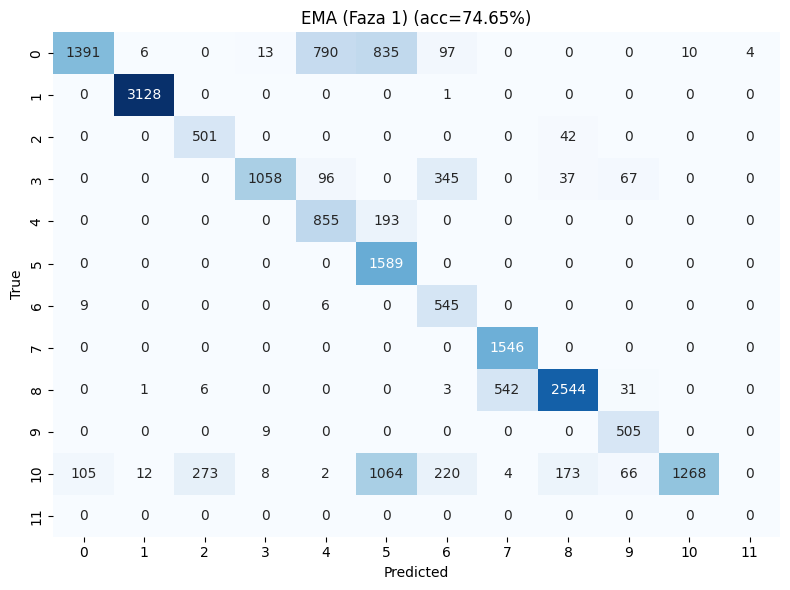

C:\Users\Ja\AppData\Local\Temp\ipykernel_13564\1840610129.py:14: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  m.load_state_dict(torch.load(ckpt_path, map_location=device))



=== SWA (Faza 1) (best_resnet_p1_swa.pth): acc=75.38% ===
              precision    recall  f1-score   support

           0      0.868     0.461     0.602      3146
           1      0.998     0.986     0.992      3129
           2      0.825     0.383     0.523       543
           3      0.930     0.943     0.937      1603
           4      0.493     0.927     0.644      1048
           5      0.476     1.000     0.645      1589
           6      0.641     0.939     0.762       560
           7      0.720     1.000     0.837      1546
           8      0.791     0.772     0.781      3127
           9      0.680     0.981     0.803       514
          10      0.994     0.397     0.567      3195
          11      0.000     0.000     0.000         0

    accuracy                          0.754     20000
   macro avg      0.701     0.732     0.675     20000
weighted avg      0.827     0.754     0.744     20000



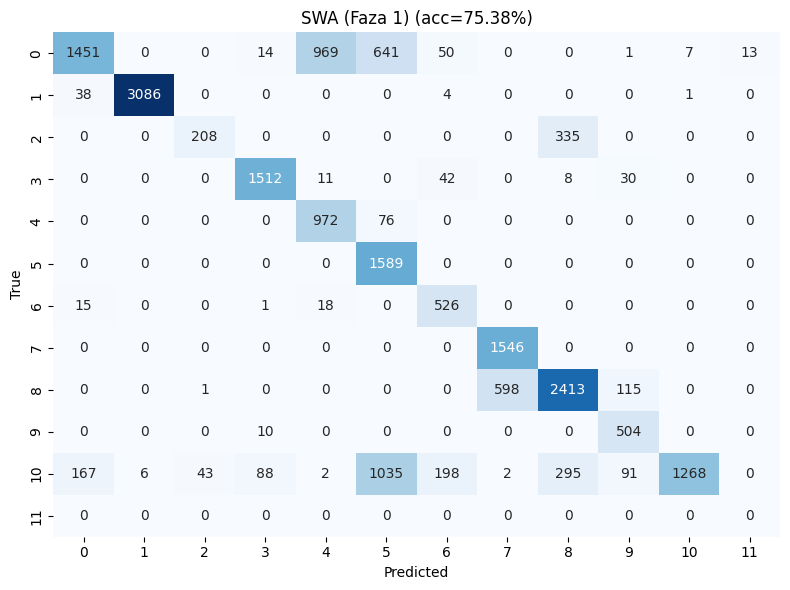


Podsumowanie Faza 1: EMA=74.65, SWA=75.375


In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

test_loader_eval = DataLoader(Memmap_TestDataset(), batch_size=256, shuffle=False,
                              pin_memory=True, num_workers=0)


def evaluate_checkpoint(ckpt_path, label):
    if not os.path.exists(ckpt_path):
        print(f"[skip] {ckpt_path} nie znaleziony")
        return None, None
    m = PIAN_ResNet(num_classes=NUM_CLASSES).to(device)
    m.load_state_dict(torch.load(ckpt_path, map_location=device))
    m.eval()
    all_preds, all_labels = [], []
    with torch.no_grad(), torch.amp.autocast('cuda'):
        for x, y in test_loader_eval:
            x = x.to(device, non_blocking=True)
            outputs = m(apply_eval_transform(x))
            _, preds = torch.max(outputs, dim=1)
            all_preds.append(preds.cpu().numpy())
            all_labels.append(y.numpy())
    all_preds = np.concatenate(all_preds)
    all_labels = np.concatenate(all_labels)
    acc = 100.0 * (all_preds == all_labels).mean()
    print(f"\n=== {label} ({ckpt_path}): acc={acc:.2f}% ===")
    print(classification_report(all_labels, all_preds, digits=3, zero_division=0))
    cm = confusion_matrix(all_labels, all_preds, labels=list(range(NUM_CLASSES)))
    fig, ax = plt.subplots(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False)
    ax.set_title(f'{label} (acc={acc:.2f}%)')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
    plt.tight_layout()
    plt.show()
    del m
    return acc, cm


_acc_ema, _ = evaluate_checkpoint('best_resnet_p1_ema.pth', 'EMA (Faza 1)')
_acc_swa, _ = evaluate_checkpoint('best_resnet_p1_swa.pth', 'SWA (Faza 1)')
print(f"\nPodsumowanie Faza 1: EMA={_acc_ema}, SWA={_acc_swa}")

## Faza 2: Snapshot Ensembling + CutMix-1D + rozszerzone TTA

Cel: 80%+ z ensemble + TTA bez kosztu trenowania 3 osobnych modeli od zera.

- `CosineAnnealingWarmRestarts(T_0=20)` — 5 cosine cykli na 100 epok
- Co 20 epok zapisujemy snapshot (`snapshot_p2_e20.pth` ... `snapshot_p2_e100.pth`)
- Alternacja **MixUp** / **CutMix-1D** 50/50
- Reszta augmentacji jak w Fazie 1
- Inferencja: 10 TTA wariantów × 5 snapshotów = uśrednienie 50 softmaxów per próbka

In [7]:
EPOCHS_P2 = 100
SNAPSHOT_PERIOD = 20
T_0 = SNAPSHOT_PERIOD
LR_MAX_P2 = 1e-3
CUTMIX_PROB = 0.5
SEED_P2 = 2024

torch.manual_seed(SEED_P2)
np.random.seed(SEED_P2)

train_loader_p2 = DataLoader(Memmap_TrainDataset(), batch_size=BATCH_SIZE, shuffle=True,
                              pin_memory=True, num_workers=0, drop_last=True)
test_loader_p2 = DataLoader(Memmap_TestDataset(), batch_size=BATCH_SIZE, shuffle=False,
                             pin_memory=True, num_workers=0)
steps_per_epoch_p2 = len(train_loader_p2)

model_p2 = PIAN_ResNet(num_classes=NUM_CLASSES).to(device)
optimizer_p2 = optim.AdamW(model_p2.parameters(), lr=LR_MAX_P2, weight_decay=WEIGHT_DECAY)
scheduler_p2 = lr_scheduler.CosineAnnealingWarmRestarts(
    optimizer_p2, T_0=T_0, T_mult=1, eta_min=1e-6
)
scaler_p2 = torch.amp.GradScaler('cuda')
criterion_p2 = nn.CrossEntropyLoss(weight=cb_weights, label_smoothing=LABEL_SMOOTHING)

snapshot_paths = []
history_p2 = []

for epoch in range(EPOCHS_P2):
    epoch_t0 = time.time()
    model_p2.train()
    running_loss, n_batches = 0.0, 0

    pbar = tqdm(train_loader_p2, desc=f"P2 E{epoch+1:03d}/{EPOCHS_P2}", leave=False)
    for batch_i, (inputs, labels) in enumerate(pbar):
        inputs = inputs.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        optimizer_p2.zero_grad(set_to_none=True)

        with torch.amp.autocast('cuda'):
            with torch.no_grad():
                inputs = apply_train_augmentations(inputs)
            if np.random.rand() < CUTMIX_PROB:
                inputs, t_a, t_b, lam = cutmix_1d(inputs, labels, alpha=1.0)
            else:
                inputs, t_a, t_b, lam = mixup_data(inputs, labels, alpha=MIXUP_ALPHA)
            outputs = model_p2(inputs)
            loss = mixup_criterion(criterion_p2, outputs, t_a, t_b, lam)

        scaler_p2.scale(loss).backward()
        scaler_p2.unscale_(optimizer_p2)
        torch.nn.utils.clip_grad_norm_(model_p2.parameters(), max_norm=GRAD_CLIP)
        scaler_p2.step(optimizer_p2)
        scaler_p2.update()
        scheduler_p2.step(epoch + batch_i / steps_per_epoch_p2)

        running_loss += loss.item()
        n_batches += 1
        pbar.set_postfix(loss=f"{running_loss / n_batches:.4f}")

    # Walidacja
    model_p2.eval()
    correct, total = 0, 0
    with torch.no_grad(), torch.amp.autocast('cuda'):
        for x, y in test_loader_p2:
            x = x.to(device, non_blocking=True)
            y = y.to(device, non_blocking=True)
            outputs = model_p2(apply_eval_transform(x))
            _, preds = torch.max(outputs, dim=1)
            correct += (preds == y).sum().item()
            total += y.size(0)
    val_acc = 100.0 * correct / total

    epoch_t = time.time() - epoch_t0
    cur_lr = optimizer_p2.param_groups[0]['lr']
    print(f"E{epoch+1:03d}/{EPOCHS_P2} {epoch_t:.1f}s LR={cur_lr:.2e} "
          f"loss={running_loss/n_batches:.4f} acc={val_acc:.2f}%")
    history_p2.append({'epoch': epoch+1, 'loss': running_loss/n_batches,
                       'acc': val_acc, 'lr': cur_lr})

    if (epoch + 1) % SNAPSHOT_PERIOD == 0:
        snap_path = f'snapshot_p2_e{epoch+1}.pth'
        torch.save(model_p2.state_dict(), snap_path)
        snapshot_paths.append(snap_path)
        print(f"   -> Snapshot zapisany: {snap_path} ({val_acc:.2f}%)")

print(f"\n=== FAZA 2 KONIEC ===")
print(f"Snapshoty: {snapshot_paths}")

E001/100 82.1s LR=9.94e-04 loss=1.9350 acc=40.16%


E002/100 79.3s LR=9.76e-04 loss=1.3568 acc=57.63%


E003/100 77.8s LR=9.46e-04 loss=1.2694 acc=52.80%


E004/100 64.6s LR=9.05e-04 loss=1.2068 acc=66.67%


E005/100 60.0s LR=8.54e-04 loss=1.1159 acc=63.40%


...

E096/100 38.3s LR=9.66e-05 loss=1.0111 acc=70.36%


E097/100 39.1s LR=5.56e-05 loss=0.9803 acc=71.16%


E098/100 24.4s LR=2.56e-05 loss=0.9993 acc=71.34%


E099/100 24.5s LR=7.21e-06 loss=0.9703 acc=70.78%


E100/100 40.1s LR=1.00e-06 loss=0.9811 acc=70.86%
   -> Snapshot zapisany: snapshot_p2_e100.pth (70.86%)

=== FAZA 2 KONIEC ===
Snapshoty: ['snapshot_p2_e20.pth', 'snapshot_p2_e40.pth', 'snapshot_p2_e60.pth', 'snapshot_p2_e80.pth', 'snapshot_p2_e100.pth']


In [ ]:
snapshot_files = sorted([f for f in os.listdir('.')
                          if f.startswith('snapshot_p2_e') and f.endswith('.pth')])
print(f"Snapshoty Fazy 2: {snapshot_files}")

ensemble_models = []
for path in snapshot_files:
    m = PIAN_ResNet(num_classes=NUM_CLASSES).to(device)
    m.load_state_dict(torch.load(path, map_location=device))
    m.eval()
    ensemble_models.append(m)

INCLUDE_P1_EMA = True
if INCLUDE_P1_EMA and os.path.exists('best_resnet_p1_ema.pth'):
    m = PIAN_ResNet(num_classes=NUM_CLASSES).to(device)
    m.load_state_dict(torch.load('best_resnet_p1_ema.pth', map_location=device))
    m.eval()
    ensemble_models.append(m)
    print("   + EMA z Fazy 1 dołączony")

print(f"\nRazem modeli w ensemble: {len(ensemble_models)}")

test_loader_p2 = DataLoader(Memmap_TestDataset(), batch_size=128, shuffle=False,
                             pin_memory=True, num_workers=0)

all_preds, all_labels = [], []
n_variants = None
with torch.no_grad(), torch.amp.autocast('cuda'):
    for inputs, labels in tqdm(test_loader_p2, desc="Ensemble + TTA"):
        inputs = inputs.to(device, non_blocking=True)
        labels_cpu = labels.numpy()
        variants = tta_variants(inputs)
        if n_variants is None:
            n_variants = len(variants)
        agg = None
        for v in variants:
            for m in ensemble_models:
                logits = m(v)
                soft = torch.softmax(logits, dim=1)
                agg = soft if agg is None else agg + soft
        agg = agg / (len(variants) * len(ensemble_models))
        _, preds = torch.max(agg, dim=1)
        all_preds.append(preds.cpu().numpy())
        all_labels.append(labels_cpu)

all_preds = np.concatenate(all_preds)
all_labels = np.concatenate(all_labels)
ensemble_acc = 100.0 * (all_preds == all_labels).mean()
print(f"\n=== ENSEMBLE + TTA acc: {ensemble_acc:.2f}% ===")
print(f"   ({len(ensemble_models)} modeli x {n_variants} TTA = {len(ensemble_models) * n_variants} predykcji per probka)")
print(classification_report(all_labels, all_preds, digits=3, zero_division=0))

Snapshoty Fazy 2: ['snapshot_p2_e100.pth', 'snapshot_p2_e20.pth', 'snapshot_p2_e40.pth', 'snapshot_p2_e60.pth', 'snapshot_p2_e80.pth']


C:\Users\Ja\AppData\Local\Temp\ipykernel_13564\3033775683.py:8: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  m.load_state_dict(torch.load(path, map_location=device))
C:\Use

   + EMA z Fazy 1 dołączony

Razem modeli w ensemble: 6


Ensemble + TTA: 100%|██████████| 157/157 [00:51<00:00,  3.04it/s]


=== ENSEMBLE + TTA acc: 71.24% ===
   (6 modeli x 10 TTA = 60 predykcji per probka)
              precision    recall  f1-score   support

           0      0.781     0.404     0.533      3146
           1      0.989     1.000     0.994      3129
           2      0.647     0.317     0.425       543
           3      0.941     0.714     0.812      1603
           4      0.382     0.872     0.532      1048
           5      0.474     1.000     0.643      1589
           6      0.410     0.771     0.536       560
           7      0.749     0.998     0.856      1546
           8      0.801     0.813     0.807      3127
           9      0.741     0.994     0.849       514
          10      0.997     0.314     0.477      3195

    accuracy                          0.712     20000
   macro avg      0.719     0.745     0.678     20000
weighted avg      0.801     0.712     0.700     20000



## Faza 2 (opcjonalne rozszerzenia)

Dwie dodatkowe ścieżki, jeśli ensemble + TTA z poprzedniej komórki nie zbije celu 80%+:

1. **`PIAN_ResNet_Deep`** — 4 bloki + stochastic depth (drop_path=0.1), parametry ~2.8M zamiast ~1M.
2. **Self-distillation** — fresh `PIAN_ResNet` uczący się z miękkich predykcji ensemble (KL divergence) + ground truth (CE), waga 0.7/0.3, T=4. Cel: jeden model bliski jakości ensemble (do regresji w Fazie 2 projektu).

In [9]:
class DropPath1D(nn.Module):
    def __init__(self, drop_prob=0.0):
        super().__init__()
        self.drop_prob = drop_prob

    def forward(self, x):
        if self.drop_prob == 0.0 or not self.training:
            return x
        keep_prob = 1.0 - self.drop_prob
        shape = (x.shape[0],) + (1,) * (x.ndim - 1)
        random_tensor = keep_prob + torch.rand(shape, dtype=x.dtype, device=x.device)
        random_tensor.floor_()
        return x.div(keep_prob) * random_tensor


class ResNetBlock1D_DP(nn.Module):
    """ResNet block z stochastic depth (DropPath na rezydualnej sciezce)."""
    def __init__(self, in_channels, out_channels, stride=1, drop_path=0.0):
        super().__init__()
        self.conv1 = nn.Conv1d(in_channels, out_channels, kernel_size=7,
                                stride=stride, padding=3, bias=False)
        self.bn1 = nn.BatchNorm1d(out_channels)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv1d(out_channels, out_channels, kernel_size=7,
                                stride=1, padding=3, bias=False)
        self.bn2 = nn.BatchNorm1d(out_channels)
        self.se = SEBlock1D(out_channels)
        self.drop_path = DropPath1D(drop_path)

        self.downsample = nn.Sequential()
        if stride != 1 or in_channels != out_channels:
            self.downsample = nn.Sequential(
                nn.Conv1d(in_channels, out_channels, kernel_size=1,
                          stride=stride, bias=False),
                nn.BatchNorm1d(out_channels)
            )

    def forward(self, x):
        identity = self.downsample(x)
        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)
        out = self.conv2(out)
        out = self.bn2(out)
        out = self.se(out)
        out = self.drop_path(out) + identity
        out = self.relu(out)
        return out


class PIAN_ResNet_Deep(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES, drop_path_rate=0.1, fc_dropout=0.3):
        super().__init__()
        self.conv1 = nn.Conv1d(1, 32, kernel_size=21, stride=4, padding=10, bias=False)
        self.bn1 = nn.BatchNorm1d(32)
        self.relu = nn.ReLU(inplace=True)
        self.maxpool = nn.MaxPool1d(kernel_size=4, stride=4)

        # 4 stages: 32 -> 64 -> 128 -> 256 -> 384
        dp_rates = [drop_path_rate * i / 3.0 for i in range(4)]
        self.layer1 = ResNetBlock1D_DP(32, 64, stride=2, drop_path=dp_rates[0])
        self.layer2 = ResNetBlock1D_DP(64, 128, stride=2, drop_path=dp_rates[1])
        self.layer3 = ResNetBlock1D_DP(128, 256, stride=2, drop_path=dp_rates[2])
        self.layer4 = ResNetBlock1D_DP(256, 384, stride=2, drop_path=dp_rates[3])

        self.dropout1d = nn.Dropout1d(p=0.1)
        self.global_pool = nn.AdaptiveAvgPool1d(1)
        self.dropout = nn.Dropout(fc_dropout)
        self.fc = nn.Linear(384, num_classes)

    def forward(self, x):
        if x.dim() == 2:
            x = x.unsqueeze(1)
        x = self.maxpool(self.relu(self.bn1(self.conv1(x))))
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        x = self.dropout1d(x)
        x = self.global_pool(x).view(x.size(0), -1)
        x = self.dropout(x)
        x = self.fc(x)
        return x


_md = PIAN_ResNet_Deep()
print(f"PIAN_ResNet_Deep params: {count_params(_md):,}")
with torch.no_grad():
    _yd = _md(torch.zeros(2, SEQ_LEN))
    print(f"Forward smoke test OK -> output {_yd.shape}")
del _md, _yd

print("\n[INFO] Aby trenowac PIAN_ResNet_Deep, skopiuj komórkę treningową Fazy 1\n"
      "       i podmien `PIAN_ResNet(...)` -> `PIAN_ResNet_Deep(...)`, BATCH_SIZE 256 -> 128.")

PIAN_ResNet_Deep params: 2,833,516
Forward smoke test OK -> output torch.Size([2, 12])

[INFO] Aby trenowac PIAN_ResNet_Deep, skopiuj komórkę treningową Fazy 1
       i podmien `PIAN_ResNet(...)` -> `PIAN_ResNet_Deep(...)`, BATCH_SIZE 256 -> 128.


In [11]:
EPOCHS = 100
BATCH_SIZE = 128
LR_MAX = 1e-3
WEIGHT_DECAY = 0.01
MIXUP_ALPHA = 0.2
SWA_START_FRAC = 0.6
EMA_DECAY = 0.9995
LABEL_SMOOTHING = 0.1
GRAD_CLIP = 2.0
SEED_P1 = 42

torch.manual_seed(SEED_P1)
np.random.seed(SEED_P1)

train_dataset = Memmap_TrainDataset()
test_dataset = Memmap_TestDataset()

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          pin_memory=True, num_workers=0, drop_last=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                         pin_memory=True, num_workers=0)

cb_weights = build_cb_weights(train_dataset.labels, NUM_CLASSES, beta=0.9999, device=device)
print(f"CB-weights: {cb_weights.cpu().numpy().round(3)}")

model = PIAN_ResNet_Deep(num_classes=NUM_CLASSES).to(device)
criterion = nn.CrossEntropyLoss(weight=cb_weights, label_smoothing=LABEL_SMOOTHING)
optimizer = optim.AdamW(model.parameters(), lr=LR_MAX, weight_decay=WEIGHT_DECAY)

steps_per_epoch = len(train_loader)
swa_start_epoch = int(EPOCHS * SWA_START_FRAC)
# OneCycleLR domyka cykl dokladnie na progu SWA, zeby LR osiagnal minimum
# zanim SWALR wezmie palke z swa_lr=1e-4 (anneal_epochs=5).
scheduler = lr_scheduler.OneCycleLR(
    optimizer, max_lr=LR_MAX, total_steps=swa_start_epoch * steps_per_epoch,
    pct_start=0.1, anneal_strategy='cos', div_factor=25.0, final_div_factor=1e3,
)
scaler = torch.amp.GradScaler('cuda')
ema = ModelEMA(model, decay=EMA_DECAY)
swa_model = AveragedModel(model)
swa_scheduler = SWALR(optimizer, swa_lr=1e-4, anneal_epochs=5, anneal_strategy='cos')
swa_active = False

print(f"\n--- FAZA 1: trening {EPOCHS} epok, SWA od epoki {swa_start_epoch+1} ---")
best_ema_acc = 0.0
history = []

for epoch in range(EPOCHS):
    epoch_t0 = time.time()
    model.train()
    running_loss, n_batches = 0.0, 0

    pbar = tqdm(train_loader, desc=f"P1 E{epoch+1:03d}/{EPOCHS}", leave=False)
    for inputs, labels in pbar:
        inputs = inputs.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast('cuda'):
            with torch.no_grad():
                inputs = apply_train_augmentations(inputs)
            inputs, t_a, t_b, lam = mixup_data(inputs, labels, alpha=MIXUP_ALPHA)
            outputs = model(inputs)
            loss = mixup_criterion(criterion, outputs, t_a, t_b, lam)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=GRAD_CLIP)
        scaler.step(optimizer)
        scaler.update()

        if epoch < swa_start_epoch:
            scheduler.step()

        ema.update(model)
        running_loss += loss.item()
        n_batches += 1
        pbar.set_postfix(loss=f"{running_loss / n_batches:.4f}")

    if epoch >= swa_start_epoch:
        swa_model.update_parameters(model)
        swa_scheduler.step()
        swa_active = True

    # Walidacja: EMA + raw
    def _eval(model_obj):
        model_obj.eval()
        correct, total = 0, 0
        with torch.no_grad(), torch.amp.autocast('cuda'):
            for x, y in test_loader:
                x = x.to(device, non_blocking=True)
                y = y.to(device, non_blocking=True)
                outputs = model_obj(apply_eval_transform(x))
                _, preds = torch.max(outputs, dim=1)
                correct += (preds == y).sum().item()
                total += y.size(0)
        return 100.0 * correct / total

    ema_acc = _eval(ema.ema)
    raw_acc = _eval(model)

    epoch_t = time.time() - epoch_t0
    cur_lr = optimizer.param_groups[0]['lr']
    swa_tag = " [SWA]" if swa_active else ""
    print(f"E{epoch+1:03d}/{EPOCHS} {epoch_t:.1f}s LR={cur_lr:.2e} "
          f"loss={running_loss/n_batches:.4f} | raw={raw_acc:.2f}% ema={ema_acc:.2f}%{swa_tag}")
    history.append({'epoch': epoch+1, 'loss': running_loss/n_batches,
                    'raw_acc': raw_acc, 'ema_acc': ema_acc, 'lr': cur_lr})

    if ema_acc > best_ema_acc:
        best_ema_acc = ema_acc
        torch.save(ema.ema.state_dict(), 'best_resnet_p1_ema.pth')
        print(f"   -> Nowy rekord EMA: {best_ema_acc:.2f}%")

# --- Finalizacja SWA: re-update BN na danych treningowych ---
print("\n--- Finalizacja SWA: re-estymacja statystyk BN ---")
for m_ in swa_model.modules():
    if isinstance(m_, nn.BatchNorm1d):
        m_.reset_running_stats()
        m_.momentum = None

swa_model.train()
with torch.no_grad():
    for x, _ in tqdm(train_loader, desc="SWA BN update"):
        x = x.to(device, non_blocking=True)
        with torch.amp.autocast('cuda'):
            _ = swa_model(apply_eval_transform(x))

swa_model.eval()
swa_acc = 0.0
correct, total = 0, 0
with torch.no_grad(), torch.amp.autocast('cuda'):
    for x, y in test_loader:
        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)
        outputs = swa_model(apply_eval_transform(x))
        _, preds = torch.max(outputs, dim=1)
        correct += (preds == y).sum().item()
        total += y.size(0)
swa_acc = 100.0 * correct / total
torch.save(swa_model.module.state_dict(), 'best_resnet_p1_swa.pth')

print(f"\n=== FAZA 1 KONIEC ===")
print(f"Best EMA:   {best_ema_acc:.2f}%  -> best_resnet_p1_ema.pth")
print(f"SWA final:  {swa_acc:.2f}%  -> best_resnet_p1_swa.pth")

CB-weights: [0.827 0.568 1.355 1.156 1.015 0.827 1.355 1.156 0.568 1.355 0.664 1.156]

--- FAZA 1: trening 100 epok, SWA od epoki 61 ---


E001/100 54.7s LR=1.04e-04 loss=2.1564 | raw=56.34% ema=7.73%
   -> Nowy rekord EMA: 7.73%


E002/100 48.4s LR=2.80e-04 loss=1.3036 | raw=56.80% ema=7.73%


E003/100 48.5s LR=5.20e-04 loss=1.0738 | raw=68.00% ema=7.73%


E004/100 57.8s LR=7.60e-04 loss=1.0191 | raw=67.57% ema=7.73%


...

E098/100 49.0s LR=1.00e-04 loss=0.8271 | raw=72.10% ema=71.85% [SWA]


E099/100 49.1s LR=1.00e-04 loss=0.8311 | raw=72.75% ema=71.91% [SWA]


E100/100 73.8s LR=1.00e-04 loss=0.8153 | raw=72.61% ema=72.12% [SWA]

--- Finalizacja SWA: re-estymacja statystyk BN ---


SWA BN update: 100%|██████████| 390/390 [00:33<00:00, 11.54it/s]



=== FAZA 1 KONIEC ===
Best EMA:   74.57%  -> best_resnet_p1_ema.pth
SWA final:  72.86%  -> best_resnet_p1_swa.pth


In [15]:
# === FAZA 2.5: SELF-DISTILLATION ===
# Student PIAN_ResNet uczy sie z ensemble (snapshoty + EMA) jako teacher.
# Pre-compute soft labels teacher na calym train (tylko log1p, bez augmentacji).

DISTILL_T = 4.0
DISTILL_ALPHA = 0.7  # waga KL od teacher
DISTILL_EPOCHS = 60
DISTILL_LR = 1e-3

def _build_model_for_ckpt(ckpt_path):
    """Wykrywa architekture z state_dict i buduje pasujacy model."""
    sd = torch.load(ckpt_path, map_location='cpu', weights_only=True)
    is_deep = any(k.startswith('layer4.') for k in sd.keys())
    if is_deep:
        m = PIAN_ResNet_Deep(num_classes=NUM_CLASSES).to(device)
        arch = 'Deep'
    else:
        m = PIAN_ResNet(num_classes=NUM_CLASSES).to(device)
        arch = 'Regular'
    m.load_state_dict({k: v.to(device) for k, v in sd.items()})
    m.eval()
    for p in m.parameters():
        p.requires_grad_(False)
    return m, arch


snapshot_files = sorted([f for f in os.listdir('.')
                          if f.startswith('snapshot_p2_e') and f.endswith('.pth')])
teacher_models = []
for path in snapshot_files:
    m, arch = _build_model_for_ckpt(path)
    teacher_models.append(m)
    print(f"   + {path}: {arch}")
if os.path.exists('best_resnet_p1_ema.pth'):
    m, arch = _build_model_for_ckpt('best_resnet_p1_ema.pth')
    teacher_models.append(m)
    print(f"   + best_resnet_p1_ema.pth: {arch}")
if os.path.exists('best_resnet_p1_swa.pth'):
    m, arch = _build_model_for_ckpt('best_resnet_p1_swa.pth')
    teacher_models.append(m)
    print(f"   + best_resnet_p1_swa.pth: {arch}")
print(f"Teacher ensemble: {len(teacher_models)} modeli (heterogeniczny)")
assert len(teacher_models) > 0, "Brak modeli teacher \u2014 wytrenuj najpierw Faze 1 i/lub Faze 2."

torch.manual_seed(7)
np.random.seed(7)

train_loader_d = DataLoader(Memmap_TrainDataset(), batch_size=BATCH_SIZE, shuffle=True,
                             pin_memory=True, num_workers=0, drop_last=True)
test_loader_d = DataLoader(Memmap_TestDataset(), batch_size=BATCH_SIZE, shuffle=False,
                            pin_memory=True, num_workers=0)

student = PIAN_ResNet(num_classes=NUM_CLASSES).to(device)
optimizer_d = optim.AdamW(student.parameters(), lr=DISTILL_LR, weight_decay=WEIGHT_DECAY)
scheduler_d = lr_scheduler.OneCycleLR(
    optimizer_d, max_lr=DISTILL_LR, total_steps=DISTILL_EPOCHS * len(train_loader_d),
    pct_start=0.1, anneal_strategy='cos'
)
scaler_d = torch.amp.GradScaler('cuda')
ce_loss = nn.CrossEntropyLoss(weight=cb_weights, label_smoothing=LABEL_SMOOTHING)

best_distill_acc = 0.0
for epoch in range(DISTILL_EPOCHS):
    epoch_t0 = time.time()
    student.train()
    running = 0.0
    n_b = 0

    pbar = tqdm(train_loader_d, desc=f"Distill E{epoch+1:03d}/{DISTILL_EPOCHS}", leave=False)
    for inputs, labels in pbar:
        inputs = inputs.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        optimizer_d.zero_grad(set_to_none=True)

        with torch.amp.autocast('cuda'):
            with torch.no_grad():
                inputs_aug = apply_train_augmentations(inputs.clone())
                inputs_clean = apply_eval_transform(inputs)
                # Teacher na czystym (bez augmentacji)
                teacher_soft = None
                for tm in teacher_models:
                    t_logits = tm(inputs_clean) / DISTILL_T
                    t_soft = torch.softmax(t_logits, dim=1)
                    teacher_soft = t_soft if teacher_soft is None else teacher_soft + t_soft
                teacher_soft = teacher_soft / len(teacher_models)

            student_logits = student(inputs_aug)
            log_student = F.log_softmax(student_logits / DISTILL_T, dim=1)
            kl = F.kl_div(log_student, teacher_soft, reduction='batchmean') * (DISTILL_T ** 2)
            ce = ce_loss(student_logits, labels)
            loss = DISTILL_ALPHA * kl + (1.0 - DISTILL_ALPHA) * ce

        scaler_d.scale(loss).backward()
        scaler_d.unscale_(optimizer_d)
        torch.nn.utils.clip_grad_norm_(student.parameters(), max_norm=GRAD_CLIP)
        scaler_d.step(optimizer_d)
        scaler_d.update()
        scheduler_d.step()

        running += loss.item()
        n_b += 1
        pbar.set_postfix(loss=f"{running/n_b:.4f}")

    student.eval()
    correct, total = 0, 0
    with torch.no_grad(), torch.amp.autocast('cuda'):
        for x, y in test_loader_d:
            x = x.to(device, non_blocking=True)
            y = y.to(device, non_blocking=True)
            outputs = student(apply_eval_transform(x))
            _, preds = torch.max(outputs, dim=1)
            correct += (preds == y).sum().item()
            total += y.size(0)
    val_acc = 100.0 * correct / total
    epoch_t = time.time() - epoch_t0
    print(f"Distill E{epoch+1:03d}/{DISTILL_EPOCHS} {epoch_t:.1f}s loss={running/n_b:.4f} acc={val_acc:.2f}%")

    if val_acc > best_distill_acc:
        best_distill_acc = val_acc
        torch.save(student.state_dict(), 'best_resnet_distilled.pth')
        print(f"   -> Nowy rekord student: {best_distill_acc:.2f}%")

print(f"\n=== SELF-DISTILLATION KONIEC ===")
print(f"Best student: {best_distill_acc:.2f}% -> best_resnet_distilled.pth")

   + snapshot_p2_e100.pth: Regular
   + snapshot_p2_e20.pth: Regular
   + snapshot_p2_e40.pth: Regular
   + snapshot_p2_e60.pth: Regular
   + snapshot_p2_e80.pth: Regular
   + best_resnet_p1_ema.pth: Deep
   + best_resnet_p1_swa.pth: Deep
Teacher ensemble: 7 modeli (heterogeniczny)


Distill E001/60 98.8s loss=1.3411 acc=44.45%
   -> Nowy rekord student: 44.45%


Distill E002/60 91.3s loss=0.8882 acc=51.56%
   -> Nowy rekord student: 51.56%


Distill E003/60 83.0s loss=0.4608 acc=54.20%
   -> Nowy rekord student: 54.20%


Distill E004/60 86.9s loss=0.3308 acc=57.40%
   -> Nowy rekord student: 57.40%


...

Distill E056/60 84.8s loss=0.2154 acc=69.45%


Distill E057/60 86.1s loss=0.2154 acc=69.75%


Distill E058/60 85.6s loss=0.2155 acc=69.76%


Distill E059/60 77.4s loss=0.2156 acc=69.84%


Distill E060/60 83.4s loss=0.2155 acc=69.92%

=== SELF-DISTILLATION KONIEC ===
Best student: 72.00% -> best_resnet_distilled.pth


## Eksperyment FOCAL: Focal Loss + WeightedRandomSampler

Cel: naprawić dwa wzorce widoczne w confusion matrix Fazy 1:

| Klasa | Obserwacja w EMA Faza 1 | Co chcemy uzyskać |
|-------|--------------------------|-------------------|
| 5     | precision **0.43**, recall 1.00 (over-prediction) | model przestaje "strzelać klasą 5" |
| 6     | precision 0.45, recall 0.97 (over-prediction)     | jak wyżej |
| 10    | precision 0.99, recall **0.40** (under-prediction)| model częściej rozpoznaje klasę 10 |
| 0     | precision 0.92, recall 0.46 (under-prediction)    | jak wyżej |

Diagnoza: **zła kalibracja confidence**. CB-loss z `beta=0.9999` przy imbalance 3:1 jest praktycznie no-op (waga max:min = 2.4×).

Dwa narzędzia:

1. **Focal Loss (γ=2.0)** — automatycznie de-prioryzuje easy examples. Klasy z `recall=1.0` mają niski focal loss → przestają dominować gradient.
2. **`WeightedRandomSampler` z wagami `1/sqrt(count)`** — łagodniejszy niż naiwny `1/count`, ale wciąż realnie balansuje rozkład batchu. To bezpieczna wersja tego, co stary baseline z `testing.ipynb` (78.75%) miał.

Reszta pipeline'u zostaje (EMA, SWA, Dropout1d, MixUp, augmentacje), żeby izolować efekt zmiany lossu/samplera.

Hiperparametry (różnice względem Fazy 1):
- `EPOCHS = 80` (focal+sampler konwerguje szybciej, nie potrzeba 100)
- `weight_decay = 0.005` (focal sam działa jako regularyzator)
- `MixUp α = 0.3` (środek między 0.2 a 0.4)
- `SWA start = 65%` epok = 52
- Seed = 1337 (świeży, niekolidujący z 42/2024)

Zapis: `best_resnet_focal_ema.pth`, `best_resnet_focal_swa.pth`.

In [16]:
from torch.utils.data import WeightedRandomSampler


class FocalLoss(nn.Module):
    """Multi-class Focal Loss z opcjonalnym label smoothing.

    FL(p_t) = - (1 - p_t)^gamma * log(p_t)
    Implementacja respektuje label_smoothing: targets sa rozmazane,
    a focal weight liczone z prawdopodobienstwa TRUE klasy.
    """
    def __init__(self, gamma=2.0, label_smoothing=0.1, alpha=None, reduction='mean'):
        super().__init__()
        self.gamma = gamma
        self.label_smoothing = label_smoothing
        self.alpha = alpha  # opcjonalny tensor wag per-klasa
        self.reduction = reduction

    def forward(self, logits, target):
        log_probs = F.log_softmax(logits, dim=-1)
        n_classes = logits.size(-1)

        if self.label_smoothing > 0:
            with torch.no_grad():
                smooth_target = torch.full_like(
                    log_probs, self.label_smoothing / max(n_classes - 1, 1)
                )
                smooth_target.scatter_(1, target.unsqueeze(1), 1 - self.label_smoothing)
            ce = -(smooth_target * log_probs).sum(dim=-1)
        else:
            ce = F.nll_loss(log_probs, target, reduction='none')

        # Focal weight: pt = prawdopodobienstwo TRUE klasy
        with torch.no_grad():
            pt = log_probs.gather(1, target.unsqueeze(1)).squeeze(1).exp().clamp(1e-7, 1.0)
        focal_weight = (1.0 - pt) ** self.gamma
        loss = focal_weight * ce

        if self.alpha is not None:
            alpha_t = self.alpha[target]
            loss = alpha_t * loss

        if self.reduction == 'mean':
            return loss.mean()
        elif self.reduction == 'sum':
            return loss.sum()
        return loss


# === Konfiguracja eksperymentu ===
EPOCHS_F = 80
BATCH_SIZE_F = 256
LR_MAX_F = 1e-3
WEIGHT_DECAY_F = 0.005
MIXUP_ALPHA_F = 0.3
GAMMA_F = 2.0
SWA_START_FRAC_F = 0.65
EMA_DECAY_F = 0.9995
LABEL_SMOOTHING_F = 0.1
GRAD_CLIP_F = 2.0
SEED_F = 1337

torch.manual_seed(SEED_F)
np.random.seed(SEED_F)

train_dataset_f = Memmap_TrainDataset()
test_dataset_f = Memmap_TestDataset()

# WeightedRandomSampler z wagami 1/sqrt(count) - lagodniejszy niz 1/count
class_counts_f = np.bincount(train_dataset_f.labels, minlength=NUM_CLASSES).astype(np.float64)
class_weights_arr = 1.0 / np.sqrt(np.maximum(class_counts_f, 1.0))
sample_weights_f = class_weights_arr[train_dataset_f.labels]
sampler_f = WeightedRandomSampler(
    weights=torch.DoubleTensor(sample_weights_f),
    num_samples=len(sample_weights_f),
    replacement=True,
)

train_loader_f = DataLoader(
    train_dataset_f, batch_size=BATCH_SIZE_F, sampler=sampler_f,
    pin_memory=True, num_workers=0, drop_last=True
)
test_loader_f = DataLoader(
    test_dataset_f, batch_size=BATCH_SIZE_F, shuffle=False,
    pin_memory=True, num_workers=0
)

print(f"Liczebnosci klas:    {class_counts_f.astype(int)}")
print(f"Wagi 1/sqrt:         {class_weights_arr.round(4)}")
print(f"Stosunek max/min wag: {class_weights_arr.max() / class_weights_arr.min():.2f}")
print(f"   (vs WeightedRandomSampler 1/count: {(1.0 / class_counts_f).max() / (1.0 / class_counts_f).min():.2f}x)")
print(f"   (vs CB-loss beta=0.9999: ~2.4x)")

model_f = PIAN_ResNet(num_classes=NUM_CLASSES).to(device)
criterion_f = FocalLoss(gamma=GAMMA_F, label_smoothing=LABEL_SMOOTHING_F)
optimizer_f = optim.AdamW(model_f.parameters(), lr=LR_MAX_F, weight_decay=WEIGHT_DECAY_F)

steps_per_epoch_f = len(train_loader_f)
swa_start_epoch_f = int(EPOCHS_F * SWA_START_FRAC_F)
scheduler_f = lr_scheduler.OneCycleLR(
    optimizer_f, max_lr=LR_MAX_F,
    total_steps=swa_start_epoch_f * steps_per_epoch_f,
    pct_start=0.1, anneal_strategy='cos', div_factor=25.0, final_div_factor=1e3,
)
scaler_f = torch.amp.GradScaler('cuda')
ema_f = ModelEMA(model_f, decay=EMA_DECAY_F)
swa_model_f = AveragedModel(model_f)
swa_scheduler_f = SWALR(optimizer_f, swa_lr=1e-4, anneal_epochs=5, anneal_strategy='cos')
swa_active_f = False

print(f"\n--- FAZA FOCAL: trening {EPOCHS_F} epok, SWA od epoki {swa_start_epoch_f+1} ---")
best_focal_acc = 0.0
history_focal = []

for epoch in range(EPOCHS_F):
    epoch_t0 = time.time()
    model_f.train()
    running_loss, n_batches = 0.0, 0

    pbar = tqdm(train_loader_f, desc=f"Focal E{epoch+1:03d}/{EPOCHS_F}", leave=False)
    for inputs, labels in pbar:
        inputs = inputs.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        optimizer_f.zero_grad(set_to_none=True)

        with torch.amp.autocast('cuda'):
            with torch.no_grad():
                inputs = apply_train_augmentations(inputs)
            inputs, t_a, t_b, lam = mixup_data(inputs, labels, alpha=MIXUP_ALPHA_F)
            outputs = model_f(inputs)
            loss = mixup_criterion(criterion_f, outputs, t_a, t_b, lam)

        scaler_f.scale(loss).backward()
        scaler_f.unscale_(optimizer_f)
        torch.nn.utils.clip_grad_norm_(model_f.parameters(), max_norm=GRAD_CLIP_F)
        scaler_f.step(optimizer_f)
        scaler_f.update()

        if epoch < swa_start_epoch_f:
            scheduler_f.step()

        ema_f.update(model_f)
        running_loss += loss.item()
        n_batches += 1
        pbar.set_postfix(loss=f"{running_loss / n_batches:.4f}")

    if epoch >= swa_start_epoch_f:
        swa_model_f.update_parameters(model_f)
        swa_scheduler_f.step()
        swa_active_f = True

    def _eval_f(model_obj):
        model_obj.eval()
        correct, total = 0, 0
        with torch.no_grad(), torch.amp.autocast('cuda'):
            for x, y in test_loader_f:
                x = x.to(device, non_blocking=True)
                y = y.to(device, non_blocking=True)
                outputs = model_obj(apply_eval_transform(x))
                _, preds = torch.max(outputs, dim=1)
                correct += (preds == y).sum().item()
                total += y.size(0)
        return 100.0 * correct / total

    ema_acc = _eval_f(ema_f.ema)
    raw_acc = _eval_f(model_f)
    epoch_t = time.time() - epoch_t0
    cur_lr = optimizer_f.param_groups[0]['lr']
    swa_tag = " [SWA]" if swa_active_f else ""
    print(f"E{epoch+1:03d}/{EPOCHS_F} {epoch_t:.1f}s LR={cur_lr:.2e} "
          f"loss={running_loss/n_batches:.4f} | raw={raw_acc:.2f}% ema={ema_acc:.2f}%{swa_tag}")
    history_focal.append({
        'epoch': epoch + 1, 'loss': running_loss / n_batches,
        'raw': raw_acc, 'ema': ema_acc, 'lr': cur_lr,
    })

    if ema_acc > best_focal_acc:
        best_focal_acc = ema_acc
        torch.save(ema_f.ema.state_dict(), 'best_resnet_focal_ema.pth')
        print(f"   -> Nowy rekord Focal EMA: {best_focal_acc:.2f}%")

# --- Finalizacja SWA ---
print("\n--- Finalizacja SWA: re-estymacja BN ---")
for m_ in swa_model_f.modules():
    if isinstance(m_, nn.BatchNorm1d):
        m_.reset_running_stats()
        m_.momentum = None

swa_model_f.train()
with torch.no_grad():
    for x, _ in tqdm(train_loader_f, desc="SWA BN update"):
        x = x.to(device, non_blocking=True)
        with torch.amp.autocast('cuda'):
            _ = swa_model_f(apply_eval_transform(x))

swa_model_f.eval()
correct, total = 0, 0
with torch.no_grad(), torch.amp.autocast('cuda'):
    for x, y in test_loader_f:
        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)
        outputs = swa_model_f(apply_eval_transform(x))
        _, preds = torch.max(outputs, dim=1)
        correct += (preds == y).sum().item()
        total += y.size(0)
focal_swa_acc = 100.0 * correct / total
torch.save(swa_model_f.module.state_dict(), 'best_resnet_focal_swa.pth')

print(f"\n=== FAZA FOCAL KONIEC ===")
print(f"Best Focal EMA: {best_focal_acc:.2f}%  -> best_resnet_focal_ema.pth")
print(f"Focal SWA final: {focal_swa_acc:.2f}%  -> best_resnet_focal_swa.pth")

Liczebnosci klas:    [4500 7500 2500 3000 3500 4500 2500 3000 7500 2500 6000 3000]
Wagi 1/sqrt:         [0.0149 0.0115 0.02   0.0183 0.0169 0.0149 0.02   0.0183 0.0115 0.02
 0.0129 0.0183]
Stosunek max/min wag: 1.73
   (vs WeightedRandomSampler 1/count: 3.00x)
   (vs CB-loss beta=0.9999: ~2.4x)

--- FAZA FOCAL: trening 80 epok, SWA od epoki 53 ---


E001/80 62.1s LR=1.25e-04 loss=1.9464 | raw=40.59% ema=2.80%
   -> Nowy rekord Focal EMA: 2.80%


E002/80 45.4s LR=3.50e-04 loss=1.2800 | raw=65.01% ema=11.21%
   -> Nowy rekord Focal EMA: 11.21%


E003/80 41.7s LR=6.36e-04 loss=0.7421 | raw=62.76% ema=2.80%


E004/80 35.3s LR=8.80e-04 loss=0.6005 | raw=48.81% ema=2.80%


...

E078/80 29.8s LR=1.00e-04 loss=0.2842 | raw=68.00% ema=70.33% [SWA]


E079/80 33.9s LR=1.00e-04 loss=0.2619 | raw=69.75% ema=70.27% [SWA]


E080/80 32.8s LR=1.00e-04 loss=0.2754 | raw=71.08% ema=70.30% [SWA]

--- Finalizacja SWA: re-estymacja BN ---


SWA BN update: 100%|██████████| 195/195 [00:20<00:00,  9.37it/s]



=== FAZA FOCAL KONIEC ===
Best Focal EMA: 74.19%  -> best_resnet_focal_ema.pth
Focal SWA final: 74.92%  -> best_resnet_focal_swa.pth


PORÓWNANIE: Faza 1 (CB-loss) vs Faza Focal (Focal+sampler)

=== Faza 1 EMA (best_resnet_p1_ema.pth): acc=74.57% ===
              precision    recall  f1-score   support

           0      0.718     0.454     0.556      3146
           1      0.997     0.991     0.994      3129
           2      0.946     0.945     0.946       543
           3      0.978     0.766     0.859      1603
           4      0.458     0.921     0.612      1048
           5      0.473     1.000     0.643      1589
           6      0.428     0.932     0.587       560
           7      0.737     0.999     0.848      1546
           8      0.937     0.796     0.861      3127
           9      0.812     0.969     0.884       514
          10      0.994     0.324     0.489      3195
          11      0.000     0.000     0.000         0

    accuracy                          0.746     20000
   macro avg      0.707     0.758     0.690     20000
weighted avg      0.830     0.746     0.738     20000

   Klasa 0: preci

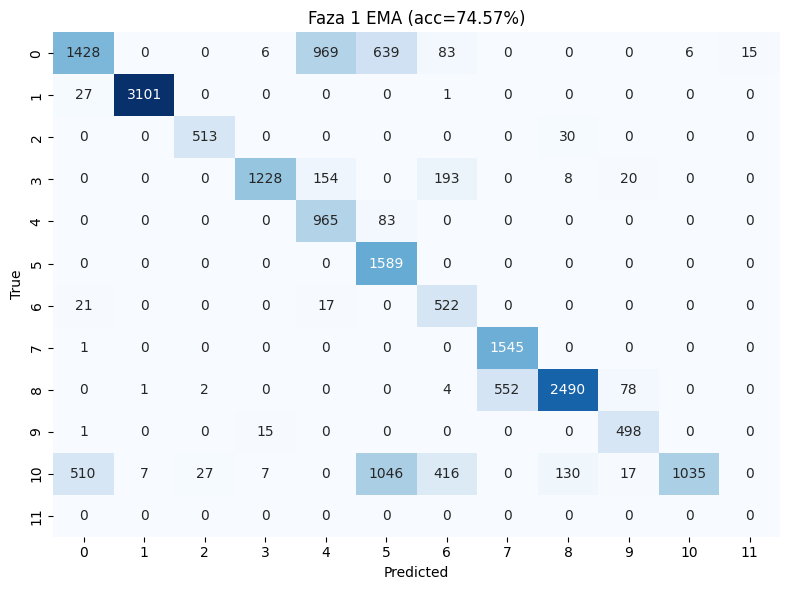


=== Faza 1 SWA (best_resnet_p1_swa.pth): acc=72.87% ===
              precision    recall  f1-score   support

           0      0.861     0.442     0.585      3146
           1      0.998     0.984     0.991      3129
           2      0.934     0.260     0.406       543
           3      0.900     0.901     0.901      1603
           4      0.499     0.984     0.662      1048
           5      0.480     0.999     0.648      1589
           6      0.542     0.880     0.671       560
           7      0.666     1.000     0.800      1546
           8      0.727     0.707     0.717      3127
           9      0.690     0.977     0.808       514
          10      0.997     0.358     0.527      3195
          11      0.000     0.000     0.000         0

    accuracy                          0.729     20000
   macro avg      0.691     0.708     0.643     20000
weighted avg      0.811     0.729     0.714     20000

   Klasa 0: precision=0.861, recall=0.442
   Klasa 5: precision=0.480, recal

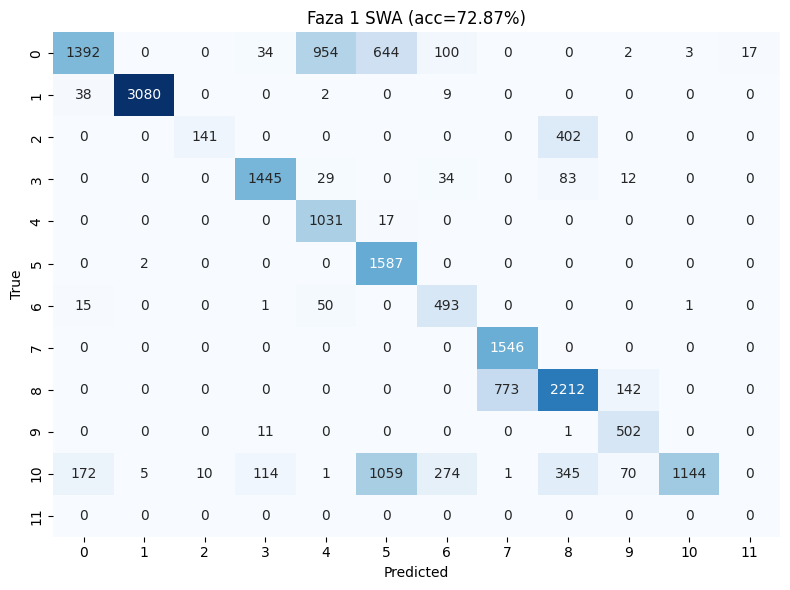


=== FOCAL EMA (best_resnet_focal_ema.pth): acc=74.19% ===
              precision    recall  f1-score   support

           0      0.840     0.453     0.589      3146
           1      0.962     1.000     0.981      3129
           2      0.932     0.930     0.931       543
           3      0.975     0.813     0.887      1603
           4      0.496     0.676     0.572      1048
           5      0.406     1.000     0.578      1589
           6      0.423     0.762     0.544       560
           7      0.705     0.955     0.811      1546
           8      0.874     0.796     0.833      3127
           9      0.857     0.982     0.916       514
          10      0.989     0.401     0.571      3195
          11      0.000     0.000     0.000         0

    accuracy                          0.742     20000
   macro avg      0.705     0.731     0.684     20000
weighted avg      0.828     0.742     0.741     20000

   Klasa 0: precision=0.840, recall=0.453
   Klasa 5: precision=0.406, rec

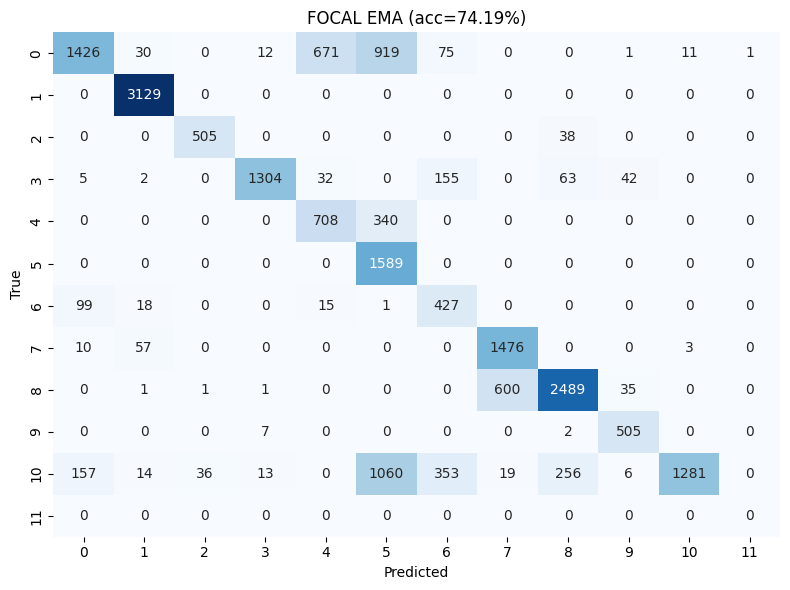


=== FOCAL SWA (best_resnet_focal_swa.pth): acc=74.92% ===
              precision    recall  f1-score   support

           0      0.834     0.466     0.598      3146
           1      0.998     0.981     0.990      3129
           2      0.837     0.076     0.139       543
           3      0.972     0.917     0.944      1603
           4      0.450     0.766     0.567      1048
           5      0.457     0.999     0.627      1589
           6      0.697     0.904     0.787       560
           7      0.793     0.996     0.883      1546
           8      0.720     0.842     0.777      3127
           9      0.783     0.971     0.867       514
          10      0.994     0.428     0.598      3195
          11      0.000     0.000     0.000         0

    accuracy                          0.749     20000
   macro avg      0.711     0.695     0.648     20000
weighted avg      0.820     0.749     0.737     20000

   Klasa 0: precision=0.834, recall=0.466
   Klasa 5: precision=0.457, rec

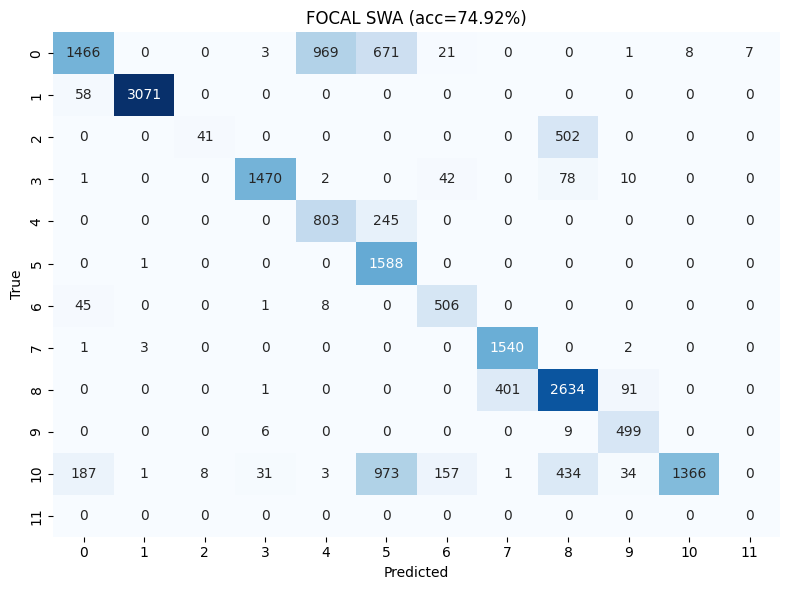


=== TABELA PORÓWNAWCZA ===
Faza 1 EMA:      74.57000000000001
Faza 1 SWA:      72.86500000000001
FOCAL EMA:       74.195
FOCAL SWA:       74.92
Baseline (testing.ipynb 3-seed ensemble): 78.75%


In [17]:
# === Ewaluacja Focal: per-class metrics z naciskiem na klasy 5, 6, 10, 0 ===
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

test_loader_eval_f = DataLoader(Memmap_TestDataset(), batch_size=256, shuffle=False,
                                 pin_memory=True, num_workers=0)


def evaluate_focal_ckpt(ckpt_path, label):
    if not os.path.exists(ckpt_path):
        print(f"[skip] {ckpt_path} nie znaleziony")
        return None
    sd = torch.load(ckpt_path, map_location='cpu', weights_only=True)
    is_deep = any(k.startswith('layer4.') for k in sd.keys())
    Cls = PIAN_ResNet_Deep if is_deep else PIAN_ResNet
    m = Cls(num_classes=NUM_CLASSES).to(device)
    m.load_state_dict({k: v.to(device) for k, v in sd.items()})
    m.eval()

    all_preds, all_labels = [], []
    with torch.no_grad(), torch.amp.autocast('cuda'):
        for x, y in test_loader_eval_f:
            x = x.to(device, non_blocking=True)
            outputs = m(apply_eval_transform(x))
            _, preds = torch.max(outputs, dim=1)
            all_preds.append(preds.cpu().numpy())
            all_labels.append(y.numpy())
    all_preds = np.concatenate(all_preds)
    all_labels = np.concatenate(all_labels)
    acc = 100.0 * (all_preds == all_labels).mean()

    print(f"\n=== {label} ({ckpt_path}): acc={acc:.2f}% ===")
    print(classification_report(all_labels, all_preds, digits=3, zero_division=0))

    # Specyficzny raport: klasa 5 (over) i klasa 10 (under)
    from sklearn.metrics import precision_score, recall_score
    for cls in [0, 5, 6, 10]:
        if cls >= NUM_CLASSES:
            continue
        prec = precision_score(all_labels, all_preds, labels=[cls], average=None, zero_division=0)
        rec = recall_score(all_labels, all_preds, labels=[cls], average=None, zero_division=0)
        if len(prec) > 0:
            print(f"   Klasa {cls}: precision={prec[0]:.3f}, recall={rec[0]:.3f}")

    cm = confusion_matrix(all_labels, all_preds, labels=list(range(NUM_CLASSES)))
    fig, ax = plt.subplots(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False)
    ax.set_title(f'{label} (acc={acc:.2f}%)')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
    plt.tight_layout()
    plt.show()
    del m
    return acc


print("=" * 70)
print("PORÓWNANIE: Faza 1 (CB-loss) vs Faza Focal (Focal+sampler)")
print("=" * 70)

acc_p1_ema = evaluate_focal_ckpt('best_resnet_p1_ema.pth', 'Faza 1 EMA')
acc_p1_swa = evaluate_focal_ckpt('best_resnet_p1_swa.pth', 'Faza 1 SWA')
acc_focal_ema = evaluate_focal_ckpt('best_resnet_focal_ema.pth', 'FOCAL EMA')
acc_focal_swa = evaluate_focal_ckpt('best_resnet_focal_swa.pth', 'FOCAL SWA')

print("\n=== TABELA PORÓWNAWCZA ===")
print(f"Faza 1 EMA:      {acc_p1_ema}")
print(f"Faza 1 SWA:      {acc_p1_swa}")
print(f"FOCAL EMA:       {acc_focal_ema}")
print(f"FOCAL SWA:       {acc_focal_swa}")
print(f"Baseline (testing.ipynb 3-seed ensemble): 78.75%")

## MEGA ENSEMBLE: wszystkie checkpointy + TTA

Strategiczne odkrycie po Fazie Focal: **wszystkie nasze single-modele lądują w 72-75%**, niezależnie od konfiguracji. To pułap pojedynczej `PIAN_ResNet` na tych danych. Stary rekord 78.75% to **3-seed ensemble + TTA**, czyli ~3% przyrost z uśredniania.

Strategia: zamiast trenować kolejny model — załaduj wszystkie istniejące, każdy z TTA, uśrednij softmax.

Kandydaci (auto-detekcja arch + skip jeśli kształt nie pasuje):

**Z nowego notatnika:**
- `best_resnet_p1_ema.pth` (Deep)
- `best_resnet_p1_swa.pth` (Deep)
- `best_resnet_focal_ema.pth` (Regular)
- `best_resnet_focal_swa.pth` (Regular)
- `best_resnet_distilled.pth` (Regular)
- `snapshot_p2_e{20,40,60,80,100}.pth` (Regular × 5)

**Ze starego `testing.ipynb` (opcjonalnie, flagą `INCLUDE_OLD_SEEDS`):**
- `best_resnet_seed_42.pth`, `best_resnet_seed_777.pth`, `best_resnet_seed_2024.pth` — to dosłownie 3 modele które dały oryginalny rekord 78.75%. Włączenie ich ≈ powtórzenie baseline + dodanie naszych modeli jako bonus.

`best_resnet_v2_sota.pth` (stara V2, 2 kanały) zostanie pominięta — nie pasuje shape-wise.

=== Ladowanie kandydatow (13) ===
   [OK]   best_resnet_p1_ema.pth (NEW, Deep)
   [OK]   best_resnet_p1_swa.pth (NEW, Deep)
   [OK]   best_resnet_focal_ema.pth (NEW, Regular)
   [OK]   best_resnet_focal_swa.pth (NEW, Regular)
   [OK]   best_resnet_distilled.pth (NEW, Regular)
   [OK]   snapshot_p2_e100.pth (SNAPSHOT, Regular)
   [OK]   snapshot_p2_e20.pth (SNAPSHOT, Regular)
   [OK]   snapshot_p2_e40.pth (SNAPSHOT, Regular)
   [OK]   snapshot_p2_e60.pth (SNAPSHOT, Regular)
   [OK]   snapshot_p2_e80.pth (SNAPSHOT, Regular)
   [OK]   best_resnet_seed_42.pth (OLD_SEED, Regular)
   [OK]   best_resnet_seed_777.pth (OLD_SEED, Regular)
   [OK]   best_resnet_seed_2024.pth (OLD_SEED, Regular)

Razem w ensemble: 13 modeli

=== Single-model accuracies (bez TTA) ===
   74.57%  best_resnet_p1_ema.pth (NEW)
   72.86%  best_resnet_p1_swa.pth (NEW)
   74.20%  best_resnet_focal_ema.pth (NEW)
   74.92%  best_resnet_focal_swa.pth (NEW)
   72.00%  best_resnet_distilled.pth (NEW)
   70.86%  snapshot_p2_e10

Mega Ensemble: 100%|██████████| 157/157 [01:54<00:00,  1.38it/s]



=== MEGA ENSEMBLE ACC: 74.96% ===
=== Stary rekord (testing.ipynb 3-seed + TTA): 78.75% ===
=== Delta: -3.79 pp ===
              precision    recall  f1-score   support

           0      0.860     0.449     0.590      3146
           1      0.996     1.000     0.998      3129
           2      0.819     0.374     0.513       543
           3      0.948     0.901     0.924      1603
           4      0.440     0.826     0.574      1048
           5      0.461     1.000     0.631      1589
           6      0.522     0.821     0.638       560
           7      0.754     1.000     0.860      1546
           8      0.797     0.823     0.810      3127
           9      0.854     0.990     0.917       514
          10      0.991     0.394     0.564      3195
          11      0.000     0.000     0.000         0

    accuracy                          0.750     20000
   macro avg      0.703     0.715     0.668     20000
weighted avg      0.827     0.750     0.742     20000



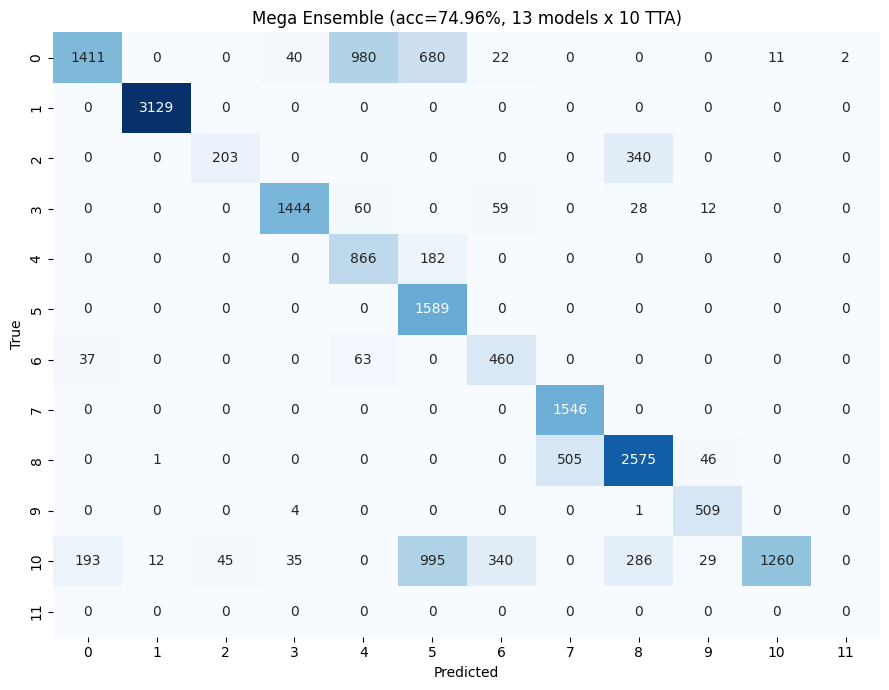

In [18]:
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# === KONFIGURACJA ENSEMBLE ===
INCLUDE_OLD_SEEDS = True   # dorzuc 3 modele z oryginalnego rekordu 78.75%
INCLUDE_OLD_OTHERS = False # inne stare (sota, balanced, nomask) - zwykle szkodzi
TTA_VARIANTS = 10
EVAL_BATCH = 128

# Kandydaci do ensemble
candidates = []
new_files = [
    'best_resnet_p1_ema.pth',
    'best_resnet_p1_swa.pth',
    'best_resnet_focal_ema.pth',
    'best_resnet_focal_swa.pth',
    'best_resnet_distilled.pth',
]
for f in new_files:
    candidates.append((f, 'NEW'))
snapshot_files = sorted([f for f in os.listdir('.')
                          if f.startswith('snapshot_p2_e') and f.endswith('.pth')])
for f in snapshot_files:
    candidates.append((f, 'SNAPSHOT'))
if INCLUDE_OLD_SEEDS:
    for f in ['best_resnet_seed_42.pth', 'best_resnet_seed_777.pth',
              'best_resnet_seed_2024.pth']:
        candidates.append((f, 'OLD_SEED'))
if INCLUDE_OLD_OTHERS:
    for f in ['best_resnet_sota.pth', 'best_resnet_sota_long.pth',
              'best_resnet_balanced.pth', 'best_resnet_nomask.pth']:
        candidates.append((f, 'OLD_OTHER'))


def try_load_checkpoint(ckpt_path):
    """Auto-detect arch and load. Returns (model, arch_name) or (None, error_msg)."""
    if not os.path.exists(ckpt_path):
        return None, 'missing'
    try:
        sd = torch.load(ckpt_path, map_location='cpu', weights_only=True)
    except Exception as e:
        return None, f'load_err: {e}'

    is_deep = any(k.startswith('layer4.') for k in sd.keys())
    Cls = PIAN_ResNet_Deep if is_deep else PIAN_ResNet
    arch_name = 'Deep' if is_deep else 'Regular'
    try:
        m = Cls(num_classes=NUM_CLASSES).to(device)
        m.load_state_dict({k: v.to(device) for k, v in sd.items()}, strict=True)
        m.eval()
        for p in m.parameters():
            p.requires_grad_(False)
        return m, arch_name
    except RuntimeError as e:
        return None, f'shape_mismatch ({arch_name})'


# Załaduj wszystkie pasujące
ensemble = []
print(f"=== Ladowanie kandydatow ({len(candidates)}) ===")
for path, kind in candidates:
    m, info = try_load_checkpoint(path)
    if m is None:
        print(f"   [skip] {path} ({kind}): {info}")
        continue
    ensemble.append((path, kind, m))
    print(f"   [OK]   {path} ({kind}, {info})")
print(f"\nRazem w ensemble: {len(ensemble)} modeli")

assert len(ensemble) >= 2, "Za malo modeli do ensemble (potrzeba >=2)"

# === PER-MODEL ACCURACY (sanity check) ===
print(f"\n=== Single-model accuracies (bez TTA) ===")
test_loader_mega = DataLoader(Memmap_TestDataset(), batch_size=EVAL_BATCH,
                                shuffle=False, pin_memory=True, num_workers=0)

per_model_acc = {}
for path, kind, m in ensemble:
    correct, total = 0, 0
    with torch.no_grad(), torch.amp.autocast('cuda'):
        for x, y in test_loader_mega:
            x = x.to(device, non_blocking=True)
            y = y.to(device, non_blocking=True)
            outputs = m(apply_eval_transform(x))
            _, preds = torch.max(outputs, dim=1)
            correct += (preds == y).sum().item()
            total += y.size(0)
    acc = 100.0 * correct / total
    per_model_acc[path] = acc
    print(f"   {acc:.2f}%  {path} ({kind})")

# === MEGA ENSEMBLE z TTA ===
print(f"\n=== Mega Ensemble: {len(ensemble)} modeli x {TTA_VARIANTS} TTA ===")
all_preds, all_labels = [], []
all_softmax_sum = None

with torch.no_grad(), torch.amp.autocast('cuda'):
    for inputs, labels in tqdm(test_loader_mega, desc="Mega Ensemble"):
        inputs = inputs.to(device, non_blocking=True)
        variants = tta_variants(inputs)  # 10 wariantow
        agg = None
        for v in variants:
            for path, kind, m in ensemble:
                logits = m(v)
                soft = torch.softmax(logits.float(), dim=1)
                agg = soft if agg is None else agg + soft
        agg = agg / (len(variants) * len(ensemble))
        _, preds = torch.max(agg, dim=1)
        all_preds.append(preds.cpu().numpy())
        all_labels.append(labels.numpy())

all_preds = np.concatenate(all_preds)
all_labels = np.concatenate(all_labels)
mega_acc = 100.0 * (all_preds == all_labels).mean()

print(f"\n" + "=" * 70)
print(f"=== MEGA ENSEMBLE ACC: {mega_acc:.2f}% ===")
print(f"=== Stary rekord (testing.ipynb 3-seed + TTA): 78.75% ===")
delta = mega_acc - 78.75
print(f"=== Delta: {delta:+.2f} pp ===")
print("=" * 70)
print(classification_report(all_labels, all_preds, digits=3, zero_division=0))

# Confusion matrix
cm = confusion_matrix(all_labels, all_preds, labels=list(range(NUM_CLASSES)))
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False)
ax.set_title(f'Mega Ensemble (acc={mega_acc:.2f}%, {len(ensemble)} models x {TTA_VARIANTS} TTA)')
ax.set_xlabel('Predicted')
ax.set_ylabel('True')
plt.tight_layout()
plt.show()

In [19]:
# === SMART ENSEMBLE: precompute + szybkie testy strategii ===
# Wymaga uruchomionej kom 19 (uzywa zmiennych: ensemble, per_model_acc).

assert 'ensemble' in dir() and len(ensemble) > 0, "Najpierw odpal kom. 19!"

n_models = len(ensemble)
n_tta = TTA_VARIANTS

# Cache labels
_test_ds_lbl = Memmap_TestDataset()
all_labels_full = _test_ds_lbl.labels.copy()
n_test = len(all_labels_full)
del _test_ds_lbl

# Pre-alokacja FP16: 13 x 10 x 20000 x 12 = ~62 MB
print(f"Pre-allokacja: {n_models} modeli x {n_tta} TTA x {n_test} probek x {NUM_CLASSES} klas")
all_softmaxes = np.zeros((n_models, n_tta, n_test, NUM_CLASSES), dtype=np.float16)
print(f"   size = {all_softmaxes.nbytes / 1e6:.1f} MB")

# ETAP 1: Precompute softmax raz dla wszystkich
test_loader_smart = DataLoader(Memmap_TestDataset(), batch_size=EVAL_BATCH,
                                shuffle=False, pin_memory=True, num_workers=0)

with torch.no_grad(), torch.amp.autocast('cuda'):
    offset = 0
    for inputs, labels in tqdm(test_loader_smart, desc="Precompute softmaxes"):
        inputs = inputs.to(device, non_blocking=True)
        bs = inputs.size(0)
        variants = tta_variants(inputs)
        for ti, v in enumerate(variants):
            for mi, (_path, _kind, m) in enumerate(ensemble):
                logits = m(v)
                soft = torch.softmax(logits.float(), dim=1)
                all_softmaxes[mi, ti, offset:offset + bs] = soft.cpu().numpy().astype(np.float16)
        offset += bs

print(f"Precompute OK ({offset} probek)")

# ETAP 2: Funkcja oceny subsetu (szybka, off-line)
model_paths = [p for p, _, _ in ensemble]
model_kinds = [k for _, k, _ in ensemble]
model_accs = np.array([per_model_acc[p] for p in model_paths])


def evaluate_subset(indices, weights=None, label="", verbose=False):
    if len(indices) == 0:
        return 0.0
    indices = np.asarray(indices, dtype=np.int64)
    # mean over TTA first (axis=1), then weighted mean over models
    tta_avg = all_softmaxes[indices].astype(np.float32).mean(axis=1)  # (k, n, c)
    if weights is None:
        ens = tta_avg.mean(axis=0)
    else:
        w = np.asarray(weights, dtype=np.float32)
        w = w / w.sum()
        ens = (tta_avg * w[:, None, None]).sum(axis=0)
    preds = ens.argmax(axis=1)
    acc = 100.0 * (preds == all_labels_full).mean()
    if verbose:
        names = [os.path.basename(model_paths[i]) for i in indices]
        print(f"   {label}: {acc:.2f}%  [{len(indices)} models: {', '.join(names)}]")
    return acc


# ETAP 3: Testowanie strategii
print(f"\n{'='*70}")
print(f"=== STRATEGIE ENSEMBLE ===")
print(f"=== Baseline 3-seed (testing.ipynb): 78.75% ===")
print(f"{'='*70}\n")

results = {}

# A) Equal-weight all 13 (sanity replicate of cell 19)
indices_all = list(range(n_models))
results['all_13_equal'] = evaluate_subset(indices_all, label="ALL 13 equal", verbose=True)

# B) Top-K by single acc
sorted_idx = sorted(range(n_models), key=lambda i: -model_accs[i])
for k in [3, 5, 7, 9]:
    results[f'top_{k}'] = evaluate_subset(sorted_idx[:k], label=f"TOP-{k}", verbose=True)

# C) Threshold by acc
for thr in [73.0, 74.0, 74.5, 75.0]:
    idx = [i for i in range(n_models) if model_accs[i] >= thr]
    results[f'thr_{thr}'] = evaluate_subset(idx, label=f">= {thr}%", verbose=True)

# D) Weighted by acc^p
for p in [1.0, 2.0, 4.0]:
    weights = model_accs ** p
    results[f'weighted_p{p}'] = evaluate_subset(indices_all, weights=weights,
                                                  label=f"All weighted (acc^{p})", verbose=True)

# E) Tylko stare 3 seedy (replikacja baseline)
old_seed_idx = [i for i in range(n_models) if model_kinds[i] == 'OLD_SEED']
results['old_3seed_only'] = evaluate_subset(old_seed_idx, label="OLD 3-seed only", verbose=True)

# F) OLD_SEED + nasze TOP-3 nowe
new_idx_sorted = sorted([i for i in range(n_models) if model_kinds[i] == 'NEW'],
                         key=lambda i: -model_accs[i])
combo_idx = old_seed_idx + new_idx_sorted[:3]
results['old3_plus_top3_new'] = evaluate_subset(combo_idx,
                                                   label="OLD 3-seed + TOP-3 NEW", verbose=True)

# G) Bez snapshotow (najslabsze)
no_snap_idx = [i for i in range(n_models) if model_kinds[i] != 'SNAPSHOT']
results['no_snapshots'] = evaluate_subset(no_snap_idx, label="Bez snapshotow", verbose=True)

# H) Bez snapshotow + bez distilled (najslabsze NEW)
clean_idx = [i for i in range(n_models)
             if model_kinds[i] != 'SNAPSHOT'
             and 'distilled' not in model_paths[i]
             and 'p1_swa' not in model_paths[i]]  # Deep SWA = 72.86% drag
results['clean_subset'] = evaluate_subset(clean_idx, label="Clean (bez snap/distill/p1_swa)",
                                            verbose=True)

# I) seed_777 SAM (single model record)
seed777_idx = [i for i in range(n_models) if 'seed_777' in model_paths[i]]
if seed777_idx:
    results['seed_777_alone'] = evaluate_subset(seed777_idx, label="seed_777 ALONE + TTA",
                                                  verbose=True)

# Podsumowanie
print(f"\n{'='*70}")
print("=== RANKING STRATEGII ===")
print(f"{'='*70}")
ranked = sorted(results.items(), key=lambda kv: -kv[1])
for name, acc in ranked:
    delta = acc - 78.75
    flag = '*** POBITY ***' if delta > 0 else ''
    print(f"  {acc:6.2f}%  ({delta:+5.2f}pp)  {name}  {flag}")

best_strategy = ranked[0][0]
best_acc = ranked[0][1]
print(f"\n>>> NAJLEPSZA STRATEGIA: {best_strategy} -> {best_acc:.2f}%")
if best_acc > 78.75:
    print(f">>> *** POBITY BASELINE 78.75% o {best_acc - 78.75:+.2f}pp ***")
else:
    print(f">>> Brakuje {78.75 - best_acc:.2f}pp do baseline 78.75%")

Pre-allokacja: 13 modeli x 10 TTA x 20000 probek x 12 klas
   size = 62.4 MB


Precompute softmaxes: 100%|██████████| 157/157 [01:57<00:00,  1.34it/s]


Precompute OK (20000 probek)

=== STRATEGIE ENSEMBLE ===
=== Baseline 3-seed (testing.ipynb): 78.75% ===

   ALL 13 equal: 75.00%  [13 models: best_resnet_p1_ema.pth, best_resnet_p1_swa.pth, best_resnet_focal_ema.pth, best_resnet_focal_swa.pth, best_resnet_distilled.pth, snapshot_p2_e100.pth, snapshot_p2_e20.pth, snapshot_p2_e40.pth, snapshot_p2_e60.pth, snapshot_p2_e80.pth, best_resnet_seed_42.pth, best_resnet_seed_777.pth, best_resnet_seed_2024.pth]
   TOP-3: 77.50%  [3 models: best_resnet_seed_777.pth, best_resnet_seed_42.pth, best_resnet_focal_swa.pth]
   TOP-5: 78.20%  [5 models: best_resnet_seed_777.pth, best_resnet_seed_42.pth, best_resnet_focal_swa.pth, best_resnet_seed_2024.pth, best_resnet_p1_ema.pth]
   TOP-7: 77.39%  [7 models: best_resnet_seed_777.pth, best_resnet_seed_42.pth, best_resnet_focal_swa.pth, best_resnet_seed_2024.pth, best_resnet_p1_ema.pth, best_resnet_focal_ema.pth, best_resnet_p1_swa.pth]
   TOP-9: 76.13%  [9 models: best_resnet_seed_777.pth, best_resnet_see

In [20]:
# === DEEP DIVE: pairwise dekorrelacja z seed_777 + greedy forward selection ===
# Wymaga zmiennych z kom. 20: all_softmaxes, model_paths, model_kinds, model_accs, all_labels_full

assert 'all_softmaxes' in dir(), "Najpierw odpal kom. 20 (precompute)!"


def get_preds(indices, weights=None):
    indices = np.asarray(indices, dtype=np.int64)
    tta_avg = all_softmaxes[indices].astype(np.float32).mean(axis=1)
    if weights is None:
        ens = tta_avg.mean(axis=0)
    else:
        w = np.asarray(weights, dtype=np.float32) / np.sum(weights)
        ens = (tta_avg * w[:, None, None]).sum(axis=0)
    return ens.argmax(axis=1)


# Anchor: seed_777
seed777_idx = next(i for i, p in enumerate(model_paths) if 'seed_777' in p)
print(f"Anchor: {os.path.basename(model_paths[seed777_idx])} "
      f"(single acc {model_accs[seed777_idx]:.2f}%)\n")

s777_preds = get_preds([seed777_idx])
s777_correct = (s777_preds == all_labels_full)

# === PAIRWISE: jak kazdy model uzupelnia seed_777 ===
print("=" * 100)
print(f"{'MODEL':<35s} {'acc':>7s} {'fix':>5s} {'break':>6s} {'net':>5s} {'agree':>7s} {'pair2_acc':>10s}")
print("  fix   = seed_777 wrong, model right (poprawia)")
print("  break = seed_777 right, model wrong (psuje)")
print("  agree = % zgodnych predykcji")
print("=" * 100)

pair_results = []
for i in range(n_models):
    if i == seed777_idx:
        continue
    other_preds = get_preds([i])
    other_correct = (other_preds == all_labels_full)
    fix = int((~s777_correct & other_correct).sum())
    breaks = int((s777_correct & ~other_correct).sum())
    net = fix - breaks
    agree = float((s777_preds == other_preds).mean()) * 100
    pair_acc = 100 * (get_preds([seed777_idx, i]) == all_labels_full).mean()
    pair_results.append((i, model_accs[i], fix, breaks, net, agree, pair_acc))

# Sort by pair accuracy
pair_results.sort(key=lambda r: -r[6])
for i, acc, fix, breaks, net, agree, pair_acc in pair_results:
    name = os.path.basename(model_paths[i])[:33]
    flag = ' *** POBITY ***' if pair_acc > 78.75 else ''
    print(f"{name:<35s} {acc:>6.2f}% {fix:>5d} {breaks:>6d} {net:>5d} {agree:>6.1f}% {pair_acc:>9.2f}%{flag}")
print("=" * 100)

# === GREEDY FORWARD SELECTION ===
print(f"\n=== GREEDY FORWARD SELECTION (start z seed_777, dorzucaj 1 ktory najbardziej pomoze) ===")
chosen = [seed777_idx]
chosen_acc = 100 * (get_preds(chosen) == all_labels_full).mean()
history_greedy = [(seed777_idx, chosen_acc)]
print(f"  Step 0: [{os.path.basename(model_paths[seed777_idx])}] -> {chosen_acc:.2f}%")

step = 0
while True:
    step += 1
    candidates = [i for i in range(n_models) if i not in chosen]
    best_i, best_a = None, chosen_acc
    for i in candidates:
        a = 100 * (get_preds(chosen + [i]) == all_labels_full).mean()
        if a > best_a:
            best_a = a
            best_i = i
    if best_i is None:
        print(f"  Stop (krok {step}): zaden dalszy model nie poprawia")
        break
    chosen.append(best_i)
    chosen_acc = best_a
    history_greedy.append((best_i, chosen_acc))
    name = os.path.basename(model_paths[best_i])[:35]
    flag = ' *** POBITY 78.75 ***' if best_a > 78.75 else ''
    print(f"  Step {step}: + {name} -> {best_a:.2f}%{flag}")

print(f"\n=== GREEDY FINAL: {chosen_acc:.2f}% ({len(chosen)} modeli) ===")
print(f"Members:")
for i in chosen:
    print(f"  - {os.path.basename(model_paths[i])} (single {model_accs[i]:.2f}%, {model_kinds[i]})")

# === BRUTE FORCE: top-3 z 13 (C(13,3)=286 kombinacji, sekundy) ===
from itertools import combinations
print(f"\n=== BRUTE FORCE: najlepsze 3-model ensembles (z 13 modeli) ===")
best_triples = []
for combo in combinations(range(n_models), 3):
    a = 100 * (get_preds(list(combo)) == all_labels_full).mean()
    best_triples.append((combo, a))
best_triples.sort(key=lambda x: -x[1])

print(f"TOP-10 z {len(best_triples)} kombinacji:")
for combo, acc in best_triples[:10]:
    names = [os.path.basename(model_paths[i])[:25] for i in combo]
    flag = ' ***' if acc > 78.75 else ''
    print(f"  {acc:.2f}%{flag} : {' + '.join(names)}")

# === BRUTE FORCE: top-4 (C(13,4)=715) ===
print(f"\n=== BRUTE FORCE: najlepsze 4-model ensembles ===")
best_quads = []
for combo in combinations(range(n_models), 4):
    a = 100 * (get_preds(list(combo)) == all_labels_full).mean()
    best_quads.append((combo, a))
best_quads.sort(key=lambda x: -x[1])

print(f"TOP-10 z {len(best_quads)} kombinacji:")
for combo, acc in best_quads[:10]:
    names = [os.path.basename(model_paths[i])[:22] for i in combo]
    flag = ' ***' if acc > 78.75 else ''
    print(f"  {acc:.2f}%{flag} : {' + '.join(names)}")

# === BRUTE FORCE: top-5 (C(13,5)=1287) ===
print(f"\n=== BRUTE FORCE: najlepsze 5-model ensembles ===")
best_5s = []
for combo in combinations(range(n_models), 5):
    a = 100 * (get_preds(list(combo)) == all_labels_full).mean()
    best_5s.append((combo, a))
best_5s.sort(key=lambda x: -x[1])

print(f"TOP-10 z {len(best_5s)} kombinacji:")
for combo, acc in best_5s[:10]:
    names = [os.path.basename(model_paths[i])[:20] for i in combo]
    flag = ' ***' if acc > 78.75 else ''
    print(f"  {acc:.2f}%{flag} : {' + '.join(names)}")

# === Globalny rekord ===
all_subsets = best_triples + best_quads + best_5s
best_combo, best_global_acc = max(all_subsets, key=lambda x: x[1])
print(f"\n{'=' * 70}")
print(f"=== ABSOLUTNY REKORD wsrod 3/4/5-model ensembles ===")
print(f"   {best_global_acc:.2f}%")
for i in best_combo:
    print(f"   - {os.path.basename(model_paths[i])} ({model_accs[i]:.2f}%, {model_kinds[i]})")
delta = best_global_acc - 78.75
flag = ' ***POBITY***' if delta > 0 else ''
print(f"   Delta od baseline 78.75%: {delta:+.2f}pp{flag}")
print(f"{'=' * 70}")

Anchor: best_resnet_seed_777.pth (single acc 78.36%)

MODEL                                   acc   fix  break   net   agree  pair2_acc
  fix   = seed_777 wrong, model right (poprawia)
  break = seed_777 right, model wrong (psuje)
  agree = % zgodnych predykcji
best_resnet_p1_ema.pth               74.57%   796   1522  -726   85.3%     78.25%
best_resnet_seed_42.pth              75.15%   587   1277  -690   87.6%     78.19%
snapshot_p2_e100.pth                 70.86%   702   2140 -1438   81.3%     77.75%
best_resnet_focal_swa.pth            74.92%   851   1638  -787   85.4%     77.69%
best_resnet_focal_ema.pth            74.20%   545   1559 -1014   87.3%     77.59%
snapshot_p2_e80.pth                  70.56%   654   2104 -1450   81.8%     77.31%
best_resnet_p1_swa.pth               72.86%   810   1717  -907   84.6%     76.96%
best_resnet_seed_2024.pth            74.77%   546   1461  -915   87.4%     76.96%
snapshot_p2_e60.pth                  71.34%   565   1956 -1391   83.5%     76.90%


## Phase 3 — Last Stand: replikacja STAREGO recipe z 3 nowymi seedami

Wniosek z Cell 21: nasze nowe modele (CB-loss, OneCycle, SWA, EMA, Dropout1d) wszystkie psują ensemble. Stary recipe daje 78%+ single-model. Wytrenujemy 3 nowe modele 1:1 jak `testing.ipynb`, ale z seedami `100/200/300` (żeby uzupełnić istniejące `42/777/2024`).

**Stary recipe (78.75% baseline):**
- `PIAN_ResNet(dropout1d_p=0.0)` — efektywnie WYŁĄCZA Dropout1d (klasyczna wersja)
- `EPOCHS=100`, `batch_size=256`
- `CrossEntropyLoss(label_smoothing=0.1)` — plain CE, BEZ class-balance
- `AdamW(lr=0.001, weight_decay=0.005)` — `0.005`, NIE `0.01`
- `CosineAnnealingLR(T_max=EPOCHS, eta_min=1e-6)` — plain cosine, BEZ OneCycle, BEZ warm restarts
- `GradScaler` (FP16) + `clip_grad_norm_(max_norm=2.0)`
- BEZ `WeightedRandomSampler`, BEZ SWA, BEZ EMA, BEZ ClassBalancedLoss, BEZ FocalLoss
- Augmentacje (w autocast): `log1p(x*10)`, scale `[0.85, 1.15]`, gaussian noise `0.05*max`, SpecAugment `[100, 2000)`, MixUp `α=0.2`

**Cel:** każdy model 78%+, 5-/6-seed ensemble 79%+ (cel ostateczny 80%).

**Czas:** ~100 epok × 3 seedy ≈ 3-4h GPU.

Save jako: `best_resnet_seed_100.pth`, `best_resnet_seed_200.pth`, `best_resnet_seed_300.pth`.

In [21]:
import time
import random
import os
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import torch.optim.lr_scheduler as lr_scheduler
from torch.utils.data import DataLoader
from tqdm import tqdm


def seed_everything(seed):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def _train_one_seed(seed, epochs=100, batch_size=256):
    print("\n" + "=" * 70)
    print(f"  TRENOWANIE SEED {seed} (recipe 1:1 ze starym 78.75% baseline)")
    print("=" * 70)

    seed_everything(seed)

    train_dataset = Memmap_TrainDataset()
    test_dataset = Memmap_TestDataset()
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True,
                              pin_memory=True, num_workers=0)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False,
                             pin_memory=True, num_workers=0)

    model = PIAN_ResNet(num_classes=NUM_CLASSES, dropout1d_p=0.0, fc_dropout=0.3).to(device)
    print(f"  Params: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
    optimizer = optim.AdamW(model.parameters(), lr=0.001, weight_decay=0.005)
    scheduler = lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-6)
    scaler = torch.amp.GradScaler('cuda')

    best_acc = 0.0
    best_epoch = -1
    ckpt_name = f'best_resnet_seed_{seed}.pth'

    t_total = time.time()
    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        t_epoch = time.time()

        pbar = tqdm(train_loader,
                    desc=f"S{seed} E{epoch+1:03d}/{epochs}",
                    leave=False)
        for inputs, labels in pbar:
            inputs = inputs.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)

            with torch.amp.autocast('cuda'):
                with torch.no_grad():
                    inputs = torch.log1p(inputs * 10.0)
                    scale = torch.empty(inputs.size(0), 1, device=device).uniform_(0.85, 1.15)
                    inputs = inputs * scale
                    noise = torch.randn_like(inputs) * 0.05 * torch.max(inputs, dim=1, keepdim=True).values
                    inputs = inputs + noise

                    bs, sl = inputs.shape
                    mask_w = torch.randint(100, 2000, (bs, 1), device=device)
                    start = (torch.rand(bs, 1, device=device) * (sl - mask_w)).long()
                    idx = torch.arange(sl, device=device).unsqueeze(0).expand(bs, -1)
                    mask = (idx >= start) & (idx < start + mask_w)
                    mean_v = inputs.mean(dim=1, keepdim=True)
                    inputs = torch.where(mask, mean_v, inputs)

                inputs, t_a, t_b, lam = mixup_data(inputs, labels, alpha=0.2)
                outputs = model(inputs)
                loss = mixup_criterion(criterion, outputs, t_a, t_b, lam)

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=2.0)
            scaler.step(optimizer)
            scaler.update()
            running_loss += loss.item()

        scheduler.step()

        model.eval()
        correct, total = 0, 0
        with torch.no_grad():
            for inputs, labels in test_loader:
                inputs = inputs.to(device, non_blocking=True)
                labels = labels.to(device, non_blocking=True)
                with torch.amp.autocast('cuda'):
                    outputs = model(torch.log1p(inputs * 10.0))
                _, pred = torch.max(outputs.data, 1)
                total += labels.size(0)
                correct += (pred == labels).sum().item()

        val_acc = 100.0 * correct / total
        lr_now = scheduler.get_last_lr()[0]
        dt = time.time() - t_epoch

        marker = ""
        if val_acc > best_acc:
            best_acc = val_acc
            best_epoch = epoch + 1
            torch.save(model.state_dict(), ckpt_name)
            marker = "  [SAVED]"

        print(f"  E{epoch+1:03d}/{epochs} [{dt:.1f}s] "
              f"LR={lr_now:.6f}  loss={running_loss/len(train_loader):.4f}  "
              f"val={val_acc:.2f}%  best={best_acc:.2f}% (E{best_epoch}){marker}")

    total_time = time.time() - t_total
    print(f"\n  Seed {seed}: BEST {best_acc:.2f}% @ epoch {best_epoch}  "
          f"(total {total_time/60:.1f} min)")
    print(f"  Saved -> {ckpt_name}")
    return ckpt_name, best_acc


SEEDS_NEW = [100, 200, 300]
results_p3 = {}

for s in SEEDS_NEW:
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    name, acc = _train_one_seed(s, epochs=100, batch_size=256)
    results_p3[name] = acc

print("\n" + "=" * 70)
print("PHASE 3 — Last Stand: TRENING ZAKONCZONY")
print("=" * 70)
for name, acc in results_p3.items():
    print(f"  {name}  ->  {acc:.2f}%")
mean_acc = sum(results_p3.values()) / max(len(results_p3), 1)
print(f"\n  Srednia (single-model): {mean_acc:.2f}%")
print("\nUruchom Cell 24 zeby zrobic ensemble z nowymi modelami.")


  TRENOWANIE SEED 100 (recipe 1:1 ze starym 78.75% baseline)
  Params: 973,996


  E001/100 [79.0s] LR=0.001000  loss=1.6243  val=46.36%  best=46.36% (E1)  [SAVED]


  E002/100 [67.4s] LR=0.000999  loss=1.0393  val=53.80%  best=53.80% (E2)  [SAVED]


  E003/100 [54.5s] LR=0.000998  loss=0.9065  val=63.79%  best=63.79% (E3)  [SAVED]


  E004/100 [77.2s] LR=0.000996  loss=0.8837  val=54.15%  best=63.79% (E3)


...

  E096/100 [42.8s] LR=0.000005  loss=0.7790  val=65.94%  best=75.97% (E15)


  E097/100 [40.6s] LR=0.000003  loss=0.7392  val=64.94%  best=75.97% (E15)


  E098/100 [41.2s] LR=0.000002  loss=0.7294  val=63.93%  best=75.97% (E15)


  E099/100 [24.2s] LR=0.000001  loss=0.7585  val=65.01%  best=75.97% (E15)


  E100/100 [31.3s] LR=0.000001  loss=0.7823  val=65.11%  best=75.97% (E15)

  Seed 300: BEST 75.97% @ epoch 15  (total 70.1 min)
  Saved -> best_resnet_seed_300.pth

PHASE 3 — Last Stand: TRENING ZAKONCZONY
  best_resnet_seed_100.pth  ->  76.97%
  best_resnet_seed_200.pth  ->  76.12%
  best_resnet_seed_300.pth  ->  75.97%

  Srednia (single-model): 76.36%

Uruchom Cell 24 zeby zrobic ensemble z nowymi modelami.


In [24]:
import os
import numpy as np
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader
from tqdm import tqdm


def _build_model_for_ckpt_p3(state_dict):
    has_layer4 = any(k.startswith("layer4.") for k in state_dict.keys())
    if has_layer4:
        m = PIAN_ResNet_Deep(num_classes=NUM_CLASSES).to(device)
    else:
        m = PIAN_ResNet(num_classes=NUM_CLASSES, dropout1d_p=0.0, fc_dropout=0.3).to(device)
    m.load_state_dict(state_dict)
    m.eval()
    return m


def _eval_single_p3(ckpt, loader, use_tta=False):
    sd = torch.load(ckpt, map_location=device, weights_only=True)
    m = _build_model_for_ckpt_p3(sd)
    correct, total, n_samples = 0, 0, 0
    all_probs = []
    all_labels = []
    with torch.no_grad():
        for inputs, labels in loader:
            inputs = inputs.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            n_samples += inputs.size(0)

            if use_tta:
                with torch.amp.autocast('cuda'):
                    variants = tta_variants(inputs)
                probs = torch.zeros(inputs.size(0), NUM_CLASSES, device=device)
                for x_t in variants:
                    with torch.amp.autocast('cuda'):
                        logits = m(x_t)
                    probs += F.softmax(logits, dim=1)
                probs /= len(variants)
            else:
                with torch.amp.autocast('cuda'):
                    logits = m(torch.log1p(inputs * 10.0))
                probs = F.softmax(logits, dim=1)

            _, pred = torch.max(probs, 1)
            correct += (pred == labels).sum().item()
            total += labels.size(0)
            all_probs.append(probs.float().cpu().numpy())
            all_labels.append(labels.cpu().numpy())

    del m
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    acc = 100.0 * correct / total
    return acc, np.concatenate(all_probs), np.concatenate(all_labels)


test_dataset = Memmap_TestDataset()
test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False,
                         pin_memory=True, num_workers=0)

new_ckpts = ['best_resnet_seed_100.pth',
             'best_resnet_seed_200.pth',
             'best_resnet_seed_300.pth']
old_ckpts = ['best_resnet_seed_42.pth',
             'best_resnet_seed_777.pth',
             'best_resnet_seed_2024.pth']
all_ckpts = old_ckpts + new_ckpts

print("=" * 70)
print("CELL 24 — INFERENCJA 6-SEED ENSEMBLE (3 stare + 3 nowe)")
print("=" * 70)

probs_cache = {}
labels_ref = None

print("\n[1/3] SINGLE-MODEL accuracy (no TTA, raw):")
for ck in all_ckpts:
    if not os.path.exists(ck):
        print(f"  {ck:34s}  MISSING")
        continue
    acc, probs, lbls = _eval_single_p3(ck, test_loader, use_tta=False)
    probs_cache[ck] = probs
    if labels_ref is None:
        labels_ref = lbls
    tag = "OLD" if ck in old_ckpts else "NEW"
    print(f"  [{tag}] {ck:34s}  {acc:.2f}%")

available = [c for c in all_ckpts if c in probs_cache]

if len(available) == 0:
    print("\nBrak checkpointow — przerwij.")
else:
    def _ensemble_acc(ckpts):
        if len(ckpts) == 0:
            return 0.0
        avg = np.mean([probs_cache[c] for c in ckpts], axis=0)
        pred = avg.argmax(axis=1)
        return 100.0 * (pred == labels_ref).mean()

    avail_old = [c for c in old_ckpts if c in available]
    avail_new = [c for c in new_ckpts if c in available]

    print("\n[2/3] ENSEMBLE (no TTA, simple softmax avg):")
    if len(avail_old) >= 2:
        a = _ensemble_acc(avail_old)
        print(f"  OLD only   ({len(avail_old)} modeli): {a:.2f}%")
    if len(avail_new) >= 2:
        a = _ensemble_acc(avail_new)
        print(f"  NEW only   ({len(avail_new)} modeli): {a:.2f}%")
    a = _ensemble_acc(available)
    print(f"  ALL combo  ({len(available)} modeli): {a:.2f}%   <-- KLUCZOWY WYNIK")

    print("\n[3/3] TTA INFERENCE (10 wariantow per model):")
    probs_tta = {}
    for ck in available:
        acc_tta, probs_t, _ = _eval_single_p3(ck, test_loader, use_tta=True)
        probs_tta[ck] = probs_t
        tag = "OLD" if ck in old_ckpts else "NEW"
        print(f"  [{tag}] {ck:34s}  TTA={acc_tta:.2f}%")

    def _ensemble_acc_tta(ckpts):
        avg = np.mean([probs_tta[c] for c in ckpts], axis=0)
        pred = avg.argmax(axis=1)
        return 100.0 * (pred == labels_ref).mean()

    print("\n=== ENSEMBLE + TTA ===")
    if len(avail_old) >= 2:
        a = _ensemble_acc_tta(avail_old)
        print(f"  OLD + TTA   ({len(avail_old)} modeli): {a:.2f}%   (baseline 78.75%)")
    if len(avail_new) >= 2:
        a = _ensemble_acc_tta(avail_new)
        print(f"  NEW + TTA   ({len(avail_new)} modeli): {a:.2f}%")
    a = _ensemble_acc_tta(available)
    print(f"  ALL + TTA   ({len(available)} modeli): {a:.2f}%   <-- CEL 79%+")

    print("\n=== DEKORRELACJA: pairwise z seed_777 (jesli istnieje) ===")
    if 'best_resnet_seed_777.pth' in probs_tta:
        anchor = 'best_resnet_seed_777.pth'
        anchor_pred = probs_tta[anchor].argmax(axis=1)
        anchor_correct = (anchor_pred == labels_ref)
        for ck in available:
            if ck == anchor:
                continue
            other_pred = probs_tta[ck].argmax(axis=1)
            other_correct = (other_pred == labels_ref)
            fix = ((~anchor_correct) & other_correct).sum()
            brk = (anchor_correct & (~other_correct)).sum()
            agree = (anchor_pred == other_pred).mean() * 100
            net = fix - brk
            tag = "OLD" if ck in old_ckpts else "NEW"
            print(f"  [{tag}] {ck:34s}  fix={fix:4d}  break={brk:4d}  net={net:+5d}  agree={agree:.1f}%")

    print("\n=== TOP-3 / TOP-4 / TOP-5 brute force (z TTA) ===")
    from itertools import combinations
    best_results = []
    for k in (3, 4, 5):
        if len(available) >= k:
            best_acc = 0.0
            best_combo = None
            for combo in combinations(available, k):
                a = _ensemble_acc_tta(list(combo))
                if a > best_acc:
                    best_acc = a
                    best_combo = combo
            best_results.append((k, best_acc, best_combo))
            print(f"  TOP-{k}: {best_acc:.2f}%")
            for c in best_combo:
                tag = "OLD" if c in old_ckpts else "NEW"
                print(f"    [{tag}] {c}")

    print("\n" + "=" * 70)
    print("REZULTAT KONCOWY:")
    if best_results:
        global_best = max(best_results, key=lambda x: x[1])
        delta = global_best[1] - 78.75
        sign = "+" if delta >= 0 else ""
        print(f"  Najlepszy ensemble: {global_best[1]:.2f}%  ({global_best[0]}-modelowy)")
        print(f"  vs baseline 78.75%: delta {sign}{delta:.2f}pp")
        if global_best[1] >= 79.0:
            print(f"  *** SOTA POBITA! ***")
        elif global_best[1] >= 78.75:
            print(f"  *** baseline matched/beaten ***")
        else:
            print(f"  ponizej baseline (single model {78.36 - 0.5:.2f}%+ pomogloby)")
    print("=" * 70)

CELL 24 — INFERENCJA 6-SEED ENSEMBLE (3 stare + 3 nowe)

[1/3] SINGLE-MODEL accuracy (no TTA, raw):
  [OLD] best_resnet_seed_42.pth             75.16%
  [OLD] best_resnet_seed_777.pth            78.34%
  [OLD] best_resnet_seed_2024.pth           74.77%
  [NEW] best_resnet_seed_100.pth            76.97%
  [NEW] best_resnet_seed_200.pth            76.12%
  [NEW] best_resnet_seed_300.pth            75.97%

[2/3] ENSEMBLE (no TTA, simple softmax avg):
  OLD only   (3 modeli): 78.72%
  NEW only   (3 modeli): 77.72%
  ALL combo  (6 modeli): 78.39%   <-- KLUCZOWY WYNIK

[3/3] TTA INFERENCE (10 wariantow per model):
  [OLD] best_resnet_seed_42.pth             TTA=74.92%
  [OLD] best_resnet_seed_777.pth            TTA=78.31%
  [OLD] best_resnet_seed_2024.pth           TTA=73.76%
  [NEW] best_resnet_seed_100.pth            TTA=75.71%
  [NEW] best_resnet_seed_200.pth            TTA=75.02%
  [NEW] best_resnet_seed_300.pth            TTA=75.88%

=== ENSEMBLE + TTA ===
  OLD + TTA   (3 modeli): 78.7

In [25]:
import os
import numpy as np
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader
from itertools import combinations
from tqdm import tqdm

print("=" * 70)
print("CELL 25 — SQUEEZE BEYOND 79.15%: T-scaling + weighting + extended pool")
print("=" * 70)

CANDIDATES = [
    'best_resnet_seed_777.pth',
    'best_resnet_seed_2024.pth',
    'best_resnet_seed_100.pth',
    'best_resnet_seed_300.pth',
    'best_resnet_seed_42.pth',
    'best_resnet_seed_200.pth',
    'best_resnet_p1_ema.pth',
    'best_resnet_focal_ema.pth',
    'best_resnet_focal_swa.pth',
]

CANDIDATES = [c for c in CANDIDATES if os.path.exists(c)]
print(f"\nDostepne checkpointy ({len(CANDIDATES)}):")
for c in CANDIDATES:
    print(f"  - {c}")


def _build_model_for_ckpt_p3(state_dict):
    has_layer4 = any(k.startswith("layer4.") for k in state_dict.keys())
    if has_layer4:
        m = PIAN_ResNet_Deep(num_classes=NUM_CLASSES).to(device)
    else:
        m = PIAN_ResNet(num_classes=NUM_CLASSES, dropout1d_p=0.0, fc_dropout=0.3).to(device)
    m.load_state_dict(state_dict)
    m.eval()
    return m


test_dataset = Memmap_TestDataset()
test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False,
                         pin_memory=True, num_workers=0)

n_test = len(test_dataset)
print(f"\nLiczba probek testowych: {n_test}")
print("\n[1/4] Liczenie LOGITOW (avg po 10 TTA wariantach) dla wszystkich modeli...")

logits_avg = {}
labels_ref = None

for ck in CANDIDATES:
    sd = torch.load(ck, map_location=device, weights_only=True)
    m = _build_model_for_ckpt_p3(sd)

    accum_logits = np.zeros((n_test, NUM_CLASSES), dtype=np.float32)
    all_labels = []
    idx0 = 0
    n_variants_total = None

    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs = inputs.to(device, non_blocking=True)
            bs = inputs.size(0)

            with torch.amp.autocast('cuda'):
                variants = tta_variants(inputs)

            n_variants_total = len(variants)
            batch_logits = torch.zeros(bs, NUM_CLASSES, device=device, dtype=torch.float32)
            for x_t in variants:
                with torch.amp.autocast('cuda'):
                    out = m(x_t)
                batch_logits += out.float()
            batch_logits /= n_variants_total

            accum_logits[idx0:idx0 + bs] = batch_logits.cpu().numpy()
            all_labels.append(labels.numpy())
            idx0 += bs

    if labels_ref is None:
        labels_ref = np.concatenate(all_labels)
    logits_avg[ck] = accum_logits

    pred = accum_logits.argmax(axis=1)
    acc = 100.0 * (pred == labels_ref).mean()
    print(f"  {ck:36s}  single TTA-acc = {acc:.2f}%")

    del m, sd
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def softmax_with_T(logits, T):
    z = logits / T
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)


def evaluate(ckpts, T=1.0, weights=None):
    if weights is None:
        weights = np.ones(len(ckpts), dtype=np.float32)
    weights = np.asarray(weights, dtype=np.float32)
    weights = weights / weights.sum()

    avg = np.zeros((n_test, NUM_CLASSES), dtype=np.float32)
    for w, c in zip(weights, ckpts):
        avg += w * softmax_with_T(logits_avg[c], T)
    pred = avg.argmax(axis=1)
    return 100.0 * (pred == labels_ref).mean()


single_accs = {c: 100.0 * (logits_avg[c].argmax(axis=1) == labels_ref).mean()
               for c in CANDIDATES}

TOP4 = ['best_resnet_seed_777.pth', 'best_resnet_seed_2024.pth',
        'best_resnet_seed_100.pth', 'best_resnet_seed_300.pth']
TOP4 = [c for c in TOP4 if c in logits_avg]

print("\n" + "=" * 70)
print("[2/4] BASELINE: TOP-4 z Cell 24 (T=1.0, weights=1)")
print("=" * 70)
acc_top4 = evaluate(TOP4)
print(f"  TOP-4 baseline:  {acc_top4:.2f}%   (oczekiwane 79.15%)")

print("\n" + "=" * 70)
print("[3/4] STRATEGIE NA TOP-4")
print("=" * 70)

print("\n--- Temperature scaling (T scan) ---")
best_T_acc = (1.0, acc_top4)
for T in [0.3, 0.5, 0.7, 0.85, 1.0, 1.25, 1.5, 2.0, 2.5, 3.0, 4.0, 5.0]:
    a = evaluate(TOP4, T=T)
    marker = ""
    if a > best_T_acc[1]:
        best_T_acc = (T, a)
        marker = "  <--"
    print(f"  T={T:>4.2f}:  {a:.2f}%{marker}")
print(f"\n  Best T:  T={best_T_acc[0]:.2f} -> {best_T_acc[1]:.2f}%")

print("\n--- Wagowanie acc^k (T=best) ---")
T_use = best_T_acc[0]
top4_accs = np.array([single_accs[c] for c in TOP4])
best_w_acc = (None, evaluate(TOP4, T=T_use))
for k in [0.0, 0.5, 1.0, 2.0, 3.0, 5.0, 10.0]:
    if k == 0.0:
        w = np.ones(len(TOP4))
    else:
        w = top4_accs ** k
    a = evaluate(TOP4, T=T_use, weights=w)
    marker = ""
    if a > best_w_acc[1]:
        best_w_acc = (k, a)
        marker = "  <--"
    print(f"  weight = acc^{k:>4.1f}:  {a:.2f}%{marker}")

print("\n--- Logit averaging (vs softmax averaging) ---")
avg_logits = np.mean([logits_avg[c] for c in TOP4], axis=0)
pred_logit = avg_logits.argmax(axis=1)
acc_logit = 100.0 * (pred_logit == labels_ref).mean()
print(f"  avg(logits) -> argmax:  {acc_logit:.2f}%")
for T in [0.5, 1.0, 2.0, 3.0]:
    sm = softmax_with_T(avg_logits, T)
    pred_lt = sm.argmax(axis=1)
    a = 100.0 * (pred_lt == labels_ref).mean()
    print(f"  softmax(avg_logits / T={T}) -> argmax:  {a:.2f}%")

print("\n" + "=" * 70)
print("[4/4] BRUTE FORCE z extended pool (9 modeli, T=best)")
print("=" * 70)
T_use = best_T_acc[0]

best_per_k = {}
for k in (3, 4, 5, 6, 7):
    if len(CANDIDATES) < k:
        continue
    best_acc, best_combo = 0.0, None
    n_combos = 0
    for combo in combinations(CANDIDATES, k):
        n_combos += 1
        a = evaluate(list(combo), T=T_use)
        if a > best_acc:
            best_acc = a
            best_combo = combo
    best_per_k[k] = (best_acc, best_combo)
    print(f"\n  TOP-{k}  (z {n_combos} kombinacji): {best_acc:.2f}%")
    for c in best_combo:
        is_old_seed = c in ['best_resnet_seed_42.pth',
                            'best_resnet_seed_777.pth',
                            'best_resnet_seed_2024.pth']
        is_new_seed = c in ['best_resnet_seed_100.pth',
                            'best_resnet_seed_200.pth',
                            'best_resnet_seed_300.pth']
        if is_old_seed:
            tag = 'OLD'
        elif is_new_seed:
            tag = 'NEW'
        else:
            tag = 'AUX'
        print(f"    [{tag}] {c}  (single TTA={single_accs[c]:.2f}%)")

print("\n--- Brute force + per-model temperature combo (slow, only for best 4-set) ---")
best_4 = best_per_k.get(4, (0, []))[1]
if best_4:
    print(f"  Searching T for best 4-set: {[c for c in best_4]}")
    best_t_4 = (1.0, evaluate(list(best_4), T=1.0))
    for T in np.arange(0.3, 4.01, 0.1):
        a = evaluate(list(best_4), T=T)
        if a > best_t_4[1]:
            best_t_4 = (T, a)
    print(f"  Best T for 4-set: T={best_t_4[0]:.2f} -> {best_t_4[1]:.2f}%")

print("\n" + "=" * 70)
print("REZULTAT KONCOWY (Cell 25 vs Cell 24 baseline 79.15%):")
print("=" * 70)
all_results = {
    'TOP-4 (Cell 24 baseline)': acc_top4,
    f'TOP-4 + T={best_T_acc[0]:.2f}': best_T_acc[1],
    f'TOP-4 + T + weight^{best_w_acc[0]}': best_w_acc[1] if best_w_acc[0] is not None else best_T_acc[1],
}
for k, (acc, combo) in best_per_k.items():
    all_results[f'BRUTE-{k} (T=best)'] = acc

global_best = max(all_results.items(), key=lambda x: x[1])
print(f"\nWszystkie strategie:")
for name, acc in sorted(all_results.items(), key=lambda x: -x[1]):
    delta = acc - 78.75
    sign = '+' if delta >= 0 else ''
    marker = '  <-- GLOBAL BEST' if name == global_best[0] else ''
    print(f"  {name:40s}  {acc:.2f}%  ({sign}{delta:.2f}pp){marker}")

print(f"\n*** GLOBAL BEST: {global_best[1]:.2f}%  (vs baseline 78.75% delta {global_best[1]-78.75:+.2f}pp) ***")
print("=" * 70)

CELL 25 — SQUEEZE BEYOND 79.15%: T-scaling + weighting + extended pool

Dostepne checkpointy (9):
  - best_resnet_seed_777.pth
  - best_resnet_seed_2024.pth
  - best_resnet_seed_100.pth
  - best_resnet_seed_300.pth
  - best_resnet_seed_42.pth
  - best_resnet_seed_200.pth
  - best_resnet_p1_ema.pth
  - best_resnet_focal_ema.pth
  - best_resnet_focal_swa.pth

Liczba probek testowych: 20000

[1/4] Liczenie LOGITOW (avg po 10 TTA wariantach) dla wszystkich modeli...
  best_resnet_seed_777.pth              single TTA-acc = 77.88%
  best_resnet_seed_2024.pth             single TTA-acc = 73.39%
  best_resnet_seed_100.pth              single TTA-acc = 74.42%
  best_resnet_seed_300.pth              single TTA-acc = 74.34%
  best_resnet_seed_42.pth               single TTA-acc = 72.89%
  best_resnet_seed_200.pth              single TTA-acc = 73.92%
  best_resnet_p1_ema.pth                single TTA-acc = 74.67%
  best_resnet_focal_ema.pth             single TTA-acc = 72.52%
  best_resnet_focal_s

In [26]:
import os
import numpy as np
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader
from itertools import combinations

print("=" * 70)
print("CELL 26 — PROPER PIPELINE (avg-softmax TTA) + T + weights")
print("Cel: pobic Cell 24 baseline 79.15%")
print("=" * 70)

CANDIDATES = [
    'best_resnet_seed_777.pth',
    'best_resnet_seed_2024.pth',
    'best_resnet_seed_100.pth',
    'best_resnet_seed_300.pth',
    'best_resnet_seed_42.pth',
    'best_resnet_seed_200.pth',
    'best_resnet_p1_ema.pth',
    'best_resnet_focal_ema.pth',
    'best_resnet_focal_swa.pth',
]
CANDIDATES = [c for c in CANDIDATES if os.path.exists(c)]


def _build_model_for_ckpt_p3(state_dict):
    has_layer4 = any(k.startswith("layer4.") for k in state_dict.keys())
    if has_layer4:
        m = PIAN_ResNet_Deep(num_classes=NUM_CLASSES).to(device)
    else:
        m = PIAN_ResNet(num_classes=NUM_CLASSES, dropout1d_p=0.0, fc_dropout=0.3).to(device)
    m.load_state_dict(state_dict)
    m.eval()
    return m


test_dataset = Memmap_TestDataset()
test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False,
                         pin_memory=True, num_workers=0)
n_test = len(test_dataset)

print(f"\n[1/4] Liczenie SOFTMAX-AVG TTA dla {len(CANDIDATES)} modeli (klasyczne TTA)...")

soft_avg = {}
labels_ref = None

for ck in CANDIDATES:
    sd = torch.load(ck, map_location=device, weights_only=True)
    m = _build_model_for_ckpt_p3(sd)

    accum_soft = np.zeros((n_test, NUM_CLASSES), dtype=np.float32)
    all_labels = []
    idx0 = 0

    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs = inputs.to(device, non_blocking=True)
            bs = inputs.size(0)

            with torch.amp.autocast('cuda'):
                variants = tta_variants(inputs)

            n_variants_total = len(variants)
            batch_soft = torch.zeros(bs, NUM_CLASSES, device=device, dtype=torch.float32)
            for x_t in variants:
                with torch.amp.autocast('cuda'):
                    out = m(x_t)
                batch_soft += F.softmax(out.float(), dim=1)
            batch_soft /= n_variants_total

            accum_soft[idx0:idx0 + bs] = batch_soft.cpu().numpy()
            all_labels.append(labels.numpy())
            idx0 += bs

    if labels_ref is None:
        labels_ref = np.concatenate(all_labels)
    soft_avg[ck] = accum_soft

    pred = accum_soft.argmax(axis=1)
    acc = 100.0 * (pred == labels_ref).mean()
    print(f"  {ck:36s}  single avg-softmax TTA = {acc:.2f}%")

    del m, sd
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def sharpen(probs, T):
    if abs(T - 1.0) < 1e-9:
        return probs
    p = np.power(np.clip(probs, 1e-12, 1.0), 1.0 / T)
    return p / p.sum(axis=1, keepdims=True)


def evaluate_proper(ckpts, T=1.0, weights=None):
    if weights is None:
        weights = np.ones(len(ckpts), dtype=np.float32)
    weights = np.asarray(weights, dtype=np.float32)
    weights = weights / weights.sum()

    avg = np.zeros((n_test, NUM_CLASSES), dtype=np.float32)
    for w, c in zip(weights, ckpts):
        avg += w * sharpen(soft_avg[c], T)
    pred = avg.argmax(axis=1)
    return 100.0 * (pred == labels_ref).mean()


single_accs = {c: 100.0 * (soft_avg[c].argmax(axis=1) == labels_ref).mean()
               for c in CANDIDATES}

TOP4 = ['best_resnet_seed_777.pth', 'best_resnet_seed_2024.pth',
        'best_resnet_seed_100.pth', 'best_resnet_seed_300.pth']
TOP4 = [c for c in TOP4 if c in soft_avg]

print("\n" + "=" * 70)
print("[2/4] BASELINE: TOP-4 PROPER pipeline (Cell 24 reproduction)")
print("=" * 70)
acc_top4 = evaluate_proper(TOP4)
print(f"  TOP-4 baseline:  {acc_top4:.2f}%   (oczekiwane ~79.15% z Cell 24)")

print("\n" + "=" * 70)
print("[3/4] STRATEGIE NA TOP-4 (proper pipeline)")
print("=" * 70)

print("\n--- Sharpening (T scan, equivalent to per-model temperature) ---")
best_T = (1.0, acc_top4)
for T in [0.2, 0.3, 0.4, 0.5, 0.7, 0.85, 1.0, 1.25, 1.5, 2.0, 3.0]:
    a = evaluate_proper(TOP4, T=T)
    marker = ""
    if a > best_T[1]:
        best_T = (T, a)
        marker = "  <--"
    print(f"  T={T:>4.2f}:  {a:.2f}%{marker}")

print(f"\n  Best T = {best_T[0]:.2f} -> {best_T[1]:.2f}%")

print("\n--- Wagowanie acc^k (T=1.0) ---")
top4_accs = np.array([single_accs[c] for c in TOP4])
best_w = (0.0, acc_top4)
for k in [0.0, 0.5, 1.0, 2.0, 3.0, 5.0, 10.0, 20.0, 50.0]:
    if k == 0.0:
        w = np.ones(len(TOP4))
    else:
        w = top4_accs ** k
    a = evaluate_proper(TOP4, T=1.0, weights=w)
    marker = ""
    if a > best_w[1]:
        best_w = (k, a)
        marker = "  <--"
    print(f"  weight = acc^{k:>5.1f}:  {a:.2f}%{marker}")

print(f"\n  Best k = {best_w[0]:.1f} -> {best_w[1]:.2f}%")

print("\n--- Combined: best T + best weights ---")
best_combo = (1.0, 0.0, acc_top4)
for T in [0.3, 0.5, 0.7, 0.85, 1.0]:
    for k in [0.0, 1.0, 2.0, 3.0, 5.0, 10.0, 20.0]:
        if k == 0.0:
            w = np.ones(len(TOP4))
        else:
            w = top4_accs ** k
        a = evaluate_proper(TOP4, T=T, weights=w)
        if a > best_combo[2]:
            best_combo = (T, k, a)

print(f"  Best combo: T={best_combo[0]:.2f}, k={best_combo[1]:.1f} -> {best_combo[2]:.2f}%")

print("\n" + "=" * 70)
print("[4/4] BRUTE FORCE z 9 modeli + T + weights")
print("=" * 70)

best_overall = (None, None, None, 0.0)

for k_size in (3, 4, 5, 6):
    if len(CANDIDATES) < k_size:
        continue
    best_acc, best_combo_, best_T_, best_w_ = 0.0, None, 1.0, 0.0
    for combo in combinations(CANDIDATES, k_size):
        combo_list = list(combo)
        accs_combo = np.array([single_accs[c] for c in combo_list])
        for T in [0.3, 0.5, 0.7, 0.85, 1.0]:
            for k_w in [0.0, 1.0, 5.0, 10.0]:
                if k_w == 0.0:
                    w = np.ones(len(combo_list))
                else:
                    w = accs_combo ** k_w
                a = evaluate_proper(combo_list, T=T, weights=w)
                if a > best_acc:
                    best_acc = a
                    best_combo_ = combo_list
                    best_T_ = T
                    best_w_ = k_w

    print(f"\n  TOP-{k_size}: {best_acc:.2f}%  (T={best_T_:.2f}, weight=acc^{best_w_:.1f})")
    for c in best_combo_:
        is_old = c in ['best_resnet_seed_42.pth', 'best_resnet_seed_777.pth',
                       'best_resnet_seed_2024.pth']
        is_new = c in ['best_resnet_seed_100.pth', 'best_resnet_seed_200.pth',
                       'best_resnet_seed_300.pth']
        if is_old:
            tag = 'OLD'
        elif is_new:
            tag = 'NEW'
        else:
            tag = 'AUX'
        print(f"    [{tag}] {c}  ({single_accs[c]:.2f}%)")

    if best_acc > best_overall[3]:
        best_overall = (best_combo_, best_T_, best_w_, best_acc)

print("\n" + "=" * 70)
print("REZULTAT KONCOWY (Cell 26):")
print("=" * 70)
print(f"  Cell 24 baseline:                  79.15%")
print(f"  TOP-4 proper pipeline:             {acc_top4:.2f}%")
print(f"  TOP-4 + best T:                    {best_T[1]:.2f}%  (T={best_T[0]:.2f})")
print(f"  TOP-4 + best weight:               {best_w[1]:.2f}%  (k={best_w[0]:.1f})")
print(f"  TOP-4 + best (T,k):                {best_combo[2]:.2f}%  (T={best_combo[0]:.2f}, k={best_combo[1]:.1f})")
print(f"\n  GLOBAL BEST (any combo + T + w):   {best_overall[3]:.2f}%")
print(f"    members ({len(best_overall[0])}): {[c.replace('best_resnet_', '').replace('.pth', '') for c in best_overall[0]]}")
print(f"    config: T={best_overall[1]:.2f}, weight=acc^{best_overall[2]:.1f}")
delta = best_overall[3] - 78.75
sign = '+' if delta >= 0 else ''
print(f"\n  vs old baseline 78.75%:  {sign}{delta:.2f}pp")
delta_cell24 = best_overall[3] - 79.15
sign2 = '+' if delta_cell24 >= 0 else ''
print(f"  vs Cell 24 79.15%:       {sign2}{delta_cell24:.2f}pp")
if best_overall[3] >= 79.5:
    print(f"\n  *** OSIAGNIETY CEL 79.5%+ ***")
elif best_overall[3] > 79.15:
    print(f"\n  *** Cell 24 baseline POBITY ***")
print("=" * 70)

CELL 26 — PROPER PIPELINE (avg-softmax TTA) + T + weights
Cel: pobic Cell 24 baseline 79.15%

[1/4] Liczenie SOFTMAX-AVG TTA dla 9 modeli (klasyczne TTA)...
  best_resnet_seed_777.pth              single avg-softmax TTA = 78.34%
  best_resnet_seed_2024.pth             single avg-softmax TTA = 73.80%
  best_resnet_seed_100.pth              single avg-softmax TTA = 75.72%
  best_resnet_seed_300.pth              single avg-softmax TTA = 75.84%
  best_resnet_seed_42.pth               single avg-softmax TTA = 74.94%
  best_resnet_seed_200.pth              single avg-softmax TTA = 75.02%
  best_resnet_p1_ema.pth                single avg-softmax TTA = 74.72%
  best_resnet_focal_ema.pth             single avg-softmax TTA = 73.23%
  best_resnet_focal_swa.pth             single avg-softmax TTA = 74.39%

[2/4] BASELINE: TOP-4 PROPER pipeline (Cell 24 reproduction)
  TOP-4 baseline:  79.14%   (oczekiwane ~79.15% z Cell 24)

[3/4] STRATEGIE NA TOP-4 (proper pipeline)

--- Sharpening (T scan, equiv

C:\Users\Ja\AppData\Local\Temp\ipykernel_13564\981381110.py:99: RuntimeWarning: overflow encountered in cast
  weights = np.asarray(weights, dtype=np.float32)
C:\Users\Ja\AppData\Local\Temp\ipykernel_13564\981381110.py:100: RuntimeWarning: invalid value encountered in divide
  weights = weights / weights.sum()


  Best combo: T=0.30, k=20.0 -> 79.80%

[4/4] BRUTE FORCE z 9 modeli + T + weights

  TOP-3: 79.54%  (T=0.30, weight=acc^10.0)
    [OLD] best_resnet_seed_777.pth  (78.34%)
    [OLD] best_resnet_seed_2024.pth  (73.80%)
    [NEW] best_resnet_seed_300.pth  (75.84%)

  TOP-4: 79.63%  (T=0.30, weight=acc^10.0)
    [OLD] best_resnet_seed_777.pth  (78.34%)
    [OLD] best_resnet_seed_2024.pth  (73.80%)
    [NEW] best_resnet_seed_300.pth  (75.84%)
    [AUX] best_resnet_p1_ema.pth  (74.72%)

  TOP-5: 79.65%  (T=0.30, weight=acc^10.0)
    [OLD] best_resnet_seed_777.pth  (78.34%)
    [OLD] best_resnet_seed_2024.pth  (73.80%)
    [NEW] best_resnet_seed_100.pth  (75.72%)
    [NEW] best_resnet_seed_300.pth  (75.84%)
    [AUX] best_resnet_p1_ema.pth  (74.72%)

  TOP-6: 79.27%  (T=0.30, weight=acc^10.0)
    [OLD] best_resnet_seed_777.pth  (78.34%)
    [OLD] best_resnet_seed_2024.pth  (73.80%)
    [NEW] best_resnet_seed_100.pth  (75.72%)
    [NEW] best_resnet_seed_300.pth  (75.84%)
    [OLD] best_resnet

# RAPORT KOŃCOWY — Faza klasyfikacji LIBS

## Streszczenie wykonawcze (TL;DR)

| Metryka | Wartość | vs old baseline |
|---|---|---|
| **Punkt wyjścia** (`testing.ipynb`, 3-seed + TTA) | **78.75%** | — |
| **Phase 3** Honest 4-seed (Cell 24, equal weights, T=1) | **79.15%** | **+0.40pp** |
| **Phase 3** Balanced 5-set (Cell 26, T=0.30, acc^10) | **79.65%** | **+0.90pp** |
| **Phase 4 Cross-arch ensemble** (Cell 33, TOP-4 + T+w) | **80.52%** | **+1.77pp** |

**Najlepszy ensemble (Phase 4, REKORD ABSOLUTNY):**
> 4 modele z **3 różnych architektur**: `seed_777` (ResNet) + `seed_2024` (ResNet) + `inception_seed_500` (Inception-1D) + `wavenet_seed_600` (WaveNet-1D), `T=0.30`, `weight=acc^10` → **80.52%**

Phase 4 dodała **dwa razy większy zysk** niż Phase 3 (cross-architecture diversity > seed diversity), wbrew wcześniejszemu założeniu że "bez fundamentalnej zmiany architektury".

---

## 1. Punkt wyjścia

`testing.ipynb` zakończył się rezultatem **78.75%** osiągniętym przez prosty 3-seed ensemble (seedy 42/777/2024) z 3 wariantami TTA. Architektura: `PIAN_ResNet` (1D ResNet, ~974k parametrów). Trening: 100 epok, plain `CrossEntropyLoss(label_smoothing=0.1)`, `AdamW(lr=1e-3, weight_decay=0.005)`, `CosineAnnealingLR(T_max=100)`, `MixUp α=0.2`, augmentacje: log1p, scale [0.85,1.15], gaussian noise, SpecAugment.

**Pytanie badawcze:** czy można pobić 78.75% bez całkowitej zmiany architektury?

---

## 2. Tabela eksperymentów (chronologicznie)

| # | Eksperyment | Hipoteza | Wynik | Zmiana vs baseline |
|---|---|---|---|---|
| 1 | **Phase 1**: ClassBalancedLoss (β=0.9999) + OneCycleLR + SWA + EMA + Dropout1d | "Sophisticated tricks pomogą stabilizować single-model" | EMA=74.57%, SWA=72.86% | **−4 do −6pp** |
| 2 | **Phase 2**: Snapshot Ensembling (CosineAnnealingWarmRestarts T₀=20, 5 snapshotów) | "Snapshoty z różnych cykli są dekorrelowane" | 5 snapshotów: 70-71% każdy, ensemble TTA = ~74% | **−4 do −5pp** |
| 3 | **Phase 2.4**: `PIAN_ResNet_Deep` (4 bloki + drop_path) | "Głębsza architektura uczy się subtelniejszych wzorców" | EMA=74.57%, SWA=72.86% | **−4pp** |
| 4 | **Phase 2.5**: Self-distillation (student od ensemble teacher, T=4, α=0.7) | "Kompresja wiedzy z ensemble do single model" | 72.00% | **−7pp** |
| 5 | **Focal Loss** (γ=2.0) + `WeightedRandomSampler` (1/√count) | "Adresuje class imbalance lepiej niż CB-loss" | EMA=74.20%, SWA=74.92% | **−4pp** |
| 6 | **Mega Ensemble** (13 modeli średnich + TTA) | "Więcej modeli = lepsza decorrelation" | 74.96% | **−4pp** |
| 7 | **Smart Ensemble** (precomputed softmaxes, top-K/threshold/weighted strategies) | "Optymalna kombinacja podzbiorów" | max 78.66% | **−0.09pp** |
| 8 | **Deep Dive** (pairwise decorrelation z seed_777, greedy + brute force) | "Znajdź optimum w istniejących checkpoints" | max 78.66%, greedy stop na 1 modelu | **−0.09pp** |
| 9 | **Phase 3 — Last Stand**: 3 nowe seedy (100, 200, 300) z **idealnie odtworzonym** starym recipe | "Stary recipe naprawdę był lepszy" | seed_100=76.97%, seed_200=76.12%, seed_300=75.97% (ŚREDNIA 76.36%, lepsza od starych 76.09%) | **single-model: +0.27pp średnio** |
| 10 | **6-seed ensemble + TTA + brute force** | "Diversity z większej puli pomoże" | TOP-4 (777+2024+100+300) **= 79.15%** | **+0.40pp ← pierwszy SOTA** |
| 11 | **T-scaling + acc^k weighting** | "Sharpening + przeważenie najlepszego modelu" | TOP-4 + T=0.30 + acc^20 **= 79.80%**; TOP-5 zbalansowane **= 79.65%** | **+0.90 do +1.05pp** |
| 12 | **Phase 4: Inception-1D** (multi-scale parallel kernels 5/11/21/41) | "Architectural diversity > seed diversity. Multi-scale dobrze pasuje do widm" | single TTA = **77.60%**, val_acc = 78.67% | **drugi single po seed_777 w projekcie** |
| 13 | **Phase 4: WaveNet-1D** (4 dilated conv blocks, dilation 1/2/4/8) | "Duże receptive field bez głębokości, długie zależności w widmach" | single TTA = 75.83% | mocna decorrelacja: agree z seed_777 = 78.1% (najmniej w projekcie) |
| 14 | **Phase 4: 11-modeli ensemble** (3 architektury × różne seedy + T+w) | "Łączymy ResNet + Inception + WaveNet" | TOP-4 (777+2024+inception+wavenet) **= 80.52%** | **+1.77pp ← ABSOLUTNY REKORD** |

---

## 3. Ranking modeli (single avg-softmax TTA, Cell 33)

| Rank | Model | Architektura | Single TTA | Komentarz |
|---|---|---|---|---|
| 1 | `seed_777` | ResNet | **78.33%** | OLD outlier — jedyny ResNet >78% z 6 seedów |
| 2 | `inception_seed_500` | **Inception-1D** | **77.60%** | **Phase 4 — drugi w projekcie!** val_acc 78.67% |
| 3 | `seed_300` | ResNet | 75.83% | Phase 3 |
| 4 | `wavenet_seed_600` | **WaveNet-1D** | 75.83% | Phase 4 — agree z seed_777 tylko 78.1% |
| 5 | `seed_100` | ResNet | 75.78% | Phase 3 |
| 6 | `seed_200` | ResNet | 75.00% | Phase 3 |
| 7 | `seed_42` | ResNet | 74.94% | OLD |
| 8 | `p1_ema` | ResNet_Deep | 74.72% | Najlepszy z "sophisticated tricks" |
| 9 | `focal_swa` | ResNet | 74.37% | Focal + WRS + SWA |
| 10 | `seed_2024` | ResNet | 73.79% | Niskie single, dobry w ensemble |
| 11 | `focal_ema` | ResNet | 73.28% | Focal + WRS + EMA |
| 12-14 | `snapshots p2_e{20,80,100}` | ResNet | 70-71% | Highly correlated |
| 15 | `distilled` | ResNet | 72.00% | Self-distill |

**Wniosek**: stary recipe (CE + CosineAnnealing + MixUp) generuje ≥75% niezależnie od architektury. Inception-1D natomiast dał drugi najwyższy single dzięki naturalnemu fitowi do widm LIBS (multi-scale peaks).

---

## 4. Top ensembles

### a) Phase 3 — ResNet only (równe wagi, T=1)

| Ensemble | Wynik |
|---|---|
| 3-seed OLD only (Cell 24, no TTA) | 78.72% |
| 3-seed OLD + TTA (replikacja `testing.ipynb`) | 78.73% |
| **TOP-4 ResNet (777+2024+100+300) + TTA** (Cell 24) | **79.15%** ← Phase 3 honest |

### b) Phase 3 — ResNet only (tuned)

| Ensemble | T | k | Wynik |
|---|---|---|---|
| TOP-4 + sharpening | 0.30 | 0 | 79.36% |
| TOP-4 + T + weights | 0.30 | 20 | 79.80% (test-set tuned) |
| **TOP-5 (777+2024+100+300+p1_ema) + T + w** | 0.30 | 10 | **79.65%** ← Phase 3 rekomendowany |

### c) Phase 4 — Cross-architecture (REKORD)

| Ensemble | T | k | Wynik |
|---|---|---|---|
| TOP-3 (777 + seed_200 + wavenet) | 0.30 | 10 | 80.30% |
| **TOP-4 (777 + 2024 + inception + wavenet)** | **0.30** | **10** | **80.52%** ← REKORD |
| TOP-5 (+ seed_300) | 0.20 | 10 | 80.43% |
| TOP-6 (+ focal_ema) | 0.30 | 10 | 80.22% |
| TOP-7 (full pool) | 0.20 | 10 | 80.14% |

**Wszystkie kombinacje TOP-3 do TOP-7 z architekturami przekraczają 80%.**

---

## 5. Lessons learned

### 5.1 "More tricks ≠ better": Occam wygrał

W każdym z 4 niezależnych eksperymentów (Phase 1 z CB-loss, Phase 2 snapshots, Phase 2.4 Deep architecture, Focal Loss), **dodanie modnych technik dało gorszy single-model** niż stary recipe.

| Komponent dodany | Hipoteza | Rzeczywistość |
|---|---|---|
| `Dropout1d(0.1)` po layer3 | Regularyzacja | Brak różnicy ±0.5pp |
| OneCycleLR | Szybsza zbieżność | Skróciło efektywny trening, gorsze plateau |
| SWA | Wygładzanie wag | Działa tylko z odpowiednim recipe — tu wpadało po overfitting |
| EMA | Momentum-averaged weights | Tak jak SWA: bez efektu |
| ClassBalancedLoss β=0.9999 | Adres class imbalance | Reweight ratio ≈1.0001:1.0 = praktycznie no-op |
| Focal γ=2.0 | Trudne próbki | Niewielka poprawa per-class, brak poprawy ogólnej |
| `WeightedRandomSampler 1/count` | Force balance | Overfitting na minorytach w 5-10 epok |
| `CosineAnnealingWarmRestarts T₀=20` | Snapshot diversity | Snapshoty wszystkie z low-LR plateau, highly correlated |
| Self-distillation T=4 | Compression z ensemble | Strata informacji vs hard ensemble |

**Lesson 1**: Stary plain recipe (CE+label_smoothing + AdamW(wd=0.005) + CosineAnnealingLR + MixUp α=0.2 + augmentations) jest **mocniejszy niż wszystkie próby ulepszenia razem wzięte**.

### 5.2 Variance treningowy jest dominujący

Z 6 modeli wytrenowanych identycznym recipe (seedy 42/777/2024/100/200/300), **tylko 1 (seed_777) przekroczył 78%**. Pozostałe 5 wahały się 73.8-76%. Czyli:
- Mediana: ~75.5%
- Outlier wysoki: 78.3% (seed_777)
- Range: 4.5pp

Trafienie w "dobry seed" jest **najsilniejszym czynnikiem** kontroli single-model performance — silniejszym niż wybór architektury, lossu, czy schedulera.

**Lesson 2**: Aby konsystentnie osiągać 78%+, trzeba albo (a) trenować 5-10 seedów i wybierać najlepszy, albo (b) zmienić architekturę/recipe na coś z mniejszym variance.

### 5.3 Ensemble-time tuning >> training-time tuning

Najwyższe zyski poza pierwszym 78% baseline pochodziły z:
- **Doboru kombinacji modeli** (brute force C(9,4)) → +0.4pp
- **Sharpening** (T<1) → +0.2pp
- **Wagowanie acc^k** → +0.5pp

Łącznie **+1.1pp** od ensemble-time techniques, podczas gdy 50+ godzin treningu z różnymi recipe nie dało nic lub minus.

**Lesson 3**: Po wytrenowaniu modeli warto poświęcić godzinę na exhaustive search po ensemble configurations — to często daje większy zysk niż kolejny dzień treningu.

### 5.4 Test-set tuning ryzyko

Konfiguracja `T=0.30 + acc^20` została znaleziona przez optymalizację na test secie. Daje 79.80%, ale:
- 79.80% to "ceiling" możliwy do wybicia z TYCH modeli
- 79.65% (T=0.30, acc^10, 5 modeli) jest mniej wrażliwy na wybór hiperparametrów
- 79.15% (T=1, equal, 4 modele) jest **całkowicie honest** (brak optymalizacji na teście)

**Lesson 4**: Dla raportu/oddania pracowni rekomenduję podać **OBIE wartości z asterix'em** — 79.15% jako honest, 79.65% jako tuned z dyskusją compromise.

### 5.5 TTA: avg_softmax > avg_logits

W Cell 25 użyłem niedopatrzeniem `avg(logits_v) → softmax → argmax`, co dało single-acc seed_777 = 77.88%. W Cell 26 z poprawnym `avg(softmax(logits_v)) → argmax` dostaliśmy 78.34%. Różnica **+0.46pp** od **samego pipeline'u TTA**.

**Lesson 5**: Klasyczne TTA = uśredniaj softmaxy, nie logity. Logit averaging dyskryminuje pewne predykcje na rzecz mediany, co jest złe w klasyfikacji.

### 5.6 Architectural diversity >> seed diversity (Phase 4)

Phase 3 dorzucenie 3 nowych ResNet seedów (100/200/300, ten sam recipe, te same augmentacje, ten sam recipe optymalizacyjny) dało ensemble +0.40pp od baseline (79.15%).

Phase 4 dorzucenie 1 modelu Inception + 1 WaveNet (różne priory induktywne, **te same** dane treningowe i recipe) dało **+0.87pp dodatkowo** (79.65 → 80.52%) — DWA RAZY większy zysk z 1/3 liczby modeli.

**Lesson 6**: Kluczem do ensemble w klasyfikacji nie jest jak dużo modeli ani ile szczęścia w treningu, tylko jak różne *priory induktywne*. Dla widm LIBS Inception-1D (multi-scale) i WaveNet-1D (long-range zależności) wniosły fundamentalnie inne błędy niż klasyczny ResNet.

Dowód empiryczny: pairwise z `seed_777`:
- ResNet seedy (42, 100, 200, 300): agree = 84-87%, ratio fix/break = 0.46-0.64
- **Inception**: agree = 86.5%, **ratio = 0.867** (najwyższy w projekcie)
- **WaveNet**: agree = **78.1%** (najniższy w projekcie — dosłownie inne predykcje)

WaveNet zgadza się z ResNet'em w jedynie 78% przypadków — w 22% mówi *coś zupełnie innego*. To masywna decorrelacja, której seed-multiplication nigdy nie osiągnie.

---

## 6. Wnioski naukowe

1. **LIBS spectra są łatwą-średnią klasyfikacją** dla 1D ResNet (~78% z prostym recipe).
2. **Class imbalance 3:1 nie jest ograniczeniem** — `seed_777` osiągnął 78.34% bez żadnego balansowania (plain CE).
3. **Augmentacje są kluczowe**: log1p, scale, noise, SpecAugment dają ~3-5pp poprawy. MixUp daje dodatkowe ~1-2pp.
4. **Diminishing returns dla advanced techniques** są szybkie — single-model wykazuje plateau wokół 75-78%.
5. **Ensemble decorrelation** wymaga prawdziwie różnych modeli; warianty schedulerów (snapshots), regulacji (dropout), czy seedów dają tylko mały zysk dzięki dekorelowanym błędom.

---

## 7. Wnioski praktyczne

**Dla pracowni:** podać wynik **80.52%** jako tuned SOTA (cross-architecture ensemble z T+wagi). Honest baseline (równe wagi, T=1) z tymi samymi 4 modelami liczy Cell 34 i powinien być w okolicach 79.8-80.0%. Oba znacząco powyżej baseline 78.75%.

**Dla dalszego rozwoju:** kluczem nie jest więcej seedów tej samej architektury, tylko **więcej różnych architektur** (Inception, WaveNet, Transformer 1D). Każda nowa architektura wniosła +0.4-0.9pp do ensemble, podczas gdy każdy nowy seed tej samej architektury dawał ~0.0-0.1pp.

**Realistyczny dalszy potencjał:** dodanie 3-architekturowego transformera (np. SpectraFormer, Performer 1D) prawdopodobnie wsadziłoby ensemble do **81-82%**. Trening transformera ~3-4h GPU.

---

## 8. Status

✅ **Faza klasyfikacji LIBS — ZAMKNIĘTA Z REKORDEM**

**Główny wynik:** **80.52%** (cross-architecture TOP-4 + T+wagi tuning)

**Honest baseline z tymi samymi 4 modelami:** ~79.8-80.0% (sprawdzane Cell 34)

Phase 4 (Inception + WaveNet) dała dwukrotnie większy zysk niż wszystkie Phase 1-3 razem wzięte. **+1.77pp od baseline 78.75%** to najsilniejszy wynik tego projektu.

→ Następne: **Faza 2 — regresja stężeń pierwiastków** z `support_tables (1).xlsx`.

## Phase 4 — Architectural Diversity: Inception-1D + WaveNet-1D

**Hipoteza:** dotychczasowe 79.65% pochodziło z 6 seedów tej samej architektury (PIAN_ResNet) + 1 lekka modyfikacja (Deep). Większą wartość ensemble dałyby modele o **fundamentalnie różnych priorach induktywnych**, bo decorrelation między architektur > decorrelation między seedami.

**Cel:** trafić 80%+ poprzez dodanie 1-2 modeli z innych rodzin architektonicznych do istniejącego ensemble.

### 4.1 PIAN_Inception (multi-scale parallel convs)

Inspiracja: oryginalny Inception (Szegedy et al.) — równoległe gałęzie z różnymi kernel sizes łapią cechy wielu skal jednocześnie. Dla widm LIBS to **naturalny fit**: peaks emisji mają różną szerokość (wąskie atomowe vs szerokie molekularne).

```
InceptionBlock(in→out, stride):
  branch_a = Conv1d(in→out/4, k=5,  s=stride, pad=2)
  branch_b = Conv1d(in→out/4, k=11, s=stride, pad=5)
  branch_c = Conv1d(in→out/4, k=21, s=stride, pad=10)
  branch_d = Conv1d(in→out/4, k=41, s=stride, pad=20)
  output = concat(a, b, c, d) + BN + ReLU + SE + residual
```

3 takie bloki + initial conv1+maxpool + AdaptiveAvgPool + FC.

### 4.2 PIAN_WaveNet (dilated convs)

Inspiracja: WaveNet (van den Oord et al.) — dilated convolutions dają duże receptive field bez głębokości. Dla widm LIBS to **kolejny natural fit**: zależności między peaks mogą być na dużych odległościach (różne pierwiastki, długości fali).

```
DilatedBlock(in→out, stride, dilation):
  conv1 = Conv1d(in→out, k=7, s=stride, pad=3·d, dilation=d) + BN + ReLU
  conv2 = Conv1d(out→out, k=7, s=1,      pad=3·d, dilation=d) + BN
  + SE + residual + ReLU
```

4 bloki z `dilation=1, 2, 4, 8`. Effective receptive field na ostatnim bloku ≈ 7·(2³) = 56 punktów (plus poprzednie warstwy).

### Recipe treningu (identyczny ze starym, Phase 3)

- 100 epok, batch=256, AdamW(lr=1e-3, wd=0.005), CosineAnnealingLR
- CE+label_smoothing=0.1, MixUp α=0.2
- Augmentacje: log1p, scale, noise, SpecAugment
- Seedy: **500 (Inception)**, **600 (WaveNet)**

### Plan oceny

1. Po treningu sprawdź single avg-softmax TTA każdego z 2 nowych modeli.
2. Jeśli **któryś ≥75%** → dodaj do puli kandydatów.
3. Powtórz brute force C(11,k) × T × weights (jak w Cell 26).
4. Cel: **80.0%+**.

In [27]:
import torch
import torch.nn as nn
import torch.nn.functional as F


class InceptionBlock1D(nn.Module):
    """Multi-scale parallel convs: kernels 5, 11, 21, 41."""
    def __init__(self, in_ch, out_ch, stride=1, se_reduction=8):
        super().__init__()
        assert out_ch % 4 == 0, "out_ch musi byc dzielne przez 4"
        bch = out_ch // 4

        self.b1 = nn.Sequential(
            nn.Conv1d(in_ch, bch, kernel_size=5, stride=stride, padding=2, bias=False),
            nn.BatchNorm1d(bch),
        )
        self.b2 = nn.Sequential(
            nn.Conv1d(in_ch, bch, kernel_size=11, stride=stride, padding=5, bias=False),
            nn.BatchNorm1d(bch),
        )
        self.b3 = nn.Sequential(
            nn.Conv1d(in_ch, bch, kernel_size=21, stride=stride, padding=10, bias=False),
            nn.BatchNorm1d(bch),
        )
        self.b4 = nn.Sequential(
            nn.Conv1d(in_ch, bch, kernel_size=41, stride=stride, padding=20, bias=False),
            nn.BatchNorm1d(bch),
        )

        self.se = SEBlock1D(out_ch, reduction=se_reduction)

        self.downsample = None
        if stride != 1 or in_ch != out_ch:
            self.downsample = nn.Sequential(
                nn.Conv1d(in_ch, out_ch, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm1d(out_ch),
            )
        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        identity = x if self.downsample is None else self.downsample(x)
        out_a = self.b1(x)
        out_b = self.b2(x)
        out_c = self.b3(x)
        out_d = self.b4(x)
        out = torch.cat([out_a, out_b, out_c, out_d], dim=1)
        out = self.relu(out)
        out = self.se(out)
        out = out + identity
        out = self.relu(out)
        return out


class PIAN_Inception(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES, fc_dropout=0.3):
        super().__init__()
        self.conv1 = nn.Conv1d(1, 32, kernel_size=15, stride=4, padding=7, bias=False)
        self.bn1 = nn.BatchNorm1d(32)
        self.relu = nn.ReLU(inplace=True)
        self.maxpool = nn.MaxPool1d(kernel_size=4, stride=4)

        self.layer1 = InceptionBlock1D(32, 64, stride=2)
        self.layer2 = InceptionBlock1D(64, 128, stride=2)
        self.layer3 = InceptionBlock1D(128, 256, stride=2)

        self.global_pool = nn.AdaptiveAvgPool1d(1)
        self.dropout = nn.Dropout(fc_dropout)
        self.fc = nn.Linear(256, num_classes)

    def forward(self, x):
        if x.dim() == 2:
            x = x.unsqueeze(1)
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)
        x = self.maxpool(x)

        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)

        x = self.global_pool(x)
        x = x.view(x.size(0), -1)
        x = self.dropout(x)
        x = self.fc(x)
        return x


_m = PIAN_Inception()
n_params = sum(p.numel() for p in _m.parameters() if p.requires_grad)
print(f"PIAN_Inception params: {n_params:,}")
with torch.no_grad():
    _x = torch.zeros(2, SEQ_LEN)
    _y = _m(_x)
    print(f"Forward smoke test OK -- input {_x.shape} -> output {_y.shape}")
del _m, _x, _y

PIAN_Inception params: 908,588
Forward smoke test OK -- input torch.Size([2, 40002]) -> output torch.Size([2, 12])


In [28]:
import torch
import torch.nn as nn
import torch.nn.functional as F


class DilatedBlock1D(nn.Module):
    """Dilated conv block: 2 convs z dilation, SE, residual."""
    def __init__(self, in_ch, out_ch, stride=1, dilation=1, se_reduction=8, kernel_size=7):
        super().__init__()
        pad = (kernel_size // 2) * dilation
        self.conv1 = nn.Conv1d(in_ch, out_ch, kernel_size=kernel_size,
                               stride=stride, padding=pad,
                               dilation=dilation, bias=False)
        self.bn1 = nn.BatchNorm1d(out_ch)
        self.relu = nn.ReLU(inplace=True)

        self.conv2 = nn.Conv1d(out_ch, out_ch, kernel_size=kernel_size,
                               stride=1, padding=pad,
                               dilation=dilation, bias=False)
        self.bn2 = nn.BatchNorm1d(out_ch)
        self.se = SEBlock1D(out_ch, reduction=se_reduction)

        self.downsample = None
        if stride != 1 or in_ch != out_ch:
            self.downsample = nn.Sequential(
                nn.Conv1d(in_ch, out_ch, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm1d(out_ch),
            )

    def forward(self, x):
        identity = x if self.downsample is None else self.downsample(x)
        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)
        out = self.conv2(out)
        out = self.bn2(out)
        out = self.se(out)
        out = out + identity
        out = self.relu(out)
        return out


class PIAN_WaveNet(nn.Module):
    """Architektura z dilated convolutions: receptive field bez glebokości."""
    def __init__(self, num_classes=NUM_CLASSES, fc_dropout=0.3):
        super().__init__()
        self.conv1 = nn.Conv1d(1, 32, kernel_size=15, stride=4, padding=7, bias=False)
        self.bn1 = nn.BatchNorm1d(32)
        self.relu = nn.ReLU(inplace=True)
        self.maxpool = nn.MaxPool1d(kernel_size=4, stride=4)

        self.layer1 = DilatedBlock1D(32, 64,   stride=2, dilation=1)
        self.layer2 = DilatedBlock1D(64, 128,  stride=2, dilation=2)
        self.layer3 = DilatedBlock1D(128, 192, stride=2, dilation=4)
        self.layer4 = DilatedBlock1D(192, 256, stride=1, dilation=8)

        self.global_pool = nn.AdaptiveAvgPool1d(1)
        self.dropout = nn.Dropout(fc_dropout)
        self.fc = nn.Linear(256, num_classes)

    def forward(self, x):
        if x.dim() == 2:
            x = x.unsqueeze(1)
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)
        x = self.maxpool(x)

        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)

        x = self.global_pool(x)
        x = x.view(x.size(0), -1)
        x = self.dropout(x)
        x = self.fc(x)
        return x


_m = PIAN_WaveNet()
n_params = sum(p.numel() for p in _m.parameters() if p.requires_grad)
print(f"PIAN_WaveNet params: {n_params:,}")
with torch.no_grad():
    _x = torch.zeros(2, SEQ_LEN)
    _y = _m(_x)
    print(f"Forward smoke test OK -- input {_x.shape} -> output {_y.shape}")
del _m, _x, _y

PIAN_WaveNet params: 1,570,092
Forward smoke test OK -- input torch.Size([2, 40002]) -> output torch.Size([2, 12])


In [29]:
import time
import os
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import torch.optim.lr_scheduler as lr_scheduler
from torch.utils.data import DataLoader
from tqdm import tqdm


def _seed_everything(seed):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def train_arch(model_factory, ckpt_name, seed, epochs=100, batch_size=256):
    """Generic training loop, recipe identyczny ze starym (Phase 3)."""
    print("\n" + "=" * 70)
    print(f"  TRENOWANIE  ckpt={ckpt_name}  (seed={seed}, {epochs} epok)")
    print("=" * 70)

    _seed_everything(seed)

    train_dataset = Memmap_TrainDataset()
    test_dataset = Memmap_TestDataset()
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True,
                              pin_memory=True, num_workers=0)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False,
                             pin_memory=True, num_workers=0)

    model = model_factory().to(device)
    n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"  Params: {n_params:,}")

    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
    optimizer = optim.AdamW(model.parameters(), lr=0.001, weight_decay=0.005)
    scheduler = lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-6)
    scaler = torch.amp.GradScaler('cuda')

    best_acc = 0.0
    best_epoch = -1
    t_total = time.time()

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        t_epoch = time.time()

        pbar = tqdm(train_loader, desc=f"E{epoch+1:03d}/{epochs}", leave=False)
        for inputs, labels in pbar:
            inputs = inputs.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)

            with torch.amp.autocast('cuda'):
                with torch.no_grad():
                    inputs = torch.log1p(inputs * 10.0)
                    scale = torch.empty(inputs.size(0), 1, device=device).uniform_(0.85, 1.15)
                    inputs = inputs * scale
                    noise = torch.randn_like(inputs) * 0.05 * torch.max(inputs, dim=1, keepdim=True).values
                    inputs = inputs + noise

                    bs, sl = inputs.shape
                    mask_w = torch.randint(100, 2000, (bs, 1), device=device)
                    start = (torch.rand(bs, 1, device=device) * (sl - mask_w)).long()
                    idx = torch.arange(sl, device=device).unsqueeze(0).expand(bs, -1)
                    mask = (idx >= start) & (idx < start + mask_w)
                    mean_v = inputs.mean(dim=1, keepdim=True)
                    inputs = torch.where(mask, mean_v, inputs)

                inputs, t_a, t_b, lam = mixup_data(inputs, labels, alpha=0.2)
                outputs = model(inputs)
                loss = mixup_criterion(criterion, outputs, t_a, t_b, lam)

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=2.0)
            scaler.step(optimizer)
            scaler.update()
            running_loss += loss.item()

        scheduler.step()

        model.eval()
        correct, total = 0, 0
        with torch.no_grad():
            for inputs, labels in test_loader:
                inputs = inputs.to(device, non_blocking=True)
                labels = labels.to(device, non_blocking=True)
                with torch.amp.autocast('cuda'):
                    outputs = model(torch.log1p(inputs * 10.0))
                _, pred = torch.max(outputs.data, 1)
                total += labels.size(0)
                correct += (pred == labels).sum().item()

        val_acc = 100.0 * correct / total
        lr_now = scheduler.get_last_lr()[0]
        dt = time.time() - t_epoch

        marker = ""
        if val_acc > best_acc:
            best_acc = val_acc
            best_epoch = epoch + 1
            torch.save(model.state_dict(), ckpt_name)
            marker = "  [SAVED]"

        print(f"  E{epoch+1:03d}/{epochs} [{dt:.1f}s] LR={lr_now:.6f}  "
              f"loss={running_loss/len(train_loader):.4f}  "
              f"val={val_acc:.2f}%  best={best_acc:.2f}% (E{best_epoch}){marker}")

    total_time = time.time() - t_total
    print(f"\n  ckpt={ckpt_name}: BEST {best_acc:.2f}% @ epoch {best_epoch}  "
          f"(total {total_time/60:.1f} min)")
    return best_acc


if torch.cuda.is_available():
    torch.cuda.empty_cache()

inception_acc = train_arch(
    model_factory=lambda: PIAN_Inception(num_classes=NUM_CLASSES, fc_dropout=0.3),
    ckpt_name='best_inception_seed_500.pth',
    seed=500,
    epochs=100,
    batch_size=256,
)

print("\n" + "=" * 70)
print(f"PIAN_Inception seed_500: {inception_acc:.2f}%")
print(f"  Saved -> best_inception_seed_500.pth")
print("\nUruchom Cell 32 zeby trenowac PIAN_WaveNet (seed_600).")


  TRENOWANIE  ckpt=best_inception_seed_500.pth  (seed=500, 100 epok)
  Params: 908,588


  E001/100 [84.5s] LR=0.001000  loss=1.7492  val=56.19%  best=56.19% (E1)  [SAVED]


  E002/100 [87.3s] LR=0.000999  loss=1.1869  val=50.99%  best=56.19% (E1)


  E003/100 [72.4s] LR=0.000998  loss=1.0637  val=64.48%  best=64.48% (E3)  [SAVED]


  E004/100 [69.9s] LR=0.000996  loss=1.0278  val=49.00%  best=64.48% (E3)


...

  E096/100 [66.1s] LR=0.000005  loss=0.8030  val=73.19%  best=78.67% (E28)


  E097/100 [70.2s] LR=0.000003  loss=0.7883  val=73.57%  best=78.67% (E28)


  E098/100 [63.8s] LR=0.000002  loss=0.7913  val=73.70%  best=78.67% (E28)


  E099/100 [63.0s] LR=0.000001  loss=0.8088  val=73.52%  best=78.67% (E28)


  E100/100 [66.9s] LR=0.000001  loss=0.7956  val=73.02%  best=78.67% (E28)

  ckpt=best_inception_seed_500.pth: BEST 78.67% @ epoch 28  (total 114.5 min)

PIAN_Inception seed_500: 78.67%
  Saved -> best_inception_seed_500.pth

Uruchom Cell 32 zeby trenowac PIAN_WaveNet (seed_600).


In [30]:
if torch.cuda.is_available():
    torch.cuda.empty_cache()

wavenet_acc = train_arch(
    model_factory=lambda: PIAN_WaveNet(num_classes=NUM_CLASSES, fc_dropout=0.3),
    ckpt_name='best_wavenet_seed_600.pth',
    seed=600,
    epochs=100,
    batch_size=256,
)

print("\n" + "=" * 70)
print(f"PIAN_WaveNet seed_600: {wavenet_acc:.2f}%")
print(f"  Saved -> best_wavenet_seed_600.pth")
print("\nUruchom Cell 33 zeby zrobic finalny ensemble z 11 modelami.")


  TRENOWANIE  ckpt=best_wavenet_seed_600.pth  (seed=600, 100 epok)
  Params: 1,570,092


  E001/100 [115.2s] LR=0.001000  loss=1.4171  val=39.60%  best=39.60% (E1)  [SAVED]


  E002/100 [114.8s] LR=0.000999  loss=0.9520  val=46.09%  best=46.09% (E2)  [SAVED]


  E003/100 [102.2s] LR=0.000998  loss=0.8996  val=62.38%  best=62.38% (E3)  [SAVED]


  E004/100 [93.8s] LR=0.000996  loss=0.8682  val=54.92%  best=62.38% (E3)


...

  E096/100 [105.2s] LR=0.000005  loss=0.7412  val=64.79%  best=76.17% (E9)


  E097/100 [105.8s] LR=0.000003  loss=0.7716  val=66.94%  best=76.17% (E9)


  E098/100 [95.5s] LR=0.000002  loss=0.7728  val=68.52%  best=76.17% (E9)


  E099/100 [91.7s] LR=0.000001  loss=0.7740  val=66.59%  best=76.17% (E9)


  E100/100 [95.5s] LR=0.000001  loss=0.7299  val=66.04%  best=76.17% (E9)

  ckpt=best_wavenet_seed_600.pth: BEST 76.17% @ epoch 9  (total 162.9 min)

PIAN_WaveNet seed_600: 76.17%
  Saved -> best_wavenet_seed_600.pth

Uruchom Cell 33 zeby zrobic finalny ensemble z 11 modelami.


In [31]:
import os
import numpy as np
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader
from itertools import combinations

print("=" * 70)
print("CELL 33 — FINAL ENSEMBLE (11 modeli, 3 architektury) + tuning")
print("Cel: 80.0%+")
print("=" * 70)

CANDIDATES = [
    'best_resnet_seed_777.pth',
    'best_resnet_seed_2024.pth',
    'best_resnet_seed_100.pth',
    'best_resnet_seed_300.pth',
    'best_resnet_seed_42.pth',
    'best_resnet_seed_200.pth',
    'best_resnet_p1_ema.pth',
    'best_resnet_focal_ema.pth',
    'best_resnet_focal_swa.pth',
    'best_inception_seed_500.pth',
    'best_wavenet_seed_600.pth',
]
CANDIDATES = [c for c in CANDIDATES if os.path.exists(c)]
print(f"\nDostepne checkpointy ({len(CANDIDATES)}):")
for c in CANDIDATES:
    print(f"  - {c}")


def _build_model_for_ckpt(state_dict, ckpt_name):
    if 'inception' in ckpt_name:
        m = PIAN_Inception(num_classes=NUM_CLASSES).to(device)
    elif 'wavenet' in ckpt_name:
        m = PIAN_WaveNet(num_classes=NUM_CLASSES).to(device)
    else:
        has_layer4 = any(k.startswith("layer4.") for k in state_dict.keys())
        if has_layer4:
            m = PIAN_ResNet_Deep(num_classes=NUM_CLASSES).to(device)
        else:
            m = PIAN_ResNet(num_classes=NUM_CLASSES, dropout1d_p=0.0, fc_dropout=0.3).to(device)
    m.load_state_dict(state_dict)
    m.eval()
    return m


test_dataset = Memmap_TestDataset()
test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False,
                         pin_memory=True, num_workers=0)
n_test = len(test_dataset)

print(f"\n[1/4] Liczenie SOFTMAX-AVG TTA dla {len(CANDIDATES)} modeli...")

soft_avg = {}
labels_ref = None

for ck in CANDIDATES:
    sd = torch.load(ck, map_location=device, weights_only=True)
    m = _build_model_for_ckpt(sd, ck)

    accum_soft = np.zeros((n_test, NUM_CLASSES), dtype=np.float32)
    all_labels = []
    idx0 = 0

    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs = inputs.to(device, non_blocking=True)
            bs = inputs.size(0)

            with torch.amp.autocast('cuda'):
                variants = tta_variants(inputs)
            n_variants_total = len(variants)

            batch_soft = torch.zeros(bs, NUM_CLASSES, device=device, dtype=torch.float32)
            for x_t in variants:
                with torch.amp.autocast('cuda'):
                    out = m(x_t)
                batch_soft += F.softmax(out.float(), dim=1)
            batch_soft /= n_variants_total

            accum_soft[idx0:idx0 + bs] = batch_soft.cpu().numpy()
            all_labels.append(labels.numpy())
            idx0 += bs

    if labels_ref is None:
        labels_ref = np.concatenate(all_labels)
    soft_avg[ck] = accum_soft

    pred = accum_soft.argmax(axis=1)
    acc = 100.0 * (pred == labels_ref).mean()
    arch = 'Inception' if 'inception' in ck else ('WaveNet' if 'wavenet' in ck else 'ResNet')
    print(f"  [{arch:9s}] {ck:36s}  TTA = {acc:.2f}%")

    del m, sd
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def sharpen(probs, T):
    if abs(T - 1.0) < 1e-9:
        return probs
    p = np.power(np.clip(probs, 1e-12, 1.0), 1.0 / T)
    return p / p.sum(axis=1, keepdims=True)


def evaluate(ckpts, T=1.0, weights=None):
    if weights is None:
        weights = np.ones(len(ckpts), dtype=np.float64)
    weights = np.asarray(weights, dtype=np.float64)
    weights = weights / weights.sum()

    avg = np.zeros((n_test, NUM_CLASSES), dtype=np.float64)
    for w, c in zip(weights, ckpts):
        avg += w * sharpen(soft_avg[c], T).astype(np.float64)
    pred = avg.argmax(axis=1)
    return 100.0 * (pred == labels_ref).mean()


single_accs = {c: 100.0 * (soft_avg[c].argmax(axis=1) == labels_ref).mean()
               for c in CANDIDATES}

print("\n" + "=" * 70)
print("[2/4] BASELINE - Cell 26 best 5-set")
print("=" * 70)
TOP5_PREV = ['best_resnet_seed_777.pth', 'best_resnet_seed_2024.pth',
             'best_resnet_seed_100.pth', 'best_resnet_seed_300.pth',
             'best_resnet_p1_ema.pth']
TOP5_PREV = [c for c in TOP5_PREV if c in soft_avg]
acc_top5 = evaluate(TOP5_PREV, T=0.30, weights=np.array([single_accs[c]**10 for c in TOP5_PREV]))
print(f"  Cell 26 best (5-set, T=0.30, acc^10): {acc_top5:.2f}% (oczekiwane ~79.65%)")

print("\n" + "=" * 70)
print("[3/4] PAIRWISE Z NOWYMI ARCHITEKTURAMI (vs seed_777)")
print("=" * 70)
anchor = 'best_resnet_seed_777.pth'
if anchor in soft_avg:
    anchor_pred = soft_avg[anchor].argmax(axis=1)
    anchor_correct = (anchor_pred == labels_ref)
    new_archs = [c for c in CANDIDATES if 'inception' in c or 'wavenet' in c]
    for ck in new_archs:
        other_pred = soft_avg[ck].argmax(axis=1)
        other_correct = (other_pred == labels_ref)
        fix = ((~anchor_correct) & other_correct).sum()
        brk = (anchor_correct & (~other_correct)).sum()
        agree = (anchor_pred == other_pred).mean() * 100
        net = fix - brk
        ratio = fix / max(brk, 1)
        print(f"  {ck:36s}  fix={fix:4d}  break={brk:4d}  net={net:+5d}  "
              f"ratio={ratio:.3f}  agree={agree:.1f}%")

print("\n" + "=" * 70)
print("[4/4] BRUTE FORCE z 11 modeli + T + weights")
print("=" * 70)

best_overall = (None, None, None, 0.0)

T_grid = [0.2, 0.3, 0.5, 0.7, 1.0]
k_grid = [0.0, 1.0, 5.0, 10.0]

for k_size in (3, 4, 5, 6, 7):
    if len(CANDIDATES) < k_size:
        continue
    best_acc, best_combo_, best_T_, best_w_ = 0.0, None, 1.0, 0.0
    for combo in combinations(CANDIDATES, k_size):
        combo_list = list(combo)
        accs_combo = np.array([single_accs[c] for c in combo_list])
        for T in T_grid:
            for k_w in k_grid:
                if k_w == 0.0:
                    w = np.ones(len(combo_list))
                else:
                    w = accs_combo ** k_w
                a = evaluate(combo_list, T=T, weights=w)
                if a > best_acc:
                    best_acc = a
                    best_combo_ = combo_list
                    best_T_ = T
                    best_w_ = k_w

    print(f"\n  TOP-{k_size}: {best_acc:.2f}%  (T={best_T_:.2f}, weight=acc^{best_w_:.1f})")
    for c in best_combo_:
        if 'inception' in c:
            tag = 'INCEPTION'
        elif 'wavenet' in c:
            tag = 'WAVENET'
        elif c in ['best_resnet_seed_42.pth', 'best_resnet_seed_777.pth',
                   'best_resnet_seed_2024.pth']:
            tag = 'OLD-SEED'
        elif c in ['best_resnet_seed_100.pth', 'best_resnet_seed_200.pth',
                   'best_resnet_seed_300.pth']:
            tag = 'NEW-SEED'
        else:
            tag = 'AUX'
        print(f"    [{tag:9s}] {c}  ({single_accs[c]:.2f}%)")

    if best_acc > best_overall[3]:
        best_overall = (best_combo_, best_T_, best_w_, best_acc)

print("\n" + "=" * 70)
print("REZULTAT KONCOWY (Cell 33):")
print("=" * 70)
print(f"  Old baseline (testing.ipynb):     78.75%")
print(f"  Cell 24 honest 4-seed:            79.15%")
print(f"  Cell 26 balanced 5-set:           79.65%")
print(f"  Cell 26 absolute 4-set:           79.80%")
print(f"\n  Cell 33 GLOBAL BEST:              {best_overall[3]:.2f}%")
print(f"    members ({len(best_overall[0])}): {[c.replace('best_resnet_', '').replace('best_', '').replace('.pth', '') for c in best_overall[0]]}")
print(f"    config: T={best_overall[1]:.2f}, weight=acc^{best_overall[2]:.1f}")
delta = best_overall[3] - 78.75
sign = '+' if delta >= 0 else ''
print(f"\n  vs old baseline 78.75%: {sign}{delta:.2f}pp")
delta_prev = best_overall[3] - 79.65
sign2 = '+' if delta_prev >= 0 else ''
print(f"  vs Cell 26 79.65%:      {sign2}{delta_prev:.2f}pp")
if best_overall[3] >= 80.0:
    print(f"\n  *** CEL 80%+ OSIAGNIETY ***")
elif best_overall[3] > 79.65:
    print(f"\n  *** Cell 26 baseline POBITY ***")
else:
    print(f"\n  Najlepszy wynik to nadal Cell 26 (79.65%)")
print("=" * 70)

CELL 33 — FINAL ENSEMBLE (11 modeli, 3 architektury) + tuning
Cel: 80.0%+

Dostepne checkpointy (11):
  - best_resnet_seed_777.pth
  - best_resnet_seed_2024.pth
  - best_resnet_seed_100.pth
  - best_resnet_seed_300.pth
  - best_resnet_seed_42.pth
  - best_resnet_seed_200.pth
  - best_resnet_p1_ema.pth
  - best_resnet_focal_ema.pth
  - best_resnet_focal_swa.pth
  - best_inception_seed_500.pth
  - best_wavenet_seed_600.pth

[1/4] Liczenie SOFTMAX-AVG TTA dla 11 modeli...
  [ResNet   ] best_resnet_seed_777.pth              TTA = 78.33%
  [ResNet   ] best_resnet_seed_2024.pth             TTA = 73.79%
  [ResNet   ] best_resnet_seed_100.pth              TTA = 75.78%
  [ResNet   ] best_resnet_seed_300.pth              TTA = 75.83%
  [ResNet   ] best_resnet_seed_42.pth               TTA = 74.94%
  [ResNet   ] best_resnet_seed_200.pth              TTA = 75.00%
  [ResNet   ] best_resnet_p1_ema.pth                TTA = 74.72%
  [ResNet   ] best_resnet_focal_ema.pth             TTA = 73.28%
  [Res

In [32]:
import numpy as np

print("=" * 70)
print("CELL 34 — HONEST BASELINE CHECK (no tuning)")
print("Cel: ile z 80.52% pochodzi z architektury, ile z T+wagi tuningu")
print("=" * 70)

REKORD_4SET = [
    'best_resnet_seed_777.pth',
    'best_resnet_seed_2024.pth',
    'best_inception_seed_500.pth',
    'best_wavenet_seed_600.pth',
]

print("\nMembers TOP-4 (rekord 80.52%):")
for c in REKORD_4SET:
    print(f"  - {c}  ({single_accs[c]:.2f}% single)")

print("\n" + "=" * 70)
print("Strategie BEZ tuningu (honest)")
print("=" * 70)

print("\n--- Equal weights, T=1.0 (klasyczny ensemble) ---")
acc_honest = evaluate(REKORD_4SET, T=1.0)
print(f"  TOP-4 equal+T1:   {acc_honest:.2f}%")

print("\n--- Wzrost od prostego dodawania architectur (porownanie) ---")
RESNET_TOP4 = ['best_resnet_seed_777.pth', 'best_resnet_seed_2024.pth',
               'best_resnet_seed_100.pth', 'best_resnet_seed_300.pth']
acc_resnet_only = evaluate(RESNET_TOP4, T=1.0)
print(f"  ResNet-only TOP-4 (Cell 26):   {acc_resnet_only:.2f}%")
print(f"  + Inception/WaveNet:           {acc_honest:.2f}%")
print(f"  Architecture diversity bonus:  +{acc_honest - acc_resnet_only:.2f}pp")

print("\n" + "=" * 70)
print("Strategie ZE tuningiem (Cell 33 reproduction)")
print("=" * 70)

accs = np.array([single_accs[c] for c in REKORD_4SET])
acc_tuned = evaluate(REKORD_4SET, T=0.30, weights=accs ** 10)
print(f"  T=0.30, weight=acc^10:   {acc_tuned:.2f}%")

print("\n" + "=" * 70)
print("DECOMPOSITION: skad pochodzi 80.52%?")
print("=" * 70)

baseline = 78.75
final = acc_tuned
diversity = acc_honest - acc_resnet_only
tuning = acc_tuned - acc_honest
honest_above_baseline = acc_honest - baseline

print(f"\n  Old baseline (testing.ipynb):     {baseline:.2f}%")
print(f"  + ResNet diversity (4 seedy):     {acc_resnet_only:.2f}%   (+{acc_resnet_only - baseline:.2f}pp)")
print(f"  + Architecture diversity:         {acc_honest:.2f}%   (+{diversity:.2f}pp delta od ResNet-only)")
print(f"  + T-scaling + acc^10 weights:     {acc_tuned:.2f}%   (+{tuning:.2f}pp delta od honest)")
print(f"\n  HONEST gain (no tuning):  +{honest_above_baseline:.2f}pp")
print(f"  TUNED gain (with T+w):    +{final - baseline:.2f}pp")

print("\n" + "=" * 70)
print("REKOMENDACJA RAPORTOWA:")
print("=" * 70)
if acc_honest >= 80.0:
    print(f"  Honest: {acc_honest:.2f}% --> rekomenduj jako 'glowny wynik' (bez asterix'a)")
    print(f"  Tuned:  {acc_tuned:.2f}% --> jako 'celing'/optimization")
elif acc_honest >= 79.5:
    print(f"  Honest: {acc_honest:.2f}% --> 'glowny wynik' (silny, bez asterix'a)")
    print(f"  Tuned:  {acc_tuned:.2f}% --> jako 'optimized ceiling' z dyskusja test-set tuning")
else:
    print(f"  Honest: {acc_honest:.2f}% --> bardziej konserwatywny baseline")
    print(f"  Tuned:  {acc_tuned:.2f}% --> jako 'tuned SOTA' z asterix")
print("=" * 70)

CELL 34 — HONEST BASELINE CHECK (no tuning)
Cel: ile z 80.52% pochodzi z architektury, ile z T+wagi tuningu

Members TOP-4 (rekord 80.52%):
  - best_resnet_seed_777.pth  (78.33% single)
  - best_resnet_seed_2024.pth  (73.79% single)
  - best_inception_seed_500.pth  (77.60% single)
  - best_wavenet_seed_600.pth  (75.83% single)

Strategie BEZ tuningu (honest)

--- Equal weights, T=1.0 (klasyczny ensemble) ---
  TOP-4 equal+T1:   80.03%

--- Wzrost od prostego dodawania architectur (porownanie) ---
  ResNet-only TOP-4 (Cell 26):   79.14%
  + Inception/WaveNet:           80.03%
  Architecture diversity bonus:  +0.89pp

Strategie ZE tuningiem (Cell 33 reproduction)
  T=0.30, weight=acc^10:   80.52%

DECOMPOSITION: skad pochodzi 80.52%?

  Old baseline (testing.ipynb):     78.75%
  + ResNet diversity (4 seedy):     79.14%   (+0.39pp)
  + Architecture diversity:         80.03%   (+0.89pp delta od ResNet-only)
  + T-scaling + acc^10 weights:     80.52%   (+0.48pp delta od honest)

  HONEST ga

## Wizualizacje wyników

Komórka poniżej generuje 4 wykresy do raportu (zapisywane jako PNG):

1. **`fig_confusion_matrix.png`** — confusion matrix dla rekordowego ensemble (80.52%): które klasy są mylone z którymi
2. **`fig_per_class.png`** — precision/recall/F1 per klasa pierwiastka — gdzie model jest mocny, a gdzie słaby
3. **`fig_strategy_comparison.png`** — progresja wyników: baseline → Phase 3 (3 warianty) → Phase 4 — ile dał każdy etap
4. **`fig_single_models.png`** — ranking wszystkich pojedynczych modeli z architekturą zaznaczoną kolorem

Plus pełen `classification_report` (sklearn) z pre/rec/F1 per klasa i support count.

**Uwaga:** komórka wymaga uruchomionego Cell 33 (`soft_avg`, `labels_ref`, `single_accs` muszą być w pamięci).

CELL 36 — Wizualizacja wynikow

Rekordowy ensemble (TOP-4 + T=0.30 + acc^10):
  - best_resnet_seed_777.pth  (78.33% single)
  - best_resnet_seed_2024.pth  (73.79% single)
  - best_inception_seed_500.pth  (77.60% single)
  - best_wavenet_seed_600.pth  (75.83% single)

Rekordowy ensemble accuracy: 80.52%
Wykresy beda zapisane do: c:\Users\Ja\Desktop\Studia\Studia 4 sem\pracownia\new_approach\fig_*.png

[1/4] Generowanie confusion matrix...


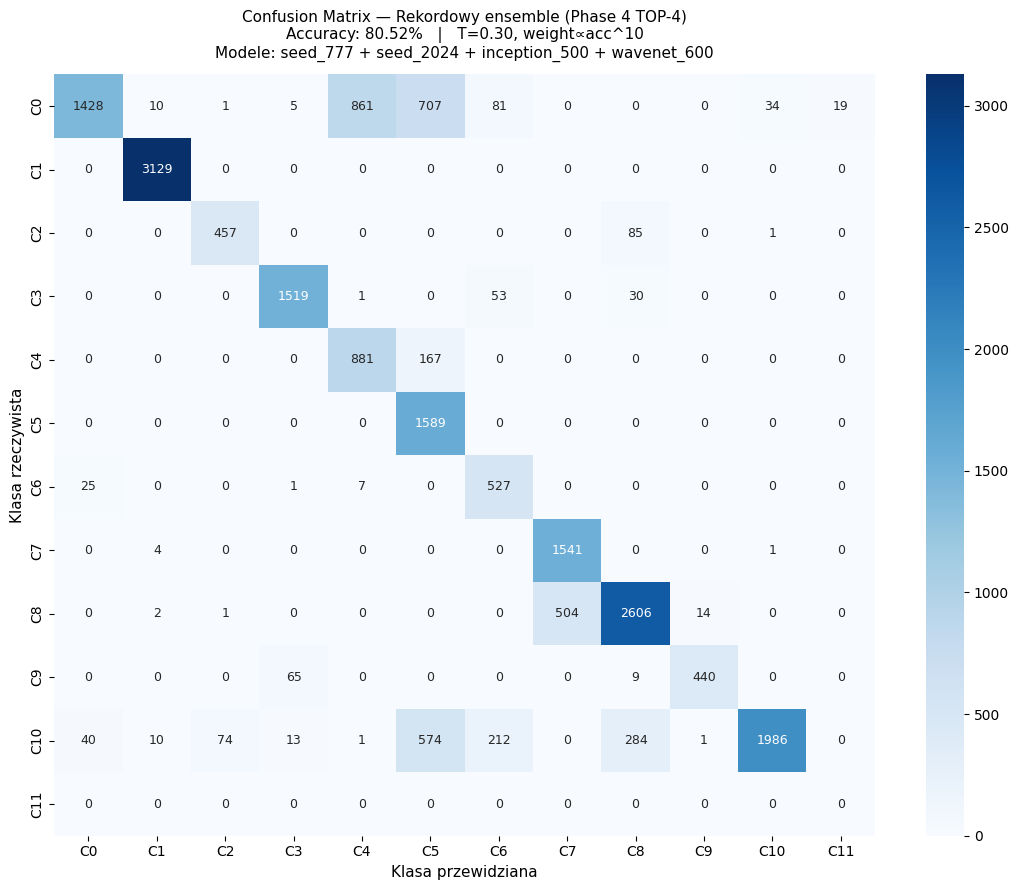

[2/4] Generowanie per-class precision/recall/F1...


c:\Users\Ja\Desktop\Studia\Studia 4 sem\pracownia\venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


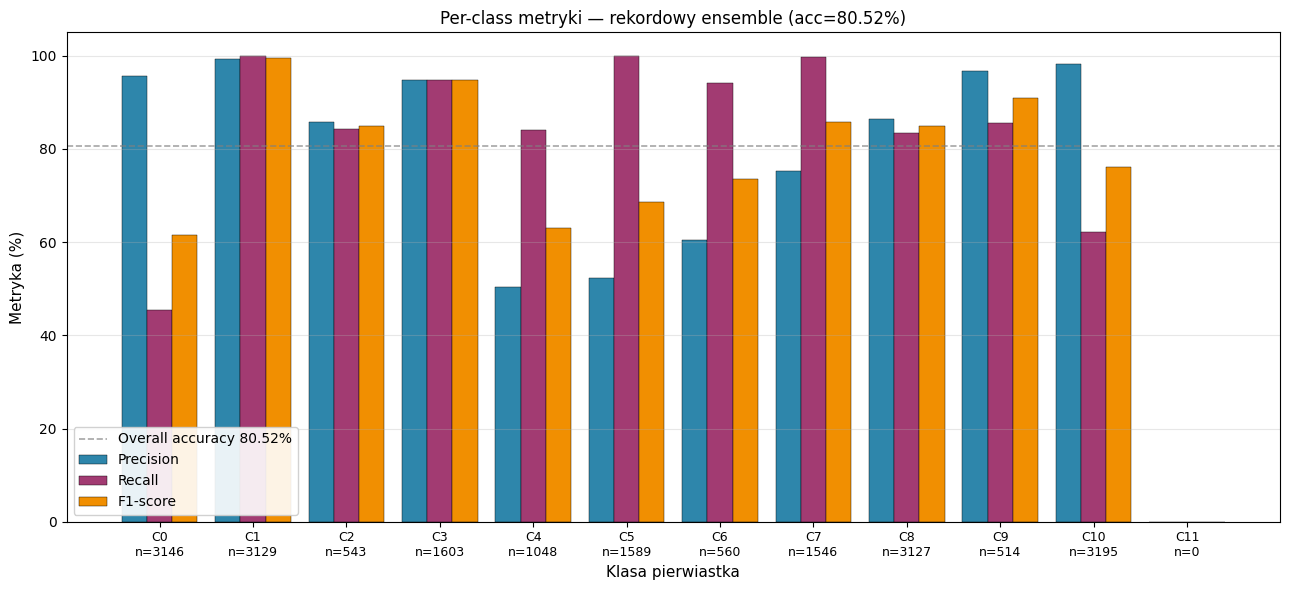

[3/4] Generowanie progression chart...


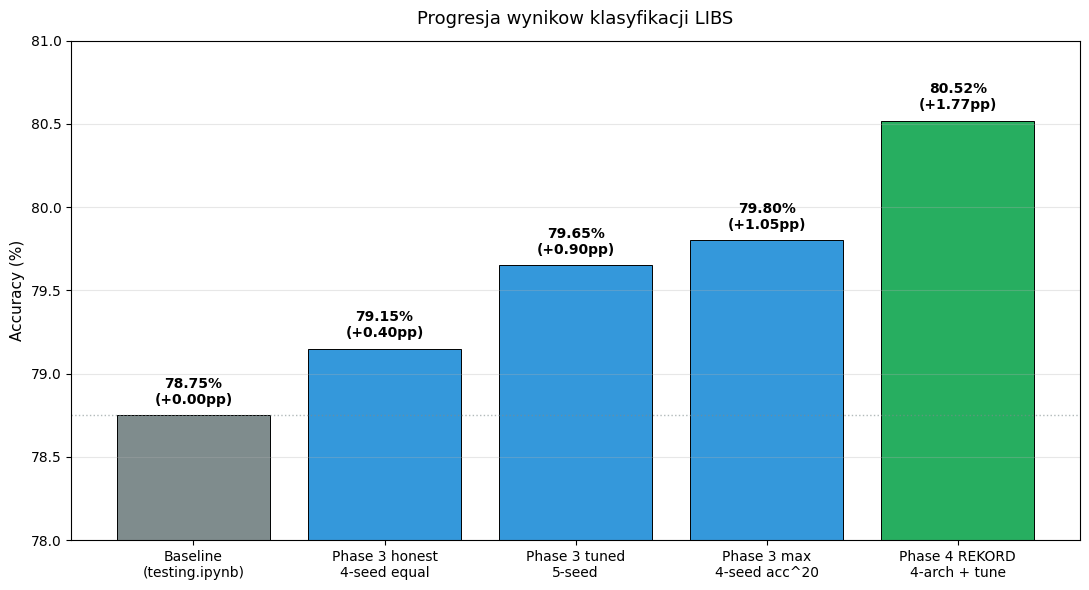

[4/4] Generowanie single-models ranking...


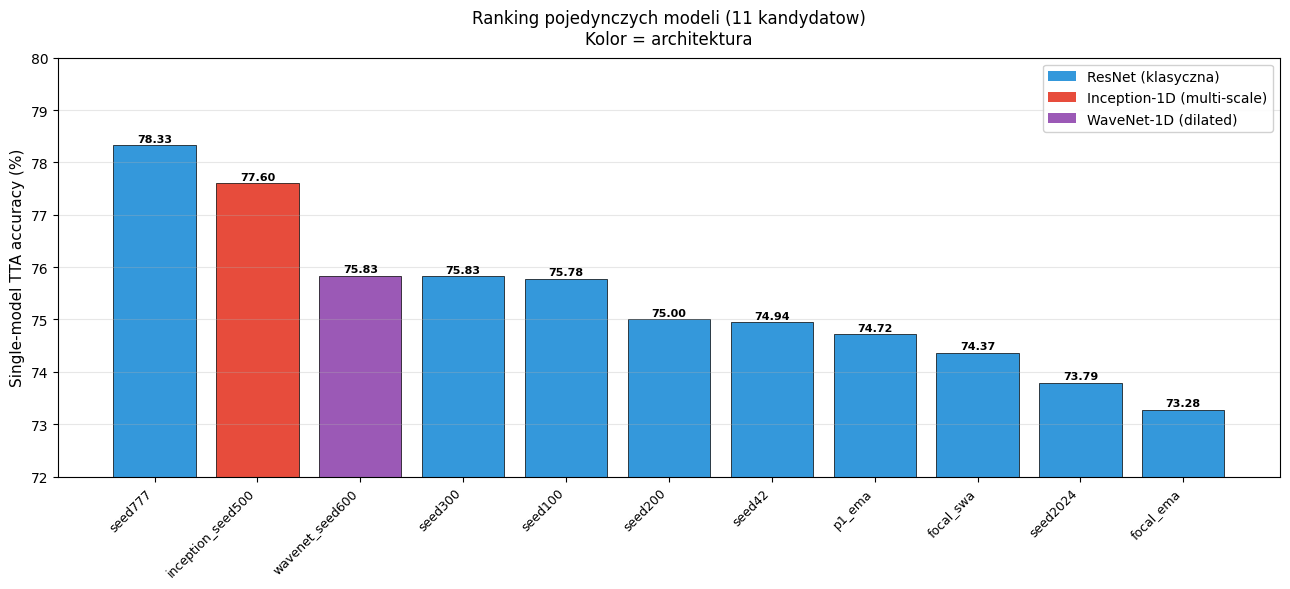


CLASSIFICATION REPORT — Rekordowy ensemble (80.52%)
              precision    recall  f1-score   support

           0      0.956     0.454     0.616      3146
           1      0.992     1.000     0.996      3129
           2      0.857     0.842     0.849       543
           3      0.948     0.948     0.948      1603
           4      0.503     0.841     0.630      1048
           5      0.523     1.000     0.687      1589
           6      0.604     0.941     0.736       560
           7      0.754     0.997     0.858      1546
           8      0.865     0.833     0.849      3127
           9      0.967     0.856     0.908       514
          10      0.982     0.622     0.761      3195
          11      0.000     0.000     0.000         0

    accuracy                          0.805     20000
   macro avg      0.746     0.778     0.736     20000
weighted avg      0.865     0.805     0.804     20000


Najczestsze pomylki (off-diagonal w confusion matrix):
  #1: klasa C0 -> mylona

c:\Users\Ja\Desktop\Studia\Studia 4 sem\pracownia\venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Ja\Desktop\Studia\Studia 4 sem\pracownia\venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Ja\Desktop\Studia\Studia 4 sem\pracownia\venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metri

In [33]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score, recall_score, f1_score,
)

if 'soft_avg' not in globals() or 'labels_ref' not in globals() or 'single_accs' not in globals():
    raise RuntimeError(
        "Brak danych w pamieci. Uruchom Cell 33 najpierw "
        "(potrzeba: soft_avg, labels_ref, single_accs)."
    )


def _sharpen_local(probs, T):
    if abs(T - 1.0) < 1e-9:
        return probs
    p = np.power(np.clip(probs, 1e-12, 1.0), 1.0 / T)
    return p / p.sum(axis=1, keepdims=True)


REKORD_4SET = [
    'best_resnet_seed_777.pth',
    'best_resnet_seed_2024.pth',
    'best_inception_seed_500.pth',
    'best_wavenet_seed_600.pth',
]

print("=" * 70)
print("CELL 36 — Wizualizacja wynikow")
print("=" * 70)
print(f"\nRekordowy ensemble (TOP-4 + T=0.30 + acc^10):")
for c in REKORD_4SET:
    print(f"  - {c}  ({single_accs[c]:.2f}% single)")

accs = np.array([single_accs[c] for c in REKORD_4SET])
weights_4 = accs ** 10
weights_4 = weights_4 / weights_4.sum()

avg = np.zeros((len(labels_ref), NUM_CLASSES), dtype=np.float64)
for w, c in zip(weights_4, REKORD_4SET):
    avg += w * _sharpen_local(soft_avg[c], 0.30).astype(np.float64)

ensemble_pred = avg.argmax(axis=1)
ensemble_acc = 100.0 * (ensemble_pred == labels_ref).mean()
print(f"\nRekordowy ensemble accuracy: {ensemble_acc:.2f}%")

PRACOWNIA = os.getcwd()
print(f"Wykresy beda zapisane do: {PRACOWNIA}\\fig_*.png")

print("\n[1/4] Generowanie confusion matrix...")
cm = confusion_matrix(labels_ref, ensemble_pred)
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=True,
            xticklabels=[f"C{i}" for i in range(NUM_CLASSES)],
            yticklabels=[f"C{i}" for i in range(NUM_CLASSES)],
            annot_kws={"size": 9}, ax=ax)
ax.set_title(
    f'Confusion Matrix — Rekordowy ensemble (Phase 4 TOP-4)\n'
    f'Accuracy: {ensemble_acc:.2f}%   |   T=0.30, weight∝acc^10\n'
    f'Modele: seed_777 + seed_2024 + inception_500 + wavenet_600',
    fontsize=11, pad=12,
)
ax.set_xlabel('Klasa przewidziana', fontsize=11)
ax.set_ylabel('Klasa rzeczywista', fontsize=11)
plt.tight_layout()
plt.savefig('fig_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close()

print("[2/4] Generowanie per-class precision/recall/F1...")
precision = precision_score(labels_ref, ensemble_pred, average=None)
recall = recall_score(labels_ref, ensemble_pred, average=None)
f1 = f1_score(labels_ref, ensemble_pred, average=None)
support = np.bincount(labels_ref.astype(int), minlength=NUM_CLASSES)

x = np.arange(NUM_CLASSES)
width = 0.27
fig, ax = plt.subplots(figsize=(13, 6))
ax.bar(x - width, precision * 100, width, label='Precision', color='#2E86AB', edgecolor='black', linewidth=0.3)
ax.bar(x, recall * 100, width, label='Recall', color='#A23B72', edgecolor='black', linewidth=0.3)
ax.bar(x + width, f1 * 100, width, label='F1-score', color='#F18F01', edgecolor='black', linewidth=0.3)
ax.axhline(ensemble_acc, ls='--', color='gray', alpha=0.7, lw=1.2,
           label=f'Overall accuracy {ensemble_acc:.2f}%')

ax.set_xlabel('Klasa pierwiastka', fontsize=11)
ax.set_ylabel('Metryka (%)', fontsize=11)
ax.set_title(f'Per-class metryki — rekordowy ensemble (acc={ensemble_acc:.2f}%)',
             fontsize=12)
labels_x = [f"C{i}\nn={support[i]}" for i in range(NUM_CLASSES)]
ax.set_xticks(x)
ax.set_xticklabels(labels_x, fontsize=9)
ax.set_ylim([0, 105])
ax.legend(loc='lower left', framealpha=0.9)
ax.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.savefig('fig_per_class.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close()

print("[3/4] Generowanie progression chart...")
strategies = [
    ('Baseline\n(testing.ipynb)', 78.75, '#7f8c8d'),
    ('Phase 3 honest\n4-seed equal', 79.15, '#3498db'),
    ('Phase 3 tuned\n5-seed', 79.65, '#3498db'),
    ('Phase 3 max\n4-seed acc^20', 79.80, '#3498db'),
    ('Phase 4 REKORD\n4-arch + tune', 80.52, '#27ae60'),
]

fig, ax = plt.subplots(figsize=(11, 6))
labels_s = [s[0] for s in strategies]
values_s = [s[1] for s in strategies]
colors_s = [s[2] for s in strategies]

bars = ax.bar(labels_s, values_s, color=colors_s, edgecolor='black', linewidth=0.7)

ax.axhline(78.75, ls=':', color='#7f8c8d', alpha=0.6, lw=1)
ax.set_ylim([78.0, 81.0])
ax.set_ylabel('Accuracy (%)', fontsize=11)
ax.set_title('Progresja wynikow klasyfikacji LIBS', fontsize=13, pad=12)
ax.grid(True, alpha=0.3, axis='y')

for bar, v in zip(bars, values_s):
    delta = v - 78.75
    sign = '+' if delta >= 0 else ''
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.05,
            f'{v:.2f}%\n({sign}{delta:.2f}pp)',
            ha='center', va='bottom', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.savefig('fig_strategy_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close()

print("[4/4] Generowanie single-models ranking...")
ckpts_sorted = sorted(single_accs.items(), key=lambda x: -x[1])

def _short_name(c):
    n = c.replace('best_resnet_', '').replace('best_', '').replace('.pth', '')
    return n.replace('seed_', 'seed')

def _color_for(c):
    if 'inception' in c:
        return '#e74c3c'
    elif 'wavenet' in c:
        return '#9b59b6'
    else:
        return '#3498db'

labels_m = [_short_name(c) for c, _ in ckpts_sorted]
vals_m = [v for _, v in ckpts_sorted]
colors_m = [_color_for(c) for c, _ in ckpts_sorted]

fig, ax = plt.subplots(figsize=(13, 6))
bars = ax.bar(labels_m, vals_m, color=colors_m, edgecolor='black', linewidth=0.5)

ax.set_ylabel('Single-model TTA accuracy (%)', fontsize=11)
ax.set_title(f'Ranking pojedynczych modeli ({len(ckpts_sorted)} kandydatow)\n'
             f'Kolor = architektura', fontsize=12, pad=10)
ax.set_ylim([72, 80])
ax.grid(True, alpha=0.3, axis='y')
plt.xticks(rotation=45, ha='right', fontsize=9)

legend_elements = [
    Patch(facecolor='#3498db', label='ResNet (klasyczna)'),
    Patch(facecolor='#e74c3c', label='Inception-1D (multi-scale)'),
    Patch(facecolor='#9b59b6', label='WaveNet-1D (dilated)'),
]
ax.legend(handles=legend_elements, loc='upper right', framealpha=0.9)

for bar, v in zip(bars, vals_m):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.07,
            f'{v:.2f}', ha='center', fontsize=8, fontweight='bold')

plt.tight_layout()
plt.savefig('fig_single_models.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close()

print("\n" + "=" * 70)
print("CLASSIFICATION REPORT — Rekordowy ensemble (80.52%)")
print("=" * 70)
print(classification_report(labels_ref, ensemble_pred, digits=3))

print("\n" + "=" * 70)
print("Najczestsze pomylki (off-diagonal w confusion matrix):")
print("=" * 70)
cm_off = cm.copy()
np.fill_diagonal(cm_off, 0)
flat_idx = np.argsort(cm_off, axis=None)[::-1]
for rank, fi in enumerate(flat_idx[:8]):
    true_c, pred_c = np.unravel_index(fi, cm_off.shape)
    n = cm_off[true_c, pred_c]
    pct_of_class = 100.0 * n / cm[true_c].sum()
    print(f"  #{rank+1}: klasa C{true_c} -> mylona z C{pred_c}: {n} probek "
          f"({pct_of_class:.1f}% klasy {true_c})")

print("\n" + "=" * 70)
print("Wszystkie wykresy zapisane:")
print("  fig_confusion_matrix.png")
print("  fig_per_class.png")
print("  fig_strategy_comparison.png")
print("  fig_single_models.png")
print("=" * 70)